In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))

import transformers
from packaging.version import Version
if Version(transformers.__version__) > Version("5.10"):
    import src.utils.lxt_shim

### Sandbox

#### Load

In [2]:
import argparse
import os
import time
import traceback
import json
from typing import Any, Sequence


import numpy as np
import torch
from torch import Tensor
import yaml
from tqdm import tqdm
from PIL import ImageFilter
import pandas as pd
import scipy.stats as stats

# --- ABSTRACTED FACTORIES & UTILS ---
from src.datasets.factory import get_dataloader 
from src.utils.xai_utils import find_ynvqa_token_index, save_to_jsonl
from src.models.factory import load_vlm

# --- EXPLAINERS & METRICS ---
from src.metrics.shap_sii import eval_sii_auc_with_class
from src.metrics import FaithfulnessMetric
from src.utils.faithfulness_utils import (
    _reshape_pixels_back_faithfulness,
    _reshape_pixels_faithfulness,
    get_most_important_tokens_multimodal,
    make_blur_baseline,
    score_output,
    get_text_mask,
)

In [3]:

def load_yaml(file_path):
    with open(file_path, encoding="utf-8") as f:
        return yaml.safe_load(f)

model_name = "internvl_2b"
dataset_name = "mmstar"
gpu_id = 0


model_config = f"../configs/models/{model_name}.yaml"
model_config = load_yaml(model_config)

if dataset_name in ['repope', 'repope_oracle']:
    dataset_config = {
    "name": dataset_name,
    "data_path": "../datasets/repope",
    "pope_json_path": "../datasets/repope/repope_annotations",
    "pope_type": "all",
    "coco_split": "val2014",
    "batch_size": 1,
    }

else:

    dataset_config = f"../configs/datasets/{dataset_name}.yaml"
    dataset_config = load_yaml(dataset_config)



In [4]:
model_wrapper = load_vlm(
    model_config=model_config,
    attn_implementation="eager", 
    gpu_node=gpu_id,
    output_attentions=True
)


[*] Loading model architecture: OpenGVLab/InternVL3_5-2B-HF on GPU 0...


Loading weights:   0%|          | 0/753 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie model.language_model.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


In [5]:
dl = get_dataloader(dataset_config)

[*] Loading Dataset: mmstar


In [6]:
from src.utils.xai_utils import find_mcvqa_token_index, find_ynvqa_token_index

#### Sample

In [7]:

# Loop through the entire dataset's length
# for idx in range(len(dl.dataset)):
idx = 0
sample = dl.dataset[idx]
category = sample.get("category", None)

# Check if it matches our target
#if category == target_category:
    
img = sample.get("image", None)
# constraint = "\nAnswer directly with only the letter inside parentheses, and nothing else. \nAnswer:"

question = sample.get("question", None)
if dataset_name in ["repope", "repope_oracle"]:
    text = question
else:
    if model_config["name"] == "llava":
        constraint = "\nAnswer"
    else:
        constraint = "\nAnswer directly with only the letter inside parentheses, and nothing else."
    text = constraint + question
label = sample.get("label", None)

keyword=sample.get("object_name", None)
oracle_mask_2d=sample.get("pixel_oracle_mask", None)
mismatched_mask_2d=sample.get("distractor_mask", None)




In [8]:
model_config

{'name': 'internvl',
 'vlm_type': 'internvl_2b',
 'model_id': 'OpenGVLab/InternVL3_5-2B-HF',
 'trust_remote_code': False,
 'cam_target_layer': 'layers.7.post_attention_layernorm'}

In [9]:
for var in ['inputs', 'pred_results', 'xai_result', 'img_attrs', 'text_attrs']:
    if var in locals():
        del locals()[var]

In [10]:
import gc

gc.collect()
                        
torch.cuda.empty_cache()

In [11]:
sample

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=512x384>,
 'question': 'Which option describe the object relationship in the image correctly?\nOptions: A: The suitcase is on the book., B: The suitcase is beneath the cat., C: The suitcase is beneath the bed., D: The suitcase is beneath the book.',
 'label': 'A',
 'index': 0,
 'metadata': {'source': 'MMBench',
  'split': 'val',
  'image_path': 'images/0.jpg'},
 'category': 'coarse perception'}

In [12]:
model_wrapper.is_mcvqa = True

inputs = model_wrapper.get_inputs(img, text)
pred_results = model_wrapper.predict(inputs, return_logits=True)

[transformers] Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


In [13]:
print(pred_results["text"])

A: The suitcase is on the book.


In [14]:
if dataset_name in ["repope", "repope_all"]:
    decision_token = find_ynvqa_token_index(
                        pred_results["new_ids"],
                        text_answer=pred_results["text"],
                        tokenizer=model_wrapper.processor.tokenizer,
                    )
else:
    decision_token, _ = find_mcvqa_token_index(pred_results["new_ids"], model_wrapper.processor.tokenizer,
                                            choices=['a', 'b', 'c', 'd', 'e', 'f'])

if decision_token == -1:
    decision_token = 0

In [15]:
decision_token

0

In [16]:
model_wrapper.model_config = {
    "model_config": model_config,
    "attn_implementation": None,
    "gpu_node": gpu_id,
    "output_attentions": False
}

#### Generate explanations

In [17]:
from src.explainers.factory import get_explainer

exp = "fixlip"
explainer_path = f"../configs/explainers/{exp}.yaml"

explainer, explainer_name = get_explainer(
            explainer_path, model_wrapper, model_config
        )

In [18]:
target_indices = None
target_indices = [decision_token]

text_attrs, img_attrs = explainer.attribute(
    img,
    text=text,
    target_indices=target_indices,
    pred_results=pred_results,
    keyword=keyword,
    oracle_mask_2d=oracle_mask_2d,
    mismatched_mask_2d=mismatched_mask_2d,

)

OutOfMemoryError: CUDA out of memory. Tried to allocate 248.00 MiB. GPU 0 has a total capacity of 44.39 GiB of which 61.94 MiB is free. Process 854700 has 27.93 GiB memory in use. Including non-PyTorch memory, this process has 16.39 GiB memory in use. Of the allocated memory 14.47 GiB is allocated by PyTorch, and 1.42 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [19]:
inputs["pixel_values"].shape

torch.Size([1, 3, 448, 448])

In [22]:
text_attrs.device

device(type='cpu')

In [20]:
img_attrs.shape

torch.Size([1, 1, 448, 448])

In [ ]:
img_attrs.shape

torch.Size([1, 3, 448, 448])

In [21]:
from src.utils.faithfulness_utils import get_text_mask

model_type = getattr(model_wrapper.model.config, "model_type", "").lower()
semantic_mask = get_text_mask(inputs["input_ids"], model_type, model_wrapper.processor.tokenizer)

In [28]:
import torch

def build_object_semantic_mask(input_ids, tokenizer, object_name):
    """
    Dynamically finds the tokens corresponding to the 'object_name' within the full 
    tokenized prompt (including chat templates) and creates a boolean mask.
    
    Args:
        input_ids (Tensor): The tokenized input of shape (1, seq_len).
        tokenizer: The HuggingFace tokenizer associated with the VLM.
        object_name (str): The core object to isolate (e.g., "snowboard").
        
    Returns:
        Tensor: A boolean mask of shape (1, seq_len) where True indicates the object tokens.
    """
    device = input_ids.device
    mask = torch.zeros_like(input_ids, dtype=torch.bool, device=device)
    ids_list = input_ids[0].tolist()
    
    # 1. Reconstruct the full string while tracking the character span of each token
    current_str = ""
    token_char_spans = []
    
    for tid in ids_list:
        # We decode each token individually to see its exact string representation
        token_str = tokenizer.decode([tid], skip_special_tokens=False)
        start_char = len(current_str)
        current_str += token_str
        end_char = len(current_str)
        
        token_char_spans.append((start_char, end_char, token_str))
        
    # 2. Find the character position of the object in the full reconstructed string
    target_start = current_str.lower().find(object_name.lower())
    
    if target_start == -1:
        print(f"[Warning] Object '{object_name}' not found in the prompt sequence!")
        # Fallback: just activate the last few tokens before special tokens if not found
        return mask 
        
    target_end = target_start + len(object_name)
    
    # 3. Flag any token whose character span overlaps with the object's character span
    for i, (start, end, text) in enumerate(token_char_spans):
        # Math check for overlapping intervals
        if max(start, target_start) < min(end, target_end):
            # Exclude tokens that are purely whitespace (saves Shapley budget)
            if text.strip() != "":
                mask[0, i] = True
                
    # Quick debug print so you can verify it caught the right subwords
    active_tokens = [tokenizer.decode([ids_list[i]]) for i in range(len(ids_list)) if mask[0, i]]
    print(f"[*] Object '{object_name}' mapped to tokens: {active_tokens} (Total: {len(active_tokens)})")
                
    return mask

In [30]:
semantic_mask = build_object_semantic_mask(inputs["input_ids"],
                                           model_wrapper.processor.tokenizer,
                                            sample["object_name"])

[*] Object 'snowboard' mapped to tokens: [' snow', 'board'] (Total: 2)


In [28]:
model_wrapper.processor.batch_decode(inputs["input_ids"])

['<|im_start|>system\nYou are a helpful assistant.<|im_end|>\n<|im_start|>user\n<|vision_start|><|image_pad|><|image_pad|><|image_pad|><|image_pad|><|vision_end|>Is there a snowboard in the image?<|im_end|>\n<|im_start|>assistant\n']

#### Plausibility

In [ ]:
from src.models import QwenVLWrapper

model_wrapper = QwenVLWrapper(model, processor)


In [ ]:
from src.datasets import COCOGroundingDataset
from torch.utils.data import DataLoader

data_path = "../datasets/coco"
dataset = COCOGroundingDataset(data_path=data_path)

def collate_fn_custom(batch):
    # Standard collate fails on Dictionaries (category_masks) and Lists (all_captions)
    # So we write a simple one that just returns the list of items
    return batch[0] # Assumes batch_size=1

dl = DataLoader(dataset, collate_fn=collate_fn_custom)


In [ ]:
for sample in dl:
    img = sample["image"]
    text = "Write a one sentence caption"
    captions = sample["captions"]
    masks = sample["category_masks"]

    break

In [ ]:
inputs = model_wrapper.get_inputs(img, text)
pred_results = model_wrapper.predict(inputs, return_logits=True)

In [ ]:
from src.explainers import (CaptumExplainer, LXTExplainer, TAMExplainer,
                            LLaVACAMExplainer, RandomExplainer,
                            )

target_layer_name = "layers.7.post_attention_layernorm"

# explainer = LLaVACAMExplainer(model_wrapper=model_wrapper,
#                             target_layer_name=target_layer_name
#                             )

explainer = TAMExplainer(model_wrapper=model_wrapper,
                           # use_zennit=True,
                           )


In [ ]:
from src.metrics import PlausibilityMetric
from src.utils.plausibility_utils import OntologyMapper, ids_to_word_groups

# Setup Ontology Mapper for Plausibility (Assume dl.dataset has id2name)
category_dict = getattr(dl.dataset, "id2name", {})
mapper = OntologyMapper(coco_categories=category_dict, threshold=0.5)

plaus_metrics = PlausibilityMetric(
        ontology_mapper=mapper,
        category_dict=category_dict
    )

In [ ]:
tokens = pred_results["new_ids"].cpu().unsqueeze(0).tolist()
tokens

In [ ]:
words, tokens_id_groups = ids_to_word_groups(tokens, model_wrapper.processor)
words

In [ ]:
valid_words, target_indices = plaus_metrics.get_valid_targets(
                        words, tokens_id_groups, masks
                    )

In [ ]:
valid_words

In [ ]:
text_attrs, img_attrs = explainer.attribute(
                        img,
                        text=text,
                        target_indices=target_indices,
                        pred_results=pred_results,
                    )

In [ ]:
xai_result = {
        "inputs": inputs,
        "target_ids": pred_results["new_ids"].unsqueeze(0),
        "pixel_attribution": img_attrs, 
        "token_attribution": text_attrs,
        "valid_words": valid_words  # Crucial for Plausibility to map rows to words
    }



In [ ]:
from src.metrics import FaithfulnessMetric

# 5. Initialize Metrics
pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
tok = model_wrapper.processor.tokenizer
pad_token_id = tok.pad_token_id if tok.pad_token_id is not None else 0

faith_metrics = FaithfulnessMetric(
    perturbation_steps=pert_steps,
    pad_token_id=pad_token_id,
    special_token_ids=model_wrapper.special_token_ids,
    mask_value=0.0,
    filter_keywords=True,
)

In [ ]:
faith_sample = {"image": img, "text": text}

# 6. Compute Both Metrics Using the Exact Same Data!
faith_scores = faith_metrics.compute(model_wrapper, faith_sample, xai_result)
plaus_scores = plaus_metrics.compute(model_wrapper, sample, xai_result)


In [ ]:
faith_scores

#### Faithfulness

In [22]:
# 4. Metric Hyperparameters
pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
device = model_wrapper.device
tok = model_wrapper.processor.tokenizer
pad_token_id = tok.pad_token_id if tok.pad_token_id is not None else 0
special_token_ids = model_wrapper.special_token_ids
filter_keywords = True

faith_metrics = FaithfulnessMetric(
    perturbation_steps=pert_steps,
    pad_token_id=pad_token_id,
    special_token_ids=model_wrapper.special_token_ids,
    mask_value=0.0,
    filter_keywords=filter_keywords,
)

In [23]:
xai_result = {
    "inputs": inputs,
    "target_ids": pred_results["new_ids"].unsqueeze(0),
    "pixel_attribution": img_attrs[0:1],
    "token_attribution": text_attrs[0:1],
}

faith_sample ={"image": img, "text": sample["question"]}

scores = faith_metrics.compute(model_wrapper, faith_sample, xai_result, 
                               required_metrics=["auc", "curve"])

In [24]:
scores #  Random

{'time_img_pert': 1.8696393609861843,
 'img_raw_curve_del': [0.6484375,
  0.423828125,
  0.294921875,
  0.2001953125,
  0.1572265625,
  0.1005859375,
  0.08740234375,
  0.15234375,
  0.126953125,
  0.1591796875,
  0.166015625],
 'img_normalized_curve_del': [1.0,
  0.5344129800796509,
  0.26720649003982544,
  0.0708502009510994,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0],
 'img_raw_curve_ins': [0.166015625,
  0.146484375,
  0.212890625,
  0.3984375,
  0.455078125,
  0.609375,
  0.62109375,
  0.5625,
  0.66796875,
  0.6171875,
  0.6484375],
 'img_normalized_curve_ins': [0.0,
  0.0,
  0.09716599434614182,
  0.48178136348724365,
  0.5991902947425842,
  0.9190283417701721,
  0.9433198571205139,
  0.8218623399734497,
  1.0,
  0.9352226853370667,
  1.0],
 'img_norm_auc_del': 0.13724696673452855,
 'img_norm_auc_ins': 0.6297570880502462,
 'img_auc_del': 0.21098632812500004,
 'img_auc_ins': 0.46982421875,
 'time_tok_pert': 1.834415179968346,
 'tok_raw_del_curve': [1.0,
  1.0,
  1.0,
  1.0,

#### Visualization

In [45]:
from src.utils.viz_utils import XAIVisualizer
from src.utils.faithfulness_utils import get_text_mask

viz = XAIVisualizer(model_wrapper.processor)

In [46]:
token_attribution = text_attrs[0:1]
pixel_attribution = img_attrs[0:1]
target_ids = pred_results["new_ids"]

img_attrs = img_attrs.float()
text_attrs = text_attrs.float()

model_type = getattr(model_wrapper.model.config, "model_type", "").lower()
semantic_mask = get_text_mask(inputs["input_ids"],
                            model_type,
                            model_wrapper.processor.tokenizer)

In [47]:
viz.plot_text_attributions(
    text_attr=text_attrs, 
    input_ids=inputs["input_ids"], 
    target_ids=target_ids.unsqueeze(0),
    special_token_ids=model_wrapper.special_token_ids,
    semantic_mask=semantic_mask,
    target_indices=target_indices
)


TEXT ATTRIBUTIONS (Filtered & Normalized)


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
No,No (1.00),No,4.31,Is there a snow board in the image ?



IMAGE ATTRIBUTIONS

[*] Heatmap for generated token: 'No'


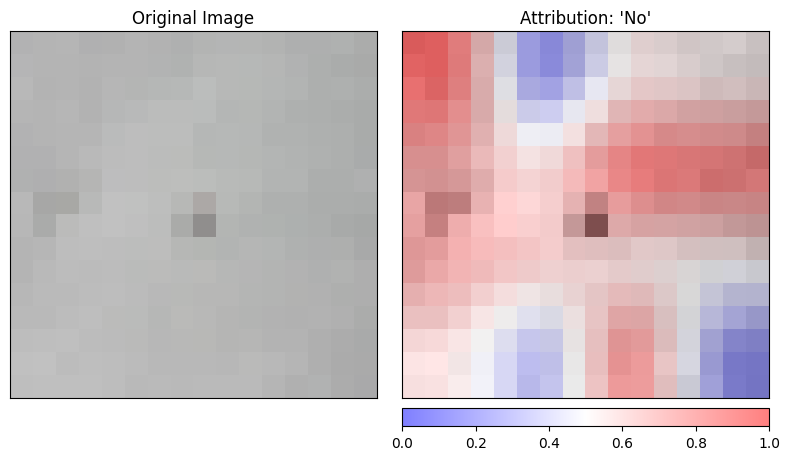

In [48]:
image_grid_thw = inputs.get("image_grid_thw", None)
viz.plot_image_attributions(img_attr=pixel_attribution,
                            original_image=img,
                            target_ids=target_ids.unsqueeze(0), 
                            image_grid_thw=image_grid_thw,
                            target_indices=target_indices
                            )

#### Generate plots

In [ ]:
import os, traceback
import torch
from PIL import Image
import gc
# Import your XAIVisualizer here
from src.utils.viz_utils import XAIVisualizer
from src.explainers.factory import get_explainer

def generate_qualitative_grid_on_the_fly(sample_idx, image,
                                        text, pred_results,
                                        model_wrapper, model_config,
                                        target_indices=0):
    model_name = model_config["name"]
    print(f"\n[==== Generating Heatmaps for Sample {sample_idx} | Model: {model_name} ====]")
    os.makedirs("figs", exist_ok=True)
    
    # ---------------------------------------------------------
    # STEP 1: Load your Model and Visualizer
    # ---------------------------------------------------------

    visualizer = XAIVisualizer(model_wrapper.processor)
    
    # Save the original image for the LaTeX grid
    original_image = image.convert("RGB")
    original_image.save(f"figs/qual_{sample_idx}_{model_name}_{dataset_name}_original.pdf", "PDF", resolution=300)

    # List the explainers exactly as your code expects them
    explainers = [
        "random",
        "llavacam", "rollout",
        "tam", "inputxgradients", "gradxrollout",
        "gradcam", "integratedgradients", "lxt", 
    ]
    
    for exp in explainers:
        print(f"  -> Computing {exp}...")
        
        try:
            # ---------------------------------------------------------
            # STEP 2: Compute the Attribution
            # ---------------------------------------------------------
            # TODO: Initialize your explainer wrapper
            explainer_path = f"../configs/explainers/{exp}.yaml"

            explainer, explainer_name = get_explainer(
                        explainer_path, model_wrapper, model_config
                    )
                        
            # (Make sure to pass the image, prompt, and whatever else your explainer needs)
            text_attr, img_attr = explainer.attribute(
                                            img,
                                            text=text,
                                            target_indices=target_indices,
                                            pred_results=pred_results,
                                            # keyword=keyword,
                                            # oracle_mask_2d=oracle_mask_2d,
                                            # mismatched_mask_2d=mismatched_mask_2d,

                                        )
            
            # ---------------------------------------------------------
            # STEP 3: Save the PDF using our modified Visualizer
            # ---------------------------------------------------------
            
            save_name = explainer_name.lower().replace(" ", "_")
            save_path = f"figs/qual_{sample_idx}_{model_name}_{dataset_name}_{save_name}"
            img_save_path = f"{save_path}_img.pdf"
            target_ids = pred_results["new_ids"].unsqueeze(0)
            
            # visualizer._plot_image_attributions(
            #     img_attr=img_attr.float(),
            #     original_image=original_image,
            #     target_ids=target_ids,
            #     explainer_name=explainer_name,
            #     save_path=img_save_path
            # )

            model_type = getattr(model_wrapper.model.config, "model_type", "").lower()
            semantic_mask = get_text_mask(inputs["input_ids"],
                                        model_type,
                                        model_wrapper.processor.tokenizer)
            
            # # 3. Save the Colored Text Highlights (Bottom)
            # txt_save_path = f"{save_path}_txt.pdf"
            # visualizer.save_text_highlight_pdf( # <--- Calling your new function here
            #     text_attr=text_attr,
            #     input_ids=inputs["input_ids"],
            #     save_path=txt_save_path,
            #     semantic_mask=semantic_mask,
            #     special_token_ids=model_wrapper.special_token_ids

            # )

            visualizer.save_combined_highlight_pdf(
                img_attr=img_attr,
                text_attr=text_attr,
                original_image=original_image,
                input_ids=inputs["input_ids"],       # Pass your tokenized inputs
                target_ids=target_ids,     # Pass your target tokens
                explainer_name=explainer_name,
                save_path=img_save_path,
                semantic_mask=semantic_mask,
                special_token_ids=model_wrapper.special_token_ids
            )

            
            # ---------------------------------------------------------
            # STEP 4: VRAM Management (CRITICAL)
            # ---------------------------------------------------------
            # Gradient-based explainers hold massive computation graphs in memory.
            # You MUST delete them and empty the cache before the next loop iteration.
            del explainer
            del img_attr
            gc.collect()
            torch.cuda.empty_cache()
            
        except Exception as e:
            print(f"[!] Failed to compute {exp} for sample {sample_idx}: {e}")
            traceback.print_exc()

    print(f"[+] All grid images generated successfully for Sample {sample_idx}!")



In [318]:
generate_qualitative_grid_on_the_fly(sample_idx=idx, image=img,
                                     text=text, pred_results=pred_results,
                                     model_wrapper=model_wrapper,
                                     model_config=model_config,
                                     target_indices=[decision_token])


[==== Generating Heatmaps for Sample 0 | Model: llava ====]
  -> Computing random...
  -> Computing llavacam...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)
/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/captum/attr/_utils/visualization.py:51: UserWarning: Attempting to normalize by value approximately 0, visualized resultsmay be misleading. This likely means that attribution values are allclose to 0.
  warnings.warn(


  -> Computing rollout...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/captum/attr/_utils/visualization.py:51: UserWarning: Attempting to normalize by value approximately 0, visualized resultsmay be misleading. This likely means that attribution values are allclose to 0.
  warnings.warn(


  -> Computing tam...
  -> Computing inputxgradients...


...

  -> Computing integratedgradients...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


  -> Computing lxt...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1864: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


[+] All grid images generated successfully for Sample 0!


### ShapIQ

In [ ]:
import numpy as np
import torch
import shapiq

from src.explainers import BaseExplainer
from src.models import BaseVLMWrapper
from src.utils.faithfulness_utils import pred_probs # Ensure this is imported!


class VLMTokenGame(shapiq.Game):
    def __init__(self, n_players, explainer, base_inputs, target_ids, real_idx, model_type, num_features, num_valid_tokens, valid_token_indices):
        super().__init__(n_players, normalize=False)
        self.explainer = explainer
        self.base_inputs = base_inputs
        self.target_ids = target_ids
        self.real_idx = real_idx
        self.model_type = model_type
        self.num_features = num_features
        self.num_valid_tokens = num_valid_tokens
        self.valid_token_indices = valid_token_indices

    def value_function(self, coalitions: np.ndarray) -> np.ndarray:
        probs = self.explainer._batched_evaluate_with_cache(
            coalitions, 
            self.base_inputs, 
            self.target_ids,
            self.model_type, 
            self.num_features, 
            self.num_valid_tokens,
            self.valid_token_indices
        )
        values = probs[:, self.real_idx]
        return values.float().detach().cpu().numpy()


class ShapIQExplainer(BaseExplainer):
    def __init__(
        self, 
        model_wrapper: BaseVLMWrapper, 
        budget: int = 256,
        batch_size: int = 8, 
        mask_value: float = 0.0,
        seed: int = 42
    ):
        super().__init__(model_wrapper)
        self.budget = budget
        self.batch_size = batch_size
        self.mask_value = mask_value
        self.seed = seed

    def attribute(
        self,
        image,
        text: str,
        target_indices: int | list[int] | None = None,
        **kwargs,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        
        # 1. Base Forward Pass & Processing
        inputs = self.wrapper.get_inputs(image, text)
        pixel_values = inputs["pixel_values"]
        input_ids = inputs["input_ids"]
        
        pred_results = kwargs.get("pred_results")
        if pred_results is None:
            pred_results = self.wrapper.predict(inputs, return_logits=True, **kwargs)
            
        new_ids = pred_results["new_ids"]
        if new_ids.dim() > 1: new_ids = new_ids[0]
        
        indices_to_compute = target_indices if isinstance(target_indices, list) else [target_indices] if target_indices is not None else list(range(len(new_ids)))
        num_targets = len(indices_to_compute)
        target_tokens = new_ids[indices_to_compute]
        target_ids_expanded = new_ids.unsqueeze(0)

        # 2. Extract Architectural Shapes
        model_type = getattr(self.wrapper.model.config, "model_type", "").lower()
        
        if "internvl" in model_type:
            if inputs["pixel_values"].ndim == 4: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, num_features, C, H, W = inputs["pixel_values"].shape
        elif "qwen" in model_type:
            if inputs["pixel_values"].ndim == 2: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, num_features, patch_dim = inputs["pixel_values"].shape
        else:
            if inputs["pixel_values"].ndim == 3: inputs["pixel_values"] = inputs["pixel_values"].unsqueeze(0)
            _, C, H, W = inputs["pixel_values"].shape
            num_features = H * W

        # --- THE FIX: PROTECT VISUAL & SPECIAL TOKENS ---
        valid_mask = torch.ones_like(input_ids[0], dtype=torch.bool)
        if self.wrapper.special_token_ids is not None:
            for skip_id in self.wrapper.special_token_ids:
                valid_mask &= (input_ids[0] != skip_id)
                
        valid_token_indices = torch.where(valid_mask)[0]
        num_valid_tokens = len(valid_token_indices)
        
        # The game now ONLY considers images patches and valid text words!
        n_players = num_features + num_valid_tokens

        # 3. Setup SHAP Accumulators & Initialize Cache
        pixel_shap = []
        token_shap = []
        self.coalition_cache = {}

        # 4. shapiq Execution Loop
        for t_idx, real_idx in enumerate(indices_to_compute):
            game = VLMTokenGame(
                n_players=n_players,
                explainer=self,
                base_inputs=inputs,
                target_ids=target_ids_expanded,
                real_idx=real_idx,
                model_type=model_type,
                num_features=num_features,
                num_valid_tokens=num_valid_tokens,
                valid_token_indices=valid_token_indices
            )
            
            approximator = shapiq.approximator.RegressionFSII(n=n_players, max_order=1, random_state=self.seed)
            ivs = approximator.approximate(self.budget, game)
            
            # Extract values for Pixels
            p_s = [ivs[(i,)] for i in range(num_features)]
            pixel_shap.append(p_s)
            
            # --- THE FIX: MAP TEXT SHAP BACK TO FULL SEQUENCE ---
            # Fill the full seq_len with 0.0s, and only overwrite the valid words with their SHAP score
            t_s = [0.0] * input_ids.shape[1]
            for j, real_seq_idx in enumerate(valid_token_indices.cpu().numpy()):
                t_s[real_seq_idx] = ivs[(num_features + j,)]
            token_shap.append(t_s)

        # 5. Format to Tensors and Standard Spatial Shapes
        pixel_shap_tensor = torch.tensor(pixel_shap, device=self.device, dtype=torch.float32)
        token_shap_tensor = torch.tensor(token_shap, device=self.device, dtype=torch.float32)
        
        print(pixel_shap_tensor.shape)

        pixel_attributions = self._reshape_to_spatial(pixel_shap_tensor, model_type, inputs)

        del self.coalition_cache 

        return token_shap_tensor, pixel_attributions


    # -------------------------------------------------------------------------
    # BATCHING & CACHING LOGIC
    # -------------------------------------------------------------------------

    def _batched_evaluate_with_cache(self, coalitions, base_inputs, target_ids, model_type, num_features, num_valid_tokens, valid_token_indices):
        keys = [tuple(c.tolist()) for c in coalitions]
        missing_indices = [i for i, k in enumerate(keys) if k not in self.coalition_cache]
        
        if missing_indices:
            missing_coalitions = coalitions[missing_indices]
            budget = len(missing_coalitions)
            
            p_mask_all = torch.tensor(missing_coalitions[:, :num_features], device=self.device, dtype=torch.int32)
            t_mask_all = torch.tensor(missing_coalitions[:, num_features:], device=self.device, dtype=torch.int32)
            
            for batch_start in range(0, budget, self.batch_size):
                current_bs = min(self.batch_size, budget - batch_start)
                batch_end = batch_start + current_bs
                
                p_mask = p_mask_all[batch_start:batch_end]
                t_mask = t_mask_all[batch_start:batch_end]
                
                masked_kwargs, new_input_ids, masked_pixels = self._apply_batched_masks(
                    base_inputs, target_ids, p_mask, t_mask, model_type, current_bs, valid_token_indices
                )
                
                with torch.no_grad():
                    log_probs = pred_probs(
                        model=self.wrapper,
                        inputs=masked_kwargs,
                        new_input_ids=new_input_ids,
                        pixel_values=masked_pixels,
                        output_ids=target_ids.expand(current_bs, -1)
                    )
                    probs = torch.exp(log_probs)
                
                for idx_in_batch in range(current_bs):
                    global_idx = missing_indices[batch_start + idx_in_batch]
                    k = keys[global_idx]
                    self.coalition_cache[k] = probs[idx_in_batch]

        ret = torch.stack([self.coalition_cache[k] for k in keys], dim=0)
        return ret


    def _apply_batched_masks(self, base_inputs, target_ids, p_mask, t_mask, model_type, bs, valid_token_indices):
        # 1. Text Masking (THE VECTORIZED FIX)
        input_ids = base_inputs["input_ids"].expand(bs, -1).clone()
        pad_id = self.wrapper.processor.tokenizer.pad_token_id or 0
        
        # t_mask is (bs, num_valid_tokens). We broadcast valid_token_indices to the batch
        idx_expanded = valid_token_indices.unsqueeze(0).expand(bs, -1)
        replace_mask = torch.zeros_like(input_ids, dtype=torch.bool)
        
        # Scatter the 0s (masked tokens) onto the full sequence boolean mask
        replace_mask.scatter_(1, idx_expanded, t_mask == 0)
        input_ids[replace_mask] = pad_id
        
        target_ids_expanded = target_ids.expand(bs, -1)
        new_input_ids = torch.cat([input_ids, target_ids_expanded], dim=1)

        # 2. Image Masking (Ironclad checks included!)
        base_pixels = base_inputs["pixel_values"]
        if "internvl" in model_type and base_pixels.ndim == 4: base_pixels = base_pixels.unsqueeze(0)
        elif "qwen" in model_type and base_pixels.ndim == 2: base_pixels = base_pixels.unsqueeze(0)
        elif "llava" in model_type and base_pixels.ndim == 3: base_pixels = base_pixels.unsqueeze(0)
            
        pixel_values = base_pixels.expand(bs, *base_pixels.shape[1:]).clone()
        
        if "internvl" in model_type:
            expanded_mask = p_mask.view(bs, -1, 1, 1, 1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))
        elif "qwen" in model_type:
            expanded_mask = p_mask.view(bs, -1, 1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))
        else: # LLaVA
            _, C, H, W = pixel_values.shape
            expanded_mask = p_mask.view(bs, 1, H, W).expand(-1, C, -1, -1)
            pixel_values = torch.where(expanded_mask == 1, pixel_values, torch.tensor(self.mask_value, device=self.device, dtype=pixel_values.dtype))

        # 3. Hardware Grids
        masked_kwargs = {
            k: v.repeat(bs, 1) if k == "image_grid_thw" else v 
            for k, v in base_inputs.items() 
            if k not in ["input_ids", "pixel_values", "attention_mask"]
        }

        return masked_kwargs, new_input_ids, pixel_values

    def _reshape_to_spatial(self, pixel_shap, model_type, inputs):
        num_targets = pixel_shap.shape[0]
        if "internvl" in model_type:
            _, _, _, H, W = inputs["pixel_values"].shape
            global_tile_shap = pixel_shap[:, -1].view(num_targets, 1, 1)
            return global_tile_shap.expand(-1, H, W)
        elif "qwen" in model_type:
            if "image_grid_thw" in inputs:
                grid_thw = inputs["image_grid_thw"][0].cpu().numpy().tolist()
                H, W = grid_thw[1], grid_thw[2]
                return pixel_shap.view(num_targets, H, W)
            else:
                return pixel_shap 
        else: 
            _, _, H, W = inputs["pixel_values"].shape
            return pixel_shap.view(num_targets, H, W)


In [ ]:
from src.models import QwenVLWrapper

model_wrapper = QwenVLWrapper(model, processor)


In [ ]:
import time

from torch.utils.data import DataLoader
from src.datasets import POPEGroundingDataset
from src.utils.plausibility_utils import OntologyMapper, ids_to_word_groups, pool_heatmaps

data_path = "../datasets/repope"
pope_json_path = os.path.join(data_path, "repope_annotations")
pope_type = "random"
coco_split = "val2014"

dataset = POPEGroundingDataset(data_path=data_path,
                               pope_json_path=pope_json_path,
                               pope_type=pope_type,
                               coco_split=coco_split)

def collate_fn_custom(batch):
    # Standard collate fails on Dictionaries (category_masks) and Lists (all_captions)
    # So we write a simple one that just returns the list of items
    return batch[0] # Assumes batch_size=1

dl = DataLoader(dataset, collate_fn=collate_fn_custom)

# category = dataset.id2name
# mapper = OntologyMapper(coco_categories=category, threshold=0.5)



In [ ]:
for sample in dl:
    img = sample["image"]
    core_question = sample["question"]
    # q = "Write a one sentence caption"
    prefix = "Answer strictly this question with yes or no: "
    text = prefix + core_question
    text = core_question
    # captions = sample["captions"]
    # masks = sample["category_masks"]

    break


In [ ]:
torch.cuda.empty_cache()

In [ ]:
inputs = model_wrapper.get_inputs(img, text)
pred_results = model_wrapper.predict(inputs, return_logits=True)


In [ ]:
game = GenerativeVLMGame(
    model_wrapper=model_wrapper, 
    image=img, 
    text=text,
    patch_group_size=4,
    target_ids=pred_results["new_ids"], 
    target_seq_index=0 # Explain the 1st generated token!
)

In [ ]:
approximator = shapiq.ProxySPEX(
    n=game.n_players,
    max_order=2,     
    index="FSII",    # Use "FBII" if you prefer Banzhaf interactions
    random_state=42
)

# 3. Let ProxySPEX handle EVERYTHING!
# It will generate its own Fourier-optimized masks, run our fast batched VLM Game,
# train its internal LightGBM proxy, and instantly extract the 2D interaction matrix.
interaction_values = approximator.approximate(
    budget=5, 
    game=game
)



In [ ]:
print(interaction_values)

In [ ]:
# 2. Initialize FIxLIP (with the exact player counts the Game calculated)
fixlip = FIxLIP(
    n_players_image=game.n_players_image, 
    n_players_text=game.n_players_text, 
    mode="banzhaf", 
    max_order=1
)

In [ ]:
# 3. Call approximate_crossmodal exactly like they do in their docs!
interaction_values = fixlip.approximate_crossmodal(
    game=game, 
    budget=4, 
    approximation_type="proxyshap"
)

In [ ]:
import math


print (math.comb(100, 50))

In [ ]:
77*33*32

In [ ]:
2**12

In [ ]:
print(interaction_values)

In [ ]:
shapiq.network_plot(
    first_order_values=interaction_values.get_n_order_values(1),
    second_order_values=interaction_values.get_n_order_values(2)
)
# or use
interaction_values.plot_network()

In [ ]:
# explainer = ShapIQExplainer(model_wrapper,
#                             budget=5,
#                             )

explainer = FIxLIPExplainer(model_wrapper,
                            budget=1024,
                            approximation_type="original",
                            )

In [ ]:
target_indices = None
# target_indices = 0
target_indices = [0]

text_attrs, img_attrs = explainer.attribute(image=img,
                                    text=text,
                                    target_indices=target_indices,
                                    pred_results=pred_results,
                                    )

In [ ]:
text_attrs.shape

In [ ]:
img_attrs.shape

#### Visualization

In [ ]:
from src.utils.xai_utils import XAIVisualizer

viz = XAIVisualizer(processor)

In [ ]:
token_attribution = text_attrs[0:1]
pixel_attribution = img_attrs[0:1]
target_ids = pred_results["new_ids"]

img_attrs = img_attrs.float()
text_attrs = text_attrs.float()

In [ ]:
viz.plot_text_attributions(
    text_attr=text_attrs, 
    input_ids=inputs["input_ids"], 
    target_ids=target_ids.unsqueeze(0),
    special_token_ids=model_wrapper.special_token_ids,
    semantic_mask=None,
    target_indices=target_indices
)

In [ ]:
image_grid_thw = inputs.get("image_grid_thw", None)
viz.plot_image_attributions(img_attr=img_attrs,
                            original_image=img,
                            target_ids=target_ids.unsqueeze(0), 
                            image_grid_thw=image_grid_thw,
                            target_indices=target_indices
                            )

### Analysis

In [5]:
import os
import glob
import json
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata, friedmanchisquare, wilcoxon
import itertools

def load_all_benchmark_data(base_dir="logs/results",
                            #dataset_name="repope_all"
                            ):
    """
    Crawls the directory structure to load all JSONL files, 
    automatically extracting the Model and Dataset from folder names.
    """
    all_data = []
    # Adjust this glob pattern based on your actual folder structure!
    # e.g., logs/llava/pope/ig_results.jsonl
    search_pattern = os.path.join(base_dir, "*", "*", "*.jsonl")
    file_list = glob.glob(search_pattern)
    
    print(f"[*] Found {len(file_list)} result files. Aggregating...")
    
    for file_path in file_list:
        # Extract metadata from the path 
        # (e.g., parts[-3] = model, parts[-2] = dataset)
        path_parts = os.path.normpath(file_path).split(os.sep)
        if len(path_parts) >= 3:
            model_name = path_parts[-3]
            dataset_name = path_parts[-2]
        else:
            model_name, dataset_name = "Unknown", "Unknown"
        
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    try:
                        row = json.loads(line)
                        # Ensure we don't overwrite if the JSON already has it
                        row['Model'] = row.get('model', model_name)
                        row['Dataset'] = row.get('dataset', dataset_name)
                        # Ensure explainer name is clean
                        row['Explainer'] = row.get('explainer', os.path.basename(file_path).replace('.jsonl', ''))
                        all_data.append(row)
                    except json.JSONDecodeError:
                        continue
                    
    df = pd.DataFrame(all_data)
    #df['Explainer'].replace('LXT', 'AttnLRP', inplace=True)
    df['Explainer'] = df['Explainer'].replace('LXT', 'AttnLRP')

    df["tok_srg_norm"] = df["tok_norm_auc_ins"] - df["tok_norm_auc_del"]
    df["tok_srg"] = df["tok_auc_ins"] - df["tok_auc_del"]
    df["img_srg_norm"] = df["img_norm_auc_ins"] - df["img_norm_auc_del"]
    df["img_srg"] = df["img_auc_ins"] - df["img_auc_del"]
    
    # Optional: Calculate combined AUPC metrics if you saved curves instead of raw AUCs
    # ... (Insert your trapezoid np.trapezoid code here if needed) ...
    
    return df


def find_motivating_examples(df, explainer_name='AttnLRP', dataset_filter=None,
                             auc_del_col = 'img_norm_auc_del',
                             syn_del_col = 'syn_synergy_auc'):
    """
    Mines the benchmark dataframe for perfect OR-gate and AND-gate examples.
    Assumes df has columns: 'sample_idx', 'Explainer', 'Prompt', 
    'auc_del_img' (unimodal), and 'auc_del_joint' (multimodal).
    """
    print(f"--- Mining Candidates for {explainer_name} ---")
    
    # Filter to a specific high-performing explainer so the heatmaps look good
    df_exp = df[df['Explainer'] == explainer_name].copy()

    # Apply the dataset filter if one is provided
    if dataset_filter:
        print(f"[*] Restricting search to Dataset: {dataset_filter}")
        df_exp = df_exp[df_exp['Dataset'] == dataset_filter]

    
    
    # ---------------------------------------------------------
    # 1. Find the OR-Gate (Redundant / Language Prior)
    # Confidence stays flat when image is deleted (img_norm_auc_del is HIGH)
    # But confidence crashes when both are deleted (auc_del_joint is LOW)
    # ---------------------------------------------------------
    or_gates = df_exp[
        (df_exp[auc_del_col] > 0.65) & 
        (df_exp[syn_del_col] < - 0.10)
    ].sort_values(auc_del_col, ascending=False)
    
    print(f"\n[*] Found {len(or_gates)} perfect OR-Gate candidates.")
    print("Top 3 OR-Gate Sample IDs:")
    print(or_gates[['sample_idx', 'question', auc_del_col,
                    'label', syn_del_col, 'Model']].head(3))

    # ---------------------------------------------------------
    # 2. Find the AND-Gate (Strict Visual Grounding)
    # Confidence crashes immediately when image is deleted auc_del_col is LOW)
    # ---------------------------------------------------------
    and_gates = df_exp[
        (df_exp[auc_del_col] < 0.15) &
        (df_exp[syn_del_col] > 0.20)
    ].sort_values(auc_del_col, ascending=True)
    
    print(f"\n[*] Found {len(and_gates)} perfect AND-Gate candidates.")
    print("Top 3 AND-Gate Sample IDs:")
    print(and_gates[['sample_idx', 'question', auc_del_col,
                    'label', 'Model']].head(3))
    
    return or_gates, and_gates


def mine_qualitative_archetypes(df):
    print("--- Mining Qualitative Examples for the Appendix ---")
    
    # Exact column names from your dataframe
    f_syn_col = 'syn_synergy_norm_auc'
    mui_col = 'img_srg_norm'
    mut_col = 'tok_srg_norm'
    
    # 1. Pivot the dataframe using pivot_table (Bulletproof against duplicates)
    # By including 'Model' in the index, we separate Qwen, LLaVA, and InternVL!
    pivot_df = pd.pivot_table(
        df,
        index=['sample_idx', 'Dataset', 'Model', 'question', 'label'], 
        columns='Explainer', 
        values=[f_syn_col, mui_col, mut_col],
        aggfunc='first' # Grabs the first value if there are any weird duplicate rows
    ).reset_index()

    # Flatten the multi-index columns (e.g., 'img_srg_norm' + 'TAM' -> 'img_srg_norm_TAM')
    pivot_df.columns = ['_'.join(col).strip('_') for col in pivot_df.columns.values]
    
    # ==========================================
    # Archetype 1: The Visual Salience Trap
    # ==========================================
    # TAM highlights the object visually (High mu_I) but fails text synergy (Low F_syn).
    # AttnLRP succeeds at the synergy (High F_syn).
    trap_mask = (
        (pivot_df[f'{mui_col}_TAM'] > 0.40) &    # Adjust thresholds based on your data distribution
        (pivot_df[f'{f_syn_col}_TAM'] < 0.10) &  
        (pivot_df[f'{f_syn_col}_Rollout'] > 0.10)     # Assuming AttnLRP is in your dataset!
    )
    salience_traps = pivot_df[trap_mask]
    print(f"\n[*] Found {len(salience_traps)} 'Visual Salience Trap' candidates.")
    if not salience_traps.empty:
        print("Top Candidate:")
        print(salience_traps[['sample_idx', 'Dataset', 'Model', 'question']].head(1))

    # ==========================================
    # Archetype 2: Unimodal Contradiction (Ranking Instability)
    # ==========================================
    # An explainer looks perfect visually but completely ignores the text.
    contradiction_mask = (
        (pivot_df[f'{mui_col}_InputxGradients'] > 0.50) & # Looks great visually
        (pivot_df[f'{mut_col}_InputxGradients'] < -0.10)  # But text score is collapsed
    )
    contradictions = pivot_df[contradiction_mask]
    print(f"\n[*] Found {len(contradictions)} 'Unimodal Contradiction' candidates.")
    if not contradictions.empty:
        print("Top Candidate:")
        print(contradictions[['sample_idx', 'Dataset', 'Model', 'question']].head(1))

    # ==========================================
    # Archetype 3: The Universal Failure
    # ==========================================
    # A brutally hard MMStar question where NO explainer gets a good synergy score.
    failure_mask = (
        (pivot_df['Dataset'] == 'mmstar') & 
        (pivot_df[f'{f_syn_col}_Rollout'] < 0.05) & 
        (pivot_df[f'{f_syn_col}_TAM'] < 0.05)
    )
    failures = pivot_df[failure_mask]
    print(f"\n[*] Found {len(failures)} 'Universal Failure' candidates.")
    if not failures.empty:
        print("Top Candidate:")
        print(failures[['sample_idx', 'Dataset', 'Model', 'question']].head(1))

    return salience_traps, contradictions, failures

# Run it!
# traps, contradictions, failures = mine_qualitative_archetypes(df)


In [6]:
df = load_all_benchmark_data(base_dir="../logs/results")

[*] Found 108 result files. Aggregating...


In [7]:
# plaus_cols = ["time_plausibility", "plaus_obj_iou", "plaus_point_game", "plaus_energy_score",
#               "note", "category", "parse_success", "decision_token_idx", "decision_token_str", "image_id", "text"]

# df = df.drop(labels=plaus_cols, axis=1, errors="ignore")

col_to_keep = ["sample_idx", "question", "Explainer", 'label',
               #"xai_gen_time", "syn_synergy_auc",
               "syn_synergy_norm_auc",
            #'syn_del_norm_auc', 'syn_ins_norm_auc', 'syn_del_auc', 'syn_ins_auc',
               "Model", "Dataset",'tok_srg_norm',  'img_srg_norm',
               #'img_srg', 'tok_srg',
               #'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
               #'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del', 'tok_auc_ins',
               ]
df = df[col_to_keep]


In [8]:
df = df.dropna()
df.shape

(236133, 9)

#### Examples

In [5]:
or_df, and_df = find_motivating_examples(df, explainer_name='Oracle',
                                         dataset_filter=None)

--- Mining Candidates for Oracle ---

[*] Found 29 perfect OR-Gate candidates.
Top 3 OR-Gate Sample IDs:
      sample_idx                            question  img_norm_auc_del label  \
1533         133   Is there a backpack in the image?          0.950000   yes   
457           57  Is there an airplane in the image?          0.933974   yes   
404            4  Is there an umbrella in the image?          0.902532   yes   

      syn_synergy_auc     Model  
1533        -0.108426  internvl  
457         -0.302582    qwenvl  
404         -0.353059    qwenvl  

[*] Found 23 perfect AND-Gate candidates.
Top 3 AND-Gate Sample IDs:
      sample_idx                          question  img_norm_auc_del label  \
407            7      Is there a car in the image?              0.05   yes   
1528         128  Is there a handbag in the image?              0.05   yes   
1578         178   Is there a person in the image?              0.05   yes   

         Model  
407     qwenvl  
1528  internvl  
1578

In [6]:
or_df[df["Model"] == "qwenvl"]

/tmp/ipykernel_567306/2157299534.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  or_df[df["Model"] == "qwenvl"]


,sample_idx,question,Explainer,xai_gen_time,label,syn_synergy_auc,syn_synergy_norm_auc,syn_del_norm_auc,syn_ins_norm_auc,syn_del_auc,...,img_srg_norm,img_srg,img_norm_auc_del,img_norm_auc_ins,img_auc_del,img_auc_ins,tok_norm_auc_del,tok_norm_auc_ins,tok_auc_del,tok_auc_ins
457,57,Is there an airplane in the image?,Oracle,1.361745,yes,-0.302582,0.038780,0.006662,0.070898,-0.163508,...,0.000000e+00,0.000000,0.933974,0.933974,0.932642,0.932642,0.212046,0.646776,0.210599,0.641845
404,4,Is there an umbrella in the image?,Oracle,1.118581,yes,-0.353059,0.000202,0.000391,0.000012,-0.188589,...,-5.759494e-02,-0.041016,0.902532,0.844937,0.917187,0.876172,0.256944,0.718710,0.253654,0.704153
573,173,Is there a tennis racket in the image?,Oracle,1.239363,yes,-0.235539,0.016104,0.032207,0.000000,-0.178452,...,1.264215e-03,0.007227,0.881479,0.882743,0.871729,0.878955,0.282176,0.558969,0.268230,0.541774
436,36,Is there a frisbee in the image?,Oracle,0.563991,yes,-0.179034,0.028176,0.000000,0.056352,-0.259079,...,2.724672e-02,0.021289,0.880624,0.907871,0.857544,0.878833,0.252195,0.547316,0.243428,0.528165
439,39,Is there a cake in the image?,Oracle,1.176971,yes,-0.122754,0.034721,0.049395,0.020046,-0.038755,...,1.212817e-02,0.010352,0.865103,0.877231,0.865332,0.875684,0.213036,0.682472,0.209680,0.672226
552,152,Is there a refrigerator in the image?,Oracle,1.363728,yes,-0.197685,0.013059,0.000000,0.026117,-0.226238,...,7.877094e-02,0.056641,0.843855,0.922626,0.874414,0.931055,0.261514,0.718722,0.257341,0.710550
514,114,Is there a horse in the image?,Oracle,1.358397,yes,-0.245657,0.073282,0.064528,0.082036,-0.130485,...,4.672912e-03,0.003906,0.843458,0.848131,0.857812,0.861719,0.230364,0.638717,0.227899,0.632522
539,139,Is there a motorcycle in the image?,Oracle,1.238780,yes,-0.199067,0.062670,0.112923,0.012416,-0.005644,...,5.681812e-03,-0.004785,0.842614,0.848295,0.871484,0.866699,0.208321,0.572210,0.202792,0.560562
526,126,Is there a bus in the image?,Oracle,1.792926,yes,-0.213786,0.042236,0.046647,0.037825,-0.095916,...,-5.960465e-09,-0.002344,0.827381,0.827381,0.867383,0.865039,0.248918,0.632899,0.244958,0.623701
450,50,Is there a sandwich in the image?,Oracle,1.558682,yes,-0.140665,0.083040,0.091728,0.074353,-0.076410,...,4.086539e-02,0.033398,0.815865,0.856731,0.842383,0.875781,0.271011,0.645941,0.269009,0.641735


In [115]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

def plot_unimodal_deletion_curve(perturbations, scores, auc_val=None, 
                                 curve_type='OR-gate', # 'OR-gate' or 'AND-gate'
                                 savefig=False, format='png', SAVE_DIR="../figs"):
    """
    Plots a highly polished, NeurIPS-ready Unimodal Deletion Curve.
    Dynamically colors the plot based on whether it is an OR-gate (Failure) or AND-gate (Success).
    """
    # 1. Plotting Setup
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    fig, ax = plt.subplots(figsize=(5, 4), dpi=300) # Slightly square-ish for side-by-side panels
    
    # 2. Dynamic Styling (Red/Failure for OR-gate, Blue/Success for AND-gate)
    if curve_type == 'OR-gate':
        line_color = '#e74c3c' # Red
        title = "OR-Gate example (Modality bias)"
    else:
        line_color = '#2980b9' # Blue
        title = "AND-Gate example (Visual grounding)"

    # 3. Plot the Line and the Area Under the Curve (AUC)
    ax.plot(perturbations, scores, color=line_color, linewidth=3, 
            marker='o', markersize=6, markeredgecolor='white', label=r'$del_{img}(k)$')
    
    # This is the crucial visual upgrade: shading the AUC area
    ax.fill_between(perturbations, scores, color=line_color, alpha=0.15)

    # 4. Add the exact AUC value in a clean bounding box
    if auc_val is not None:
        props = dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.9, edgecolor='gray')
        # Place it in the bottom left for OR-gate (where there is empty space) 
        # and top right for AND-gate
        y_pos = 0.15 if curve_type == 'OR-gate' else 0.85
        ax.text(0.05, y_pos, f"AUC = {auc_val:.2f}", transform=ax.transAxes, 
                fontsize=12, fontweight='bold', color=line_color, bbox=props)

    # 5. Strict Formatting
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.05) # Cap slightly above 1.0 for visual breathing room
    
    ax.set_xlabel(r'Fraction of Pixels Masked ($k$)', fontweight='bold', labelpad=10)
    ax.set_ylabel('VLM Confidence Score', fontweight='bold', labelpad=10)
    ax.set_title(title, fontweight='bold', pad=15, fontsize=13)

    # Clean up grid and spines
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()

    # 6. Save and Show
    if savefig:
        filename = f"deletion_curve_{curve_type.lower().replace('-', '_')}.{format}"
        save_path = os.path.join(SAVE_DIR, filename)
        plt.savefig(save_path, format=format, bbox_inches='tight')
        print(f"[*] Saved figure to {save_path}")

    plt.show()



[*] Saved figure to ../figs/deletion_curve_or_gate.pdf


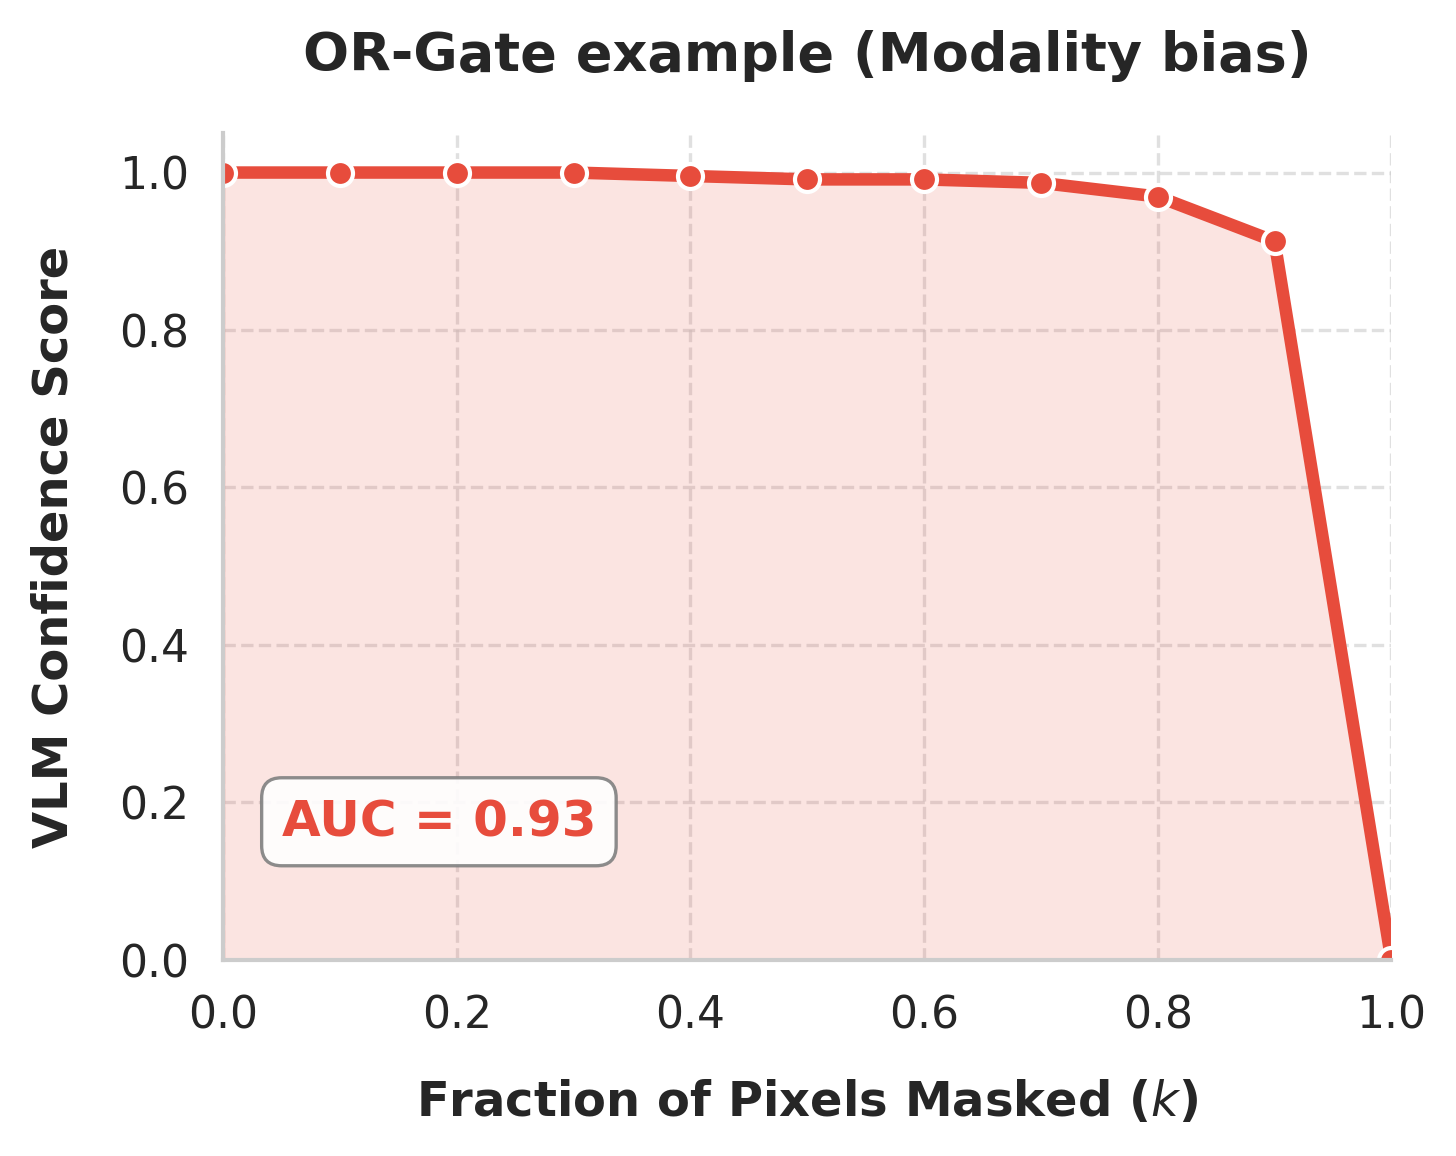

In [116]:
# Mock data for the x-axis (e.g., 10 discrete steps from 0 to 1)
k_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

# Mock OR-Gate (Confidence stays near 1.0)
# sample_idx 57
or_scores = [1.0, 1.0, 1.0, 1.0, 0.9956379532814026, 0.9912759065628052,
             0.9912759065628052, 0.9869138598442078, 0.9694656729698181,
             0.912759006023407, 0.0]
plot_unimodal_deletion_curve(k_steps, or_scores, auc_val=0.934, curve_type='OR-gate',
                             savefig=True, format="pdf")

# # Mock AND-Gate (Confidence crashes immediately)
# and_scores = [1.0, 0.40, 0.10, 0.05, 0.02, 0.01, 0.00, 0.00, 0.00, 0.00, 0.00]
# plot_unimodal_deletion_curve(k_steps, and_scores, auc_val=0.15, curve_type='AND-gate')

[*] Saved figure to ../figs/deletion_curve_and_gate.pdf


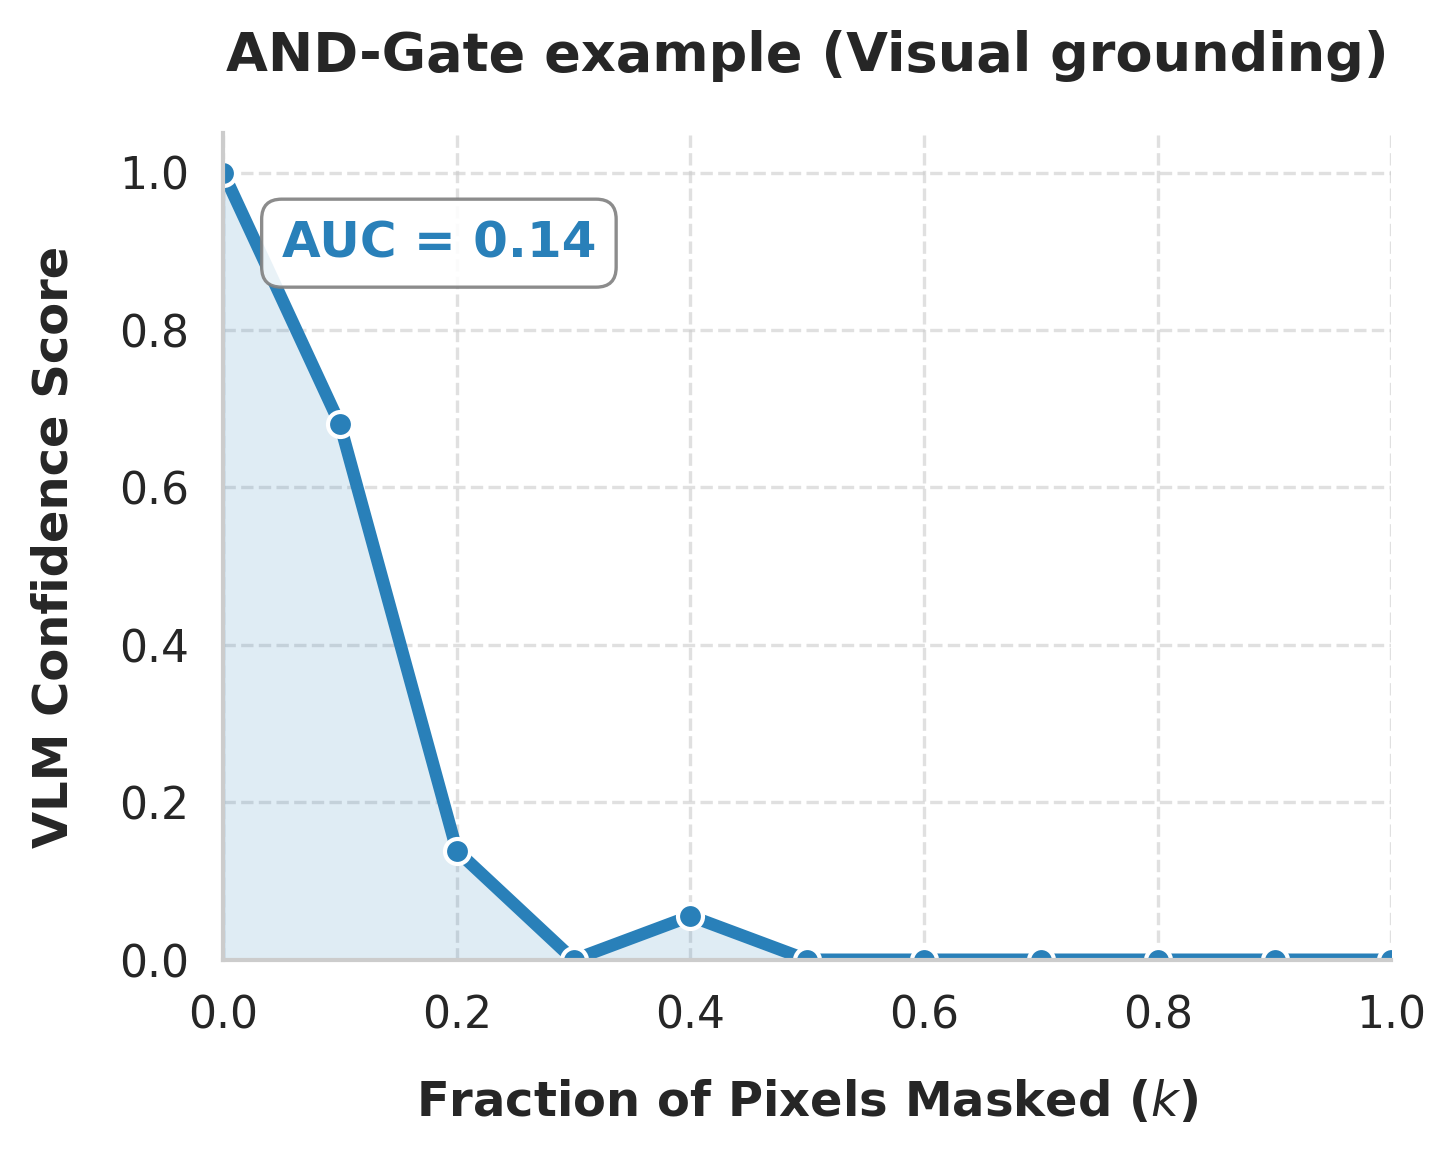

In [117]:
# sample_idx 127
and_scores = [1.0, 0.6800000071525574, 0.13846154510974884, 0.0,
              0.05538461357355118, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
plot_unimodal_deletion_curve(k_steps, and_scores, auc_val=0.14,
                            curve_type='AND-gate', savefig=True, format="pdf")

#### Qualitative plots

In [9]:
salience_traps, \
    contradictions, \
        failures = mine_qualitative_archetypes(df, 
                                            #    f_syn_col="syn_synergy_norm_auc",
                                            #    mui_col="img_srg_norm",
                                            #    mut_col="tok_srg_norm",
                                               )

--- Mining Qualitative Examples for the Appendix ---

[*] Found 20 'Visual Salience Trap' candidates.
Top Candidate:
      sample_idx   Dataset     Model  \
1230         118  cv_bench  internvl   

                                               question  
1230  How many scarfs are in the image? Select from ...  

[*] Found 94 'Unimodal Contradiction' candidates.
Top Candidate:
     sample_idx Dataset     Model  \
111          11  mmstar  internvl   

                                              question  
111  What is the dominant feature in the image?\nOp...  

[*] Found 1612 'Universal Failure' candidates.
Top Candidate:
   sample_idx Dataset     Model  \
2           0  mmstar  internvl   

                                            question  
2  Which option describe the object relationship ...  


In [10]:
salience_traps

,sample_idx,Dataset,Model,question,label,img_srg_norm_AttnLRP,img_srg_norm_GradCAM,img_srg_norm_GradxRollout,img_srg_norm_InputxGradients,img_srg_norm_IntegratedGradients,...,syn_synergy_norm_auc_TAM,tok_srg_norm_AttnLRP,tok_srg_norm_GradCAM,tok_srg_norm_GradxRollout,tok_srg_norm_InputxGradients,tok_srg_norm_IntegratedGradients,tok_srg_norm_LLaVACAM,tok_srg_norm_Random,tok_srg_norm_Rollout,tok_srg_norm_TAM
1230,118,cv_bench,internvl,How many scarfs are in the image? Select from ...,(B),0.260000,0.206667,0.263889,0.480556,0.143333,...,0.089245,0.347134,0.122938,0.204243,0.005382,0.021237,0.000942,-0.010017,0.249571,0.113035
2368,224,mmstar,llava,Which one is the correct caption of this image...,D,0.068308,-0.493910,0.442154,0.047077,-0.023718,...,0.098666,0.265887,-0.175100,0.746273,0.246273,-0.054805,0.041173,-0.262154,0.523135,0.230190
4813,454,repope_all,internvl,Is there a person in the image?,yes,0.067950,-0.634573,0.017684,0.004329,0.075877,...,0.027195,0.374353,0.207727,0.168616,-0.033680,0.205245,0.043108,-0.237732,0.223062,-0.069702
5439,512,mmstar,llava,Hint: Please answer the question and provide t...,D,0.053846,-0.015625,-0.153846,0.184615,0.257812,...,0.066257,0.706417,-0.181184,0.182363,0.172057,0.167772,-0.063350,0.111995,0.460773,0.226766
6172,581,cv_bench,internvl,Considering the relative positions of the buil...,(A),0.384946,0.449462,0.566667,0.216129,0.292473,...,0.096069,0.118710,-0.013767,0.502122,-0.039049,0.189480,-0.139336,0.084020,-0.041536,-0.059874
6329,595,repope_all,internvl,Is there a person in the image?,yes,0.156249,0.175155,0.102772,-0.113171,0.160290,...,0.094143,0.407781,0.088202,0.165307,0.134589,0.280546,0.020118,-0.198838,0.203674,0.007465
6883,647,mmstar,llava,Which solution has a higher concentration of b...,C,-0.129167,-0.462500,-0.635294,-0.058824,-0.306250,...,0.026029,0.790437,-0.125700,0.570843,-0.255602,0.078771,-0.030000,0.012651,0.522831,0.116627
8752,822,mmstar,internvl,Hint: Please answer the question and provide t...,C,-0.034556,0.416026,0.230407,-0.010081,0.011430,...,0.017304,-0.118826,0.000045,0.368123,-0.100354,0.000783,-0.000091,-0.071234,-0.051479,-0.296592
11170,1047,repope_all,internvl,Is there a chair in the image?,yes,0.000870,-0.143028,-0.209346,-0.128389,0.033923,...,0.077144,0.344724,0.164511,0.176787,0.216903,0.284700,0.156984,0.254656,0.205351,0.015182
12414,1164,cv_bench,llava,Considering the relative positions of the benc...,(A),-0.087943,0.266400,0.132800,-0.052000,0.001600,...,0.004170,0.049117,-0.692527,0.303125,-0.295241,-0.051956,-0.726084,-0.555763,0.049858,-0.191470


In [11]:
# contradictions[contradictions["Dataset"] == "repope_all"]
contradictions


,sample_idx,Dataset,Model,question,label,img_srg_norm_AttnLRP,img_srg_norm_GradCAM,img_srg_norm_GradxRollout,img_srg_norm_InputxGradients,img_srg_norm_IntegratedGradients,...,syn_synergy_norm_auc_TAM,tok_srg_norm_AttnLRP,tok_srg_norm_GradCAM,tok_srg_norm_GradxRollout,tok_srg_norm_InputxGradients,tok_srg_norm_IntegratedGradients,tok_srg_norm_LLaVACAM,tok_srg_norm_Random,tok_srg_norm_Rollout,tok_srg_norm_TAM
111,11,mmstar,internvl,What is the dominant feature in the image?\nOp...,D,0.258173,0.099532,0.147716,0.533271,0.067994,...,0.389500,0.492060,0.232559,0.250447,-0.457922,0.168634,0.054817,0.073789,-0.111341,0.179948
121,12,mmstar,internvl,What is the main focus of this image?\nOptions...,A,0.332866,-0.352486,0.082265,0.585822,0.097921,...,0.566306,0.622540,0.122087,0.399072,-0.171546,-0.319034,-0.081159,-0.288736,-0.068084,0.293823
193,19,cv_bench,internvl,How many light switchs are in the image? Selec...,(A),0.468293,0.491463,-0.044737,0.640789,-0.135366,...,0.148067,0.440884,-0.038930,0.345044,-0.198171,0.056437,-0.112950,0.072489,0.280058,0.227214
215,21,mmstar,internvl,What is the overall theme of this image?\nOpti...,B,0.234995,0.073897,0.146554,0.623871,-0.290595,...,0.482210,0.677617,-0.133239,0.160053,-0.312423,-0.123505,0.130816,-0.371025,-0.096160,0.206745
340,33,mmstar,internvl,What kind of environment is depicted in the im...,A,0.703030,-0.576061,0.891781,0.510959,-0.356667,...,0.299767,0.416336,-0.174914,0.590913,-0.315528,0.325486,-0.206827,-0.257919,0.161601,0.393088
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33669,4362,repope_all,internvl,Is there a chair in the image?,no,0.596324,-0.025000,-0.198013,0.507285,0.600000,...,0.000411,-0.573019,0.099660,-0.097372,-0.592385,-0.299230,-0.097949,0.384393,0.100048,0.193550
33784,4385,repope_all,internvl,Is there a chair in the image?,no,0.024390,-0.303659,-0.028788,0.516667,0.064634,...,0.000615,-0.521856,-0.165997,0.097534,-0.501361,-0.200003,-0.113792,0.393348,0.100000,0.295149
33904,4409,repope_all,internvl,Is there a chair in the image?,no,0.129032,-0.158065,0.004878,0.570732,0.103226,...,0.000492,0.262493,-0.386821,-0.096891,-0.492379,-0.319810,-0.483838,0.392832,0.099219,0.204133
34670,4563,repope_all,internvl,Is there a chair in the image?,no,0.500685,0.149315,0.338065,0.562581,0.436301,...,0.002783,0.050433,-0.010984,0.209307,-0.356267,0.354940,-0.002422,-0.306006,0.059237,-0.101119


In [12]:
# failures[failures["Dataset"] == "mmstar"]
failures

,sample_idx,Dataset,Model,question,label,img_srg_norm_AttnLRP,img_srg_norm_GradCAM,img_srg_norm_GradxRollout,img_srg_norm_InputxGradients,img_srg_norm_IntegratedGradients,...,syn_synergy_norm_auc_TAM,tok_srg_norm_AttnLRP,tok_srg_norm_GradCAM,tok_srg_norm_GradxRollout,tok_srg_norm_InputxGradients,tok_srg_norm_IntegratedGradients,tok_srg_norm_LLaVACAM,tok_srg_norm_Random,tok_srg_norm_Rollout,tok_srg_norm_TAM
2,0,mmstar,internvl,Which option describe the object relationship ...,A,-1.121212e-01,-2.727272e-02,0.294737,9.736843e-02,5.454546e-02,...,0.041472,0.597946,0.010538,0.498269,-0.217426,0.091910,-0.132412,-0.106252,-0.250952,0.250644
4,0,mmstar,qwenvl,Which option describe the object relationship ...,A,-1.387779e-17,-1.387779e-17,0.020270,-1.387779e-17,-1.387779e-17,...,0.035374,0.184971,-0.315054,0.519364,0.270089,0.332337,0.163263,-0.057235,-0.082136,-0.011094
22,2,mmstar,llava,What seems to be the theme of the image?\nOpti...,D,2.398205e-02,-8.121816e-01,0.439866,1.640600e-02,1.261267e-01,...,0.003071,0.658016,0.255227,0.469222,-0.080258,0.358094,0.126972,-0.233632,-0.122596,0.056568
42,4,mmstar,llava,What is the center of focus in the image?\nOpt...,A,5.571429e-02,4.310078e-01,-0.050775,-3.643412e-02,-2.519379e-02,...,0.000197,0.470514,-0.087246,0.666929,0.048209,-0.809956,0.010359,-0.100789,0.404180,-0.665331
51,5,mmstar,llava,What is the main subject of the flyer seen in ...,D,4.421052e-02,3.422680e-01,-0.620213,3.361702e-01,-5.051546e-02,...,0.003377,0.358830,-0.390828,0.087004,-0.165843,0.001479,-0.389212,-0.147132,-0.552387,-0.419439
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16007,1496,mmstar,llava,Which label applies to stomach?\nOptions: A: B...,C,1.706897e-01,2.527027e-01,0.089189,1.445946e-01,1.040541e-01,...,0.011518,-0.011325,0.217524,0.135342,-0.024040,0.120216,-0.020279,-0.003701,0.118876,-0.010951
16019,1497,mmstar,qwenvl,Which stage represents the adult alligator?\nO...,C,-1.816902e-02,1.084507e-01,-0.004930,-3.985914e-02,6.154929e-02,...,0.044293,-0.074939,0.186884,0.190533,0.057438,0.257042,0.062667,0.038518,0.249662,-0.018096
16029,1498,mmstar,llava,Think about the magnetic force between the mag...,C,1.562500e-02,9.473682e-02,0.587500,6.875000e-02,-8.421053e-02,...,0.000694,0.491082,0.257915,0.264389,-0.115719,0.115786,0.207842,-0.374504,-0.206689,0.203760
16030,1498,mmstar,qwenvl,Think about the magnetic force between the mag...,C,2.076126e-02,1.287197e-01,-0.013115,1.344262e-02,2.837370e-02,...,0.005521,-0.240652,-0.490162,0.409061,-0.082537,0.084592,-0.621094,-0.435019,-0.195574,0.257691


In [25]:
df.describe()

,sample_idx,syn_synergy_norm_auc,tok_srg_norm,img_srg_norm
count,236133.000000,236133.000000,236133.000000,236133.000000
mean,1815.022983,0.088855,0.076112,0.015273
std,1289.383543,0.119969,0.354140,0.194943
min,0.000000,0.000000,-0.900000,-0.900000
25%,761.000000,0.008655,-0.100572,-0.053731
50%,1515.000000,0.031897,0.095219,0.002239
75%,2609.000000,0.122581,0.298414,0.077443
max,4778.000000,0.794834,0.900000,0.900000


### Synergy metric

#### Correlation computation and speed up

In [7]:
SAVE_DIR = "../figs/"

In [8]:
import json
import glob
import os
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

def load_and_preprocess_data(results_file):
    """Loads JSONL data and computes the necessary AUC columns."""
    data = []
    with open(results_file, 'r') as f:
        for line in f:
            data.append(json.loads(line.strip()))
            
    df = pd.DataFrame(data)

    pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    
    # Compute AUCs if they don't exist
    for col in ['syn_del', 'syn_ins', 'syn_del_norm', 'syn_ins_norm']:
        curve_col = f'{col}_synergy_curve'
        auc_col = f'{col}_auc'
        if auc_col not in df.columns and curve_col in df.columns:
            df[auc_col] = df[curve_col].apply(lambda val: np.trapezoid(val, x=pert_steps))

    # Calculate the unnormalized synergy
    if 'syn_ins_auc' in df.columns and 'syn_del_auc' in df.columns:
        df['synergy_srg_unorm'] = (df["syn_ins_auc"] + df["syn_del_auc"]) / 2.0
        
    return df

def load_all_correlation_data(base_dir="logs/correlation",
                            #dataset_name="repope_all"
                            ):
    """
    Crawls the directory structure to load all JSONL files, 
    automatically extracting the Model and Dataset from folder names.
    """
    all_data = []
    # Adjust this glob pattern based on your actual folder structure!
    # e.g., logs/llava/pope/ig_results.jsonl
    search_pattern = os.path.join(base_dir, "*", "*", "*.jsonl")
    file_list = glob.glob(search_pattern)
    
    print(f"[*] Found {len(file_list)} result files. Aggregating...")
    
    for file_path in file_list:
        # Extract metadata from the path 
        # (e.g., parts[-3] = model, parts[-2] = dataset)
        path_parts = os.path.normpath(file_path).split(os.sep)
        if len(path_parts) >= 3:
            model_name = path_parts[-3]
            dataset_name = path_parts[-2]
        else:
            model_name, dataset_name = "Unknown", "Unknown"
        
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    try:
                        row = json.loads(line)
                        # Ensure we don't overwrite if the JSON already has it
                        row['Model'] = row.get('model', model_name)
                        row['Dataset'] = row.get('dataset', dataset_name)
                        # Ensure explainer name is clean
                        row['Explainer'] = row.get('explainer', os.path.basename(file_path).replace('.jsonl', '').split('_')[3])
                        all_data.append(row)
                    except json.JSONDecodeError:
                        continue
                    
    df = pd.DataFrame(all_data)
    df['Explainer'] = df["Explainer"].replace('Lxt', 'AttnLRP')
    #pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    pert_steps = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

    cols_to_drop = ['final_alignment', 'final_true_syn', 'synergy_refined_srg', 
       'final_redundancy', 'standard_srg']
    df = df.drop(cols_to_drop, axis=1)
    
    # Compute AUCs if they don't exist
    for col in ['syn_del', 'syn_ins', 'syn_del_norm', 'syn_ins_norm']:
        curve_col = f'{col}_synergy_curve'
        auc_col = f'{col}_auc'
        if auc_col not in df.columns and curve_col in df.columns:
            df[auc_col] = df[curve_col].apply(lambda val: np.trapezoid(val, x=pert_steps))

    # Calculate the unnormalized synergy
    if 'syn_ins_auc' in df.columns and 'syn_del_auc' in df.columns:
        df['synergy_srg_unorm'] = (df["syn_ins_auc"] + df["syn_del_auc"]) / 2.0

    if 'syn_ins_norm_auc' in df.columns and 'syn_del_norm_auc' in df.columns:
            df['synergy_srg_norm'] = (df["syn_ins_norm_auc"] + df["syn_del_norm_auc"]) / 2.0

    
    # Optional: Calculate combined AUPC metrics if you saved curves instead of raw AUCs
    # ... (Insert your trapezoid np.trapezoid code here if needed) ...
    
    return df

def analyze_and_plot_correlation(df, x_col, y_col, x_label=None, y_label=None, title=None, save_path=None):
    """
    Cleans data, computes correlation statistics, prints a report, and generates a paper-ready plot.
    """
    # 1. Clean Data: Drop rows where either metric is NaN
    clean_df = df.dropna(subset=[x_col, y_col]).copy()
    
    if len(clean_df) == 0:
        print(f"[!] Cannot analyze {x_col} vs {y_col}: No valid overlapping data points.")
        return

    # 2. Compute Correlations
    pearson_r, p_val_p = stats.pearsonr(clean_df[x_col], clean_df[y_col])
    spearman_rho, p_val_s = stats.spearmanr(clean_df[x_col], clean_df[y_col])

    # 3. Print Report
    print("\n" + "="*50)
    print(f"      XAI METRIC VALIDATION: {x_col} vs {y_col}")
    print("="*50)
    print(f"Total Samples Analyzed : {len(clean_df)}")
    print(f"Metric X ({x_col}) Mean : {clean_df[x_col].mean():.4f} ± {clean_df[x_col].std():.4f}")
    print(f"Metric Y ({y_col}) Mean : {clean_df[y_col].mean():.4f} ± {clean_df[y_col].std():.4f}")
    print("\n--- Correlation ---")
    print(f"Pearson r      : {pearson_r:.4f}  (p-value: {p_val_p:.2e})")
    print(f"Spearman rho   : {spearman_rho:.4f}  (p-value: {p_val_s:.2e})")
    print("="*50)

    # 4. Generate Publication-Ready Plot
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.figure(figsize=(8, 6))
    
    ax = sns.regplot(
        x=x_col, y=y_col, data=clean_df, 
        scatter_kws={'alpha': 0.6, 'color': '#2C3E50'}, 
        line_kws={'color': '#E74C3C', 'linewidth': 2}
    )
    
    # Use provided labels or default to column names
    plt.title(title or f'Validation: {x_col} vs {y_col}', fontsize=14, weight='bold')
    plt.xlabel(x_label or x_col, fontsize=12)
    plt.ylabel(y_label or y_col, fontsize=12)

    # Add Stats Box
    textstr = f"Spearman $\\rho$ = {spearman_rho:.3f}\nPearson $r$ = {pearson_r:.3f}"
    props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12,
            verticalalignment='top', bbox=props)

    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"[*] Plot saved to {save_path}")
    
    plt.show() # Display the plot
    plt.close()


In [9]:
df = load_all_correlation_data(base_dir="../logs/correlation_full_sii")

[*] Found 4 result files. Aggregating...


In [10]:
df.columns

Index(['sample_idx', 'image_id', 'question', 'label', 'prediction', 'time_sii',
       'sii_auc', 'sii_curve', 'time_syn', 'syn_del_synergy_curve',
       'syn_ins_synergy_curve', 'syn_ins_norm_synergy_curve',
       'syn_del_norm_synergy_curve', 'synergy_srg', 'Model', 'Dataset',
       'Explainer', 'syn_del_auc', 'syn_ins_auc', 'syn_del_norm_auc',
       'syn_ins_norm_auc', 'synergy_srg_unorm', 'synergy_srg_norm'],
      dtype='object')

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import numpy as np
import matplotlib.patches as mpatches


def plot_correlation_scatter(df, x_col='sii_auc', y_col='synergy_srg',
                            savefig=False, format='pdf',
                            save_path="correlation_scatter",
                            SAVE_DIR="."):

    print(f"--- Generating 2x2 Correlation Subplots (Hued by Model) ---")
    
    # 1. Drop NaNs and extract necessary columns
    plot_df = df[[x_col, y_col, 'Explainer', 'Model']].dropna()
    
    # Specify the 4 explainers you want to plot
    target_explainers = ['Random', 'InputxGradients', 'Rollout', 'TAM']
    plot_df = plot_df[plot_df['Explainer'].isin(target_explainers)]

    # Calculate Global Correlation and p-values
    global_spearman, global_spearman_p = stats.spearmanr(plot_df[x_col], plot_df[y_col])
    global_pearson, global_pearson_p = stats.pearsonr(plot_df[x_col], plot_df[y_col])
    
    # 2. Setup a 2x2 grid sharing both axes
    fig, axes = plt.subplots(2, 2, figsize=(8, 8), dpi=300, sharex=True, sharey=True)
    
    # Define a clean color palette for the models
    model_palette = sns.color_palette('Set1', n_colors=plot_df['Model'].nunique())
    
    # List to store detailed stats for printing at the end
    print_results = []

    for ax, explainer in zip(axes.flat, target_explainers):
        sub_df = plot_df[plot_df['Explainer'] == explainer]
        
        # 3. Scatter Plot with HUE per Model
        sns.scatterplot(
            data=sub_df,
            x=x_col,
            y=y_col,
            hue='Model',
            palette=model_palette,
            alpha=0.8,
            edgecolor='black',
            linewidth=0.5,
            s=20,
            ax=ax,
            legend=False 
        )
        
        # 4. Global Line of Best Fit for this explainer
        if len(sub_df) > 1:
            m, b = np.polyfit(sub_df[x_col], sub_df[y_col], 1)
            x_range = np.linspace(sub_df[x_col].min(), sub_df[x_col].max(), 100)
            ax.plot(x_range, m*x_range + b, color='black', linestyle='--', linewidth=2, alpha=0.7)
            
            # Calculate Correlations and p-values
            spearman_rho, s_p = stats.spearmanr(sub_df[x_col], sub_df[y_col])
            pearson_r, p_p = stats.pearsonr(sub_df[x_col], sub_df[y_col])
            
            # Store results for the console printout
            print_results.append({
                'Explainer': explainer,
                'Spearman': (spearman_rho, s_p),
                'Pearson': (pearson_r, p_p)
            })
            
            # Add the text box inside the subplot (Excluding p-values)
            stats_text = f"$\\rho$ = {spearman_rho:.2f}\n$r$ = {pearson_r:.2f}"
            
            props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')
            ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=11,
                    verticalalignment='top', bbox=props, fontweight='bold')
        
        # 5. Subplot Formatting
        ax.set_title(f"Explainer: {explainer}", fontsize=12, fontweight='bold')
        ax.set_xlabel("") 
        ax.set_ylabel("")
        ax.grid(True, linestyle=':', alpha=0.6)
        
    # 6. Global Labels and Legend
    fig.supxlabel('Exact Shapley Interaction Index (SII)', fontsize=14, fontweight='bold')
    fig.supylabel(r'Proposed Synergistic Faithfulness ($\mathcal{F}_{syn}$)', fontsize=14, fontweight='bold')

    # Global Title (Excluding p-values)
    global_title = f"Global Correlation with Exact Shapley ($\\rho$ = {global_spearman:.2f}; $r$ = {global_pearson:.2f})"
    fig.suptitle(global_title, fontsize=14, fontweight='bold', y=1.06)
    
    # Extract legend handles to create a single global legend
    legend_elements = [mpatches.Patch(color=color, label=model) 
                       for color, model in zip(model_palette, plot_df['Model'].unique())]
    
    fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.01), 
               ncol=plot_df['Model'].nunique(), title="VLM", 
               title_fontsize='12', fontsize='11', frameon=False)
    
    plt.tight_layout()
    # Adjust layout so the titles and labels don't overlap
    fig.subplots_adjust(bottom=0.08, left=0.08, top=0.90) 

    if savefig:
        save_path_full = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(save_path_full, format=format, bbox_inches='tight')
        print(f"Saved figure to: {save_path_full}")
        
    plt.show()

    # --- NEW: Print all detailed statistics to the console ---
    print("\n=== Detailed Correlation Statistics (Including p-values) ===")
    for res in print_results:
        print(f"Explainer: {res['Explainer']}")
        # Using scientific notation for p-values in case they are very small
        print(f"  Spearman rho: {res['Spearman'][0]:.3f} (p = {res['Spearman'][1]:.3e})")
        print(f"  Pearson r:    {res['Pearson'][0]:.3f} (p = {res['Pearson'][1]:.3e})")
        
    print(f"\nGLOBAL (Across all target explainers):")
    print(f"  Spearman rho: {global_spearman:.3f} (p = {global_spearman_p:.3e})")
    print(f"  Pearson r:    {global_pearson:.3f} (p = {global_pearson_p:.3e})")
    print("==========================================================")
# Run the plotting function!
# plot_correlation_scatter(df, x_col='sii_auc', y_col='synergy_srg')

--- Generating 2x2 Correlation Subplots (Hued by Model) ---


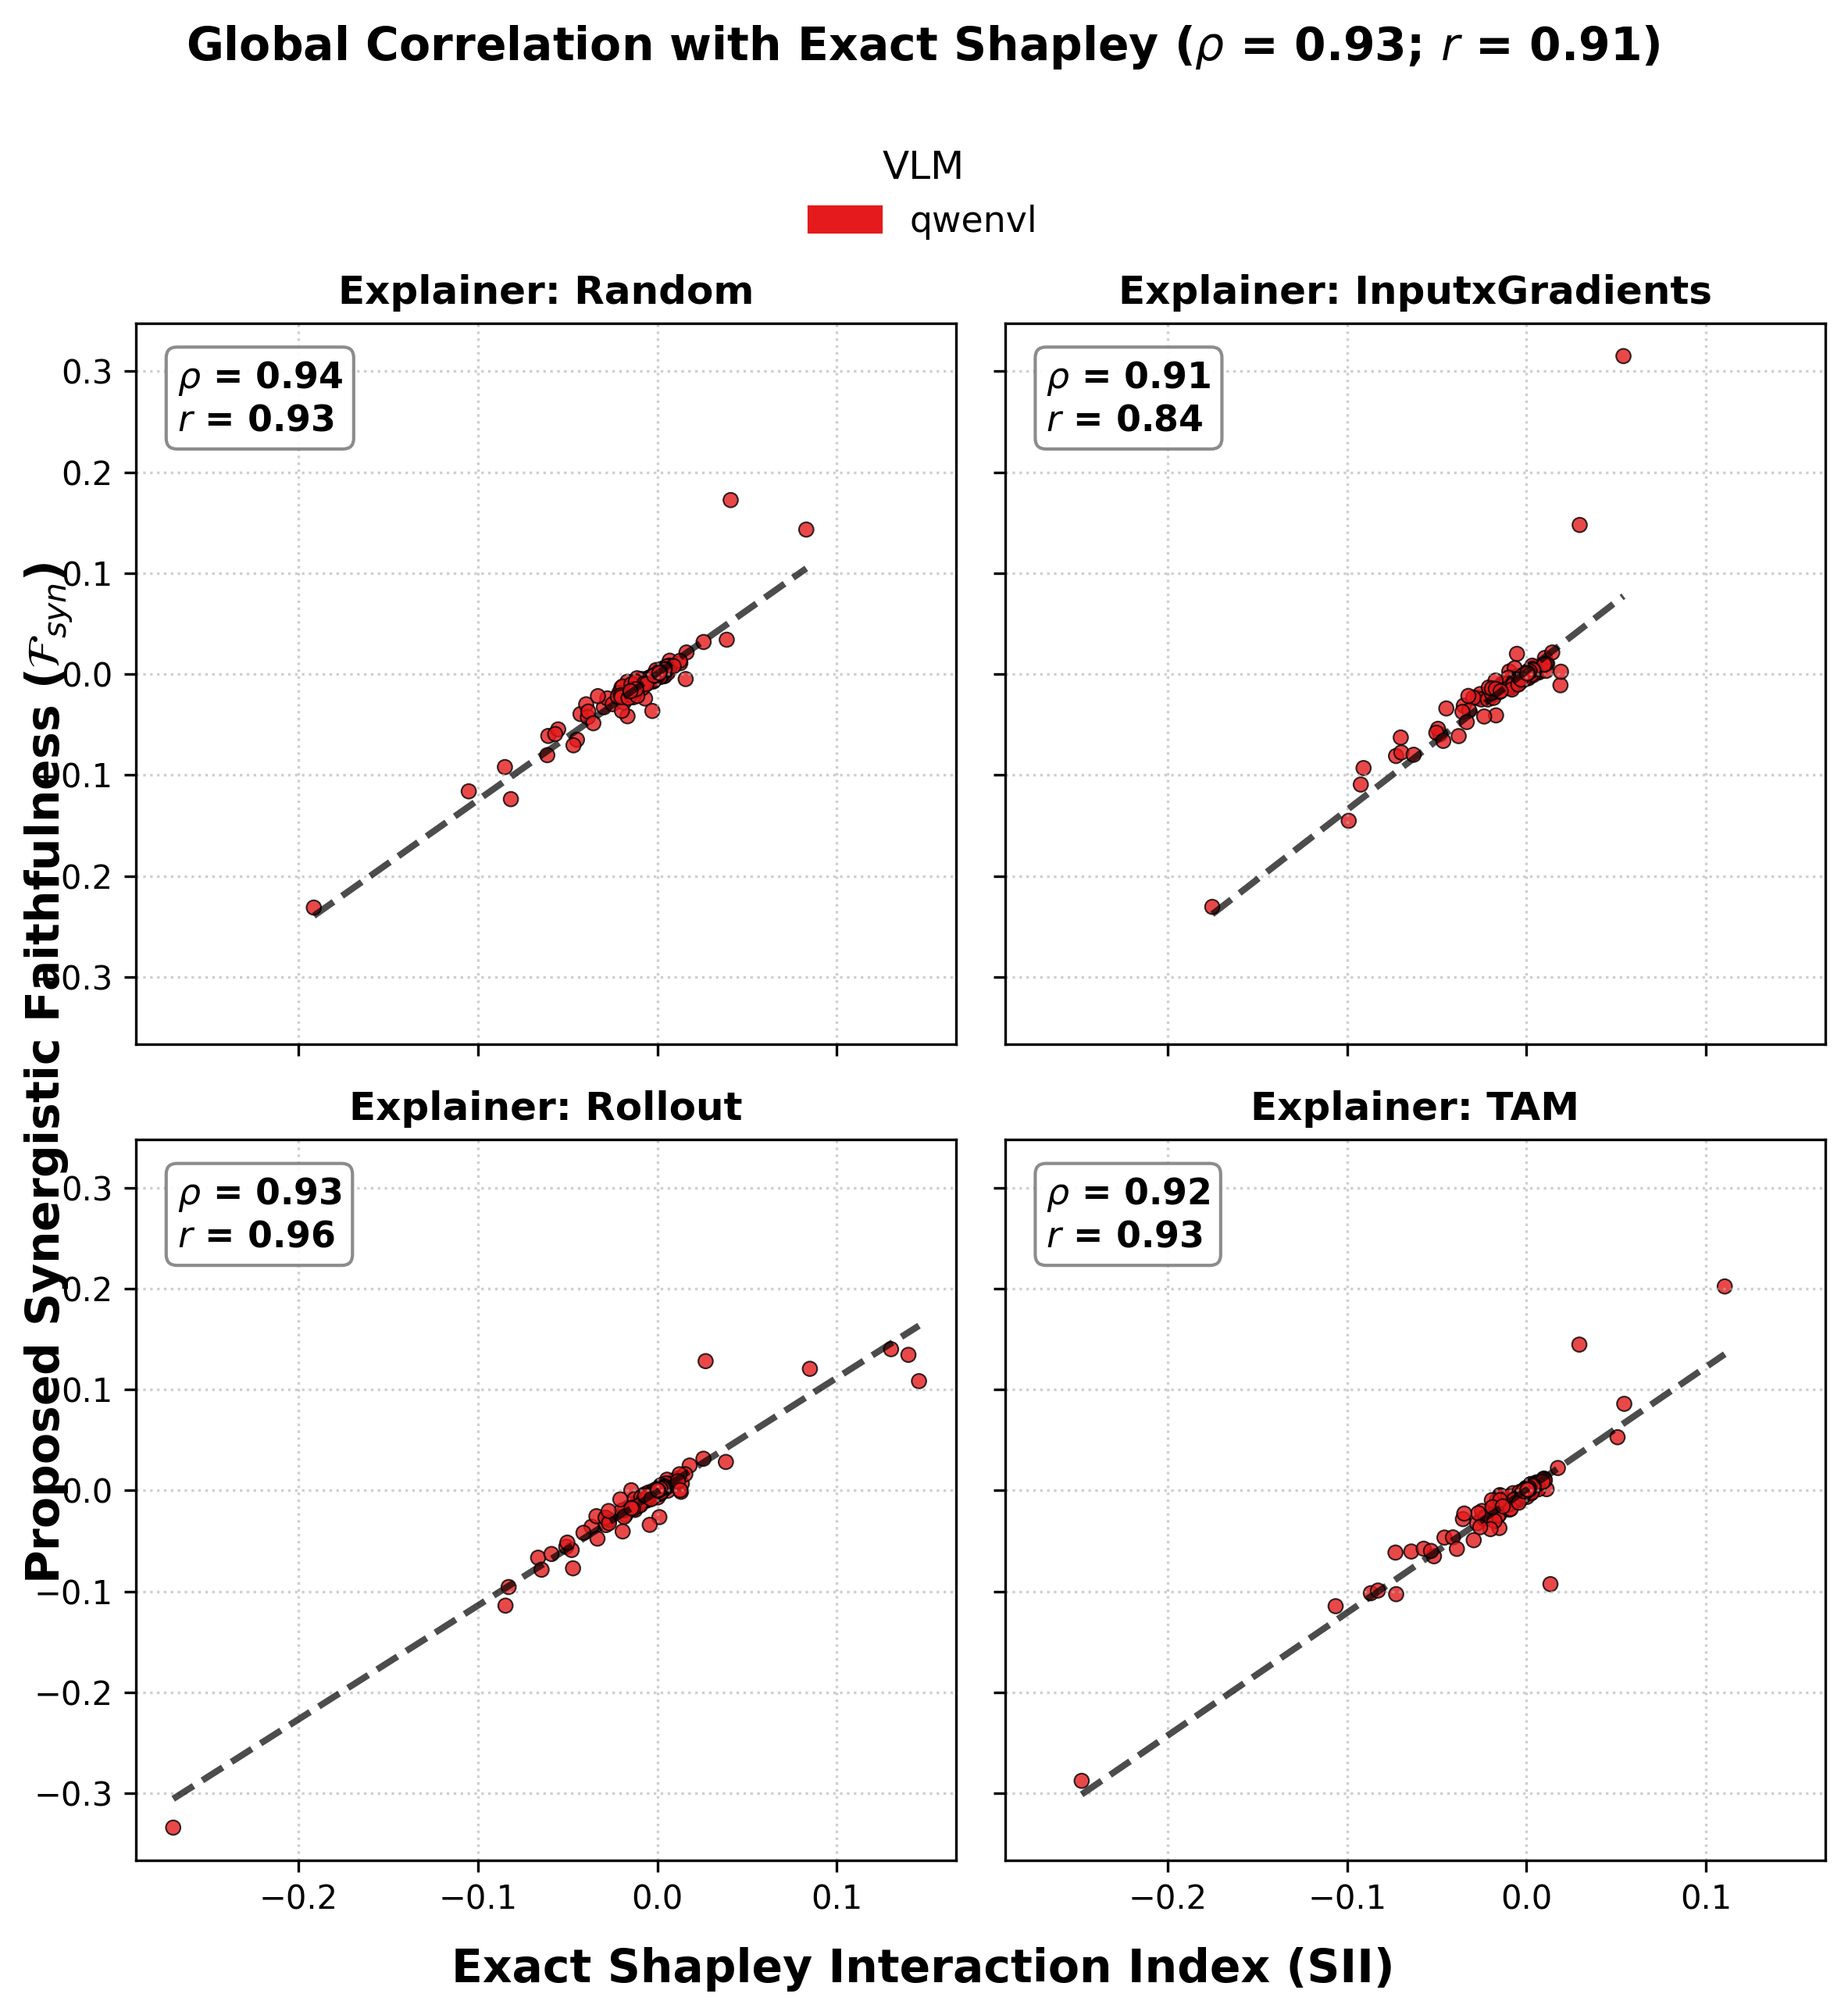


=== Detailed Correlation Statistics (Including p-values) ===
Explainer: Random
  Spearman rho: 0.939 (p = 1.123e-93)
  Pearson r:    0.934 (p = 1.172e-90)
Explainer: InputxGradients
  Spearman rho: 0.909 (p = 2.568e-77)
  Pearson r:    0.838 (p = 5.136e-54)
Explainer: Rollout
  Spearman rho: 0.934 (p = 3.001e-90)
  Pearson r:    0.961 (p = 1.756e-112)
Explainer: TAM
  Spearman rho: 0.923 (p = 3.962e-84)
  Pearson r:    0.927 (p = 2.139e-86)

GLOBAL (Across all target explainers):
  Spearman rho: 0.926 (p = 0.000e+00)
  Pearson r:    0.912 (p = 2.906e-310)


In [12]:
plot_correlation_scatter(df, x_col='sii_auc', y_col='synergy_srg_norm',
                         save_path="full_sii_correlation_scatter",
                         SAVE_DIR=SAVE_DIR,
                         savefig=False, format="pdf")

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_runtime_complexity(df, time_col='time_syn',
                            savefig=False, format='png',
                            save_path="runtime_complexity"):
    print("--- Generating 1x2 Runtime Complexity Figure ---")
    
    # Setup a 1x2 grid
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=300)
    
    # ==========================================
    # LEFT PANEL: Theoretical Forward Passes
    # ==========================================
    ax1 = axes[0]
    
    # Generate theoretical data (Sequence length vs Passes)
    # We stop at N=25 because 2^25 is already 33 million passes!
    tokens = np.arange(2, 25) 
    exact_sii_passes = 2**tokens
    
    # Your metric: 6K + 2. Assuming K=10, that's 62 passes.
    K = 10
    fsyn_passes = np.full_like(tokens, 6 * K + 2)
    
    ax1.plot(tokens, exact_sii_passes, color='#e74c3c', linewidth=2.5, label=r'Exact SII $\mathcal{O}(2^{N})$')
    ax1.plot(tokens, fsyn_passes, color='#2ecc71', linewidth=2.5, label=r'Proposed $\mathcal{F}_{{syn}}$ ($K={K}$)')
    
    # Use a Log Scale for the Y-axis because Exact SII explodes instantly
    ax1.set_yscale('log')
    ax1.set_xlabel('Total Sequence Length ($m + n$ tokens)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Number of Forward Passes (Log Scale)', fontsize=11, fontweight='bold')
    ax1.set_title('A. Theoretical Complexity', fontsize=12, fontweight='bold')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper left')

    # ==========================================
    # RIGHT PANEL: Empirical Wall-Clock Time
    # ==========================================
    ax2 = axes[1]
    
    # Sort explainers by mean time so the bar chart looks clean
    mean_times = df.groupby('Explainer')[time_col].mean().sort_values()
    order = mean_times.index.tolist()
    
    # Create the barplot. Seaborn automatically calculates the 95% CI or std for error bars!
    sns.barplot(
        data=df, 
        x='Explainer', 
        y=time_col, 
        order=order,
        color='#3498db',
        edgecolor='black',
        err_kws={'linewidth': 1.5, 'color': 'black'},
        capsize=0.1,
        ax=ax2
    )
    
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right')
    ax2.set_xlabel('Explainer Method', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Average Evaluation Time (seconds)', fontsize=11, fontweight='bold')
    ax2.set_title('B. Empirical Wall-Clock Time per Instance', fontsize=12, fontweight='bold')
    ax2.grid(axis='y', linestyle=':', alpha=0.6)

    # Clean up spines
    for ax in axes:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    plt.tight_layout()
    if savefig:
        save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(save_path, format=format, bbox_inches='tight')
        print(f"Saved figure to: {save_path}")
    plt.show()


def plot_time_comparison(df, sii_col='time_sii', syn_col='time_syn',
                        savefig=False, format='png',
                        save_path="runtime_comparison_bars"):
    print("--- Generating Empirical Runtime Comparison Bar Plot ---")
    
    # 1. Filter the dataset
    # We only want to plot the rows where Exact SII was actually computed (the N=200 subset)
    plot_df = df.dropna(subset=[sii_col, syn_col]).copy()
    
    # Optional: If you only evaluated certain explainers for the exact SII, 
    # we can sort them so the chart looks organized.
    target_explainers = ['Random', 'InputxGradients', 'Rollout', 'TAM']
    plot_df = plot_df[plot_df['Explainer'].isin(target_explainers)]
    
    # 2. Reshape the DataFrame using melt()
    # This turns our two time columns into rows so Seaborn can plot them side-by-side
    melted_df = plot_df.melt(
        id_vars=['Explainer'],
        value_vars=[sii_col, syn_col],
        var_name='Method',
        value_name='Time_Seconds'
    )
    
    # Rename the variables so they look beautiful in the legend
    melted_df['Method'] = melted_df['Method'].replace({
        sii_col: 'Exact SII (Downsampled)',
        syn_col: r'$\mathcal{F}_{syn}$'
    })
    print(melted_df)
    
    # 3. Setup the plot
    fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
    
    # Plot side-by-side bars with standard deviation error bars
    sns.barplot(
        data=melted_df,
        x='Explainer',
        y='Time_Seconds',
        hue='Method',
        palette=['#e74c3c', '#2ecc71'], # Red for Exact (bad/slow), Green for Proposed (good/fast)
        edgecolor='black',
        err_kws={'linewidth': 1.5, 'color': 'black'},
        capsize=0.1,
        ax=ax
    )
    
    # 4. Critical Formatting: Logarithmic Scale
    ax.set_yscale('log')
    
    # 5. Labels and Clean up
    ax.set_xlabel('Explainer method', fontsize=10, fontweight='bold')
    ax.set_ylabel('Execution time per instance (seconds) [Log Scale]', fontsize=10, fontweight='bold')
    ax.set_title(r'Empirical time: Exact SII vs. $\mathcal{F}_{syn}$', fontsize=12, fontweight='bold', pad=15)
    
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Move the legend outside or to a clean spot so it doesn't cover the bars
    ax.legend(title='Evaluation Method', title_fontsize='11', fontsize='10', loc='best')
    
    plt.tight_layout()

    if savefig:
        save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(save_path, format=format, bbox_inches='tight')
        print(f"Saved figure to: {save_path}")
    plt.show()

# Run the function!
# plot_time_comparison(df, sii_col='time_sii', syn_col='time_syn')

--- Generating 1x2 Runtime Complexity Figure ---
Explainer
InputxGradients    521.898952
TAM                548.565713
Random             549.231387
Rollout            974.821328
Name: time_sii, dtype: float64


/tmp/ipykernel_59159/3264839172.py:62: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right')


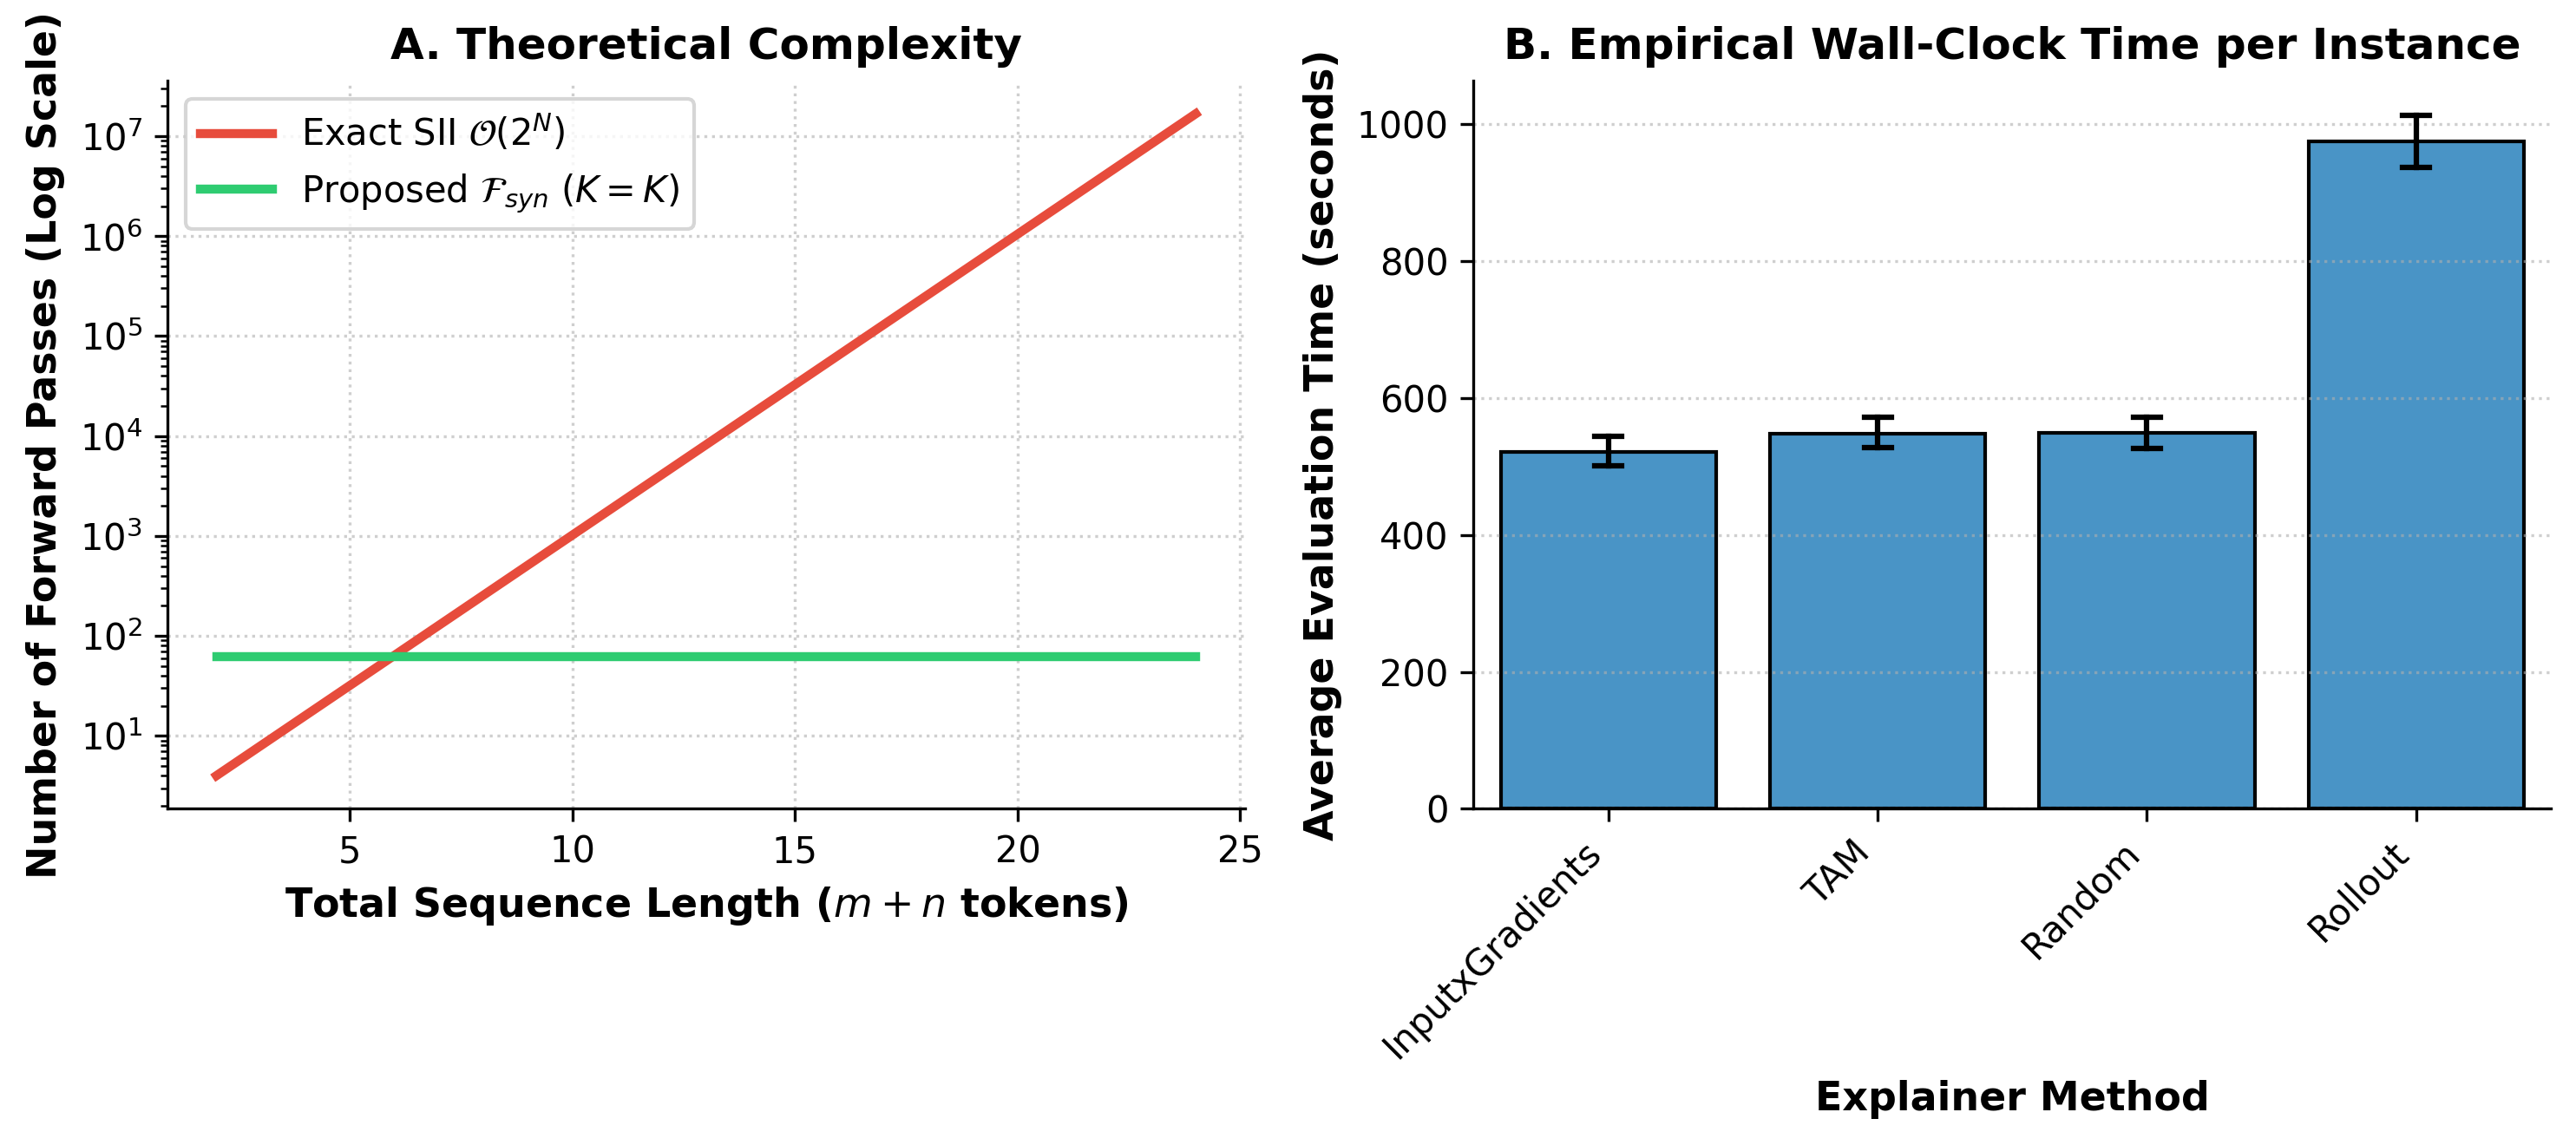

In [17]:
# Run it! (Replace 'time_syn' with your actual execution time column)
plot_runtime_complexity(df, time_col='time_sii', savefig=False)

--- Generating Empirical Runtime Comparison Bar Plot ---
     Explainer                   Method  Time_Seconds
0       Random  Exact SII (Downsampled)    934.616574
1       Random  Exact SII (Downsampled)    850.116005
2       Random  Exact SII (Downsampled)    484.640502
3       Random  Exact SII (Downsampled)    489.767650
4       Random  Exact SII (Downsampled)    837.918738
...        ...                      ...           ...
1595   Rollout      $\mathcal{F}_{syn}$      7.553516
1596   Rollout      $\mathcal{F}_{syn}$      7.650744
1597   Rollout      $\mathcal{F}_{syn}$      7.580163
1598   Rollout      $\mathcal{F}_{syn}$      7.364491
1599   Rollout      $\mathcal{F}_{syn}$      7.587844

[1600 rows x 3 columns]


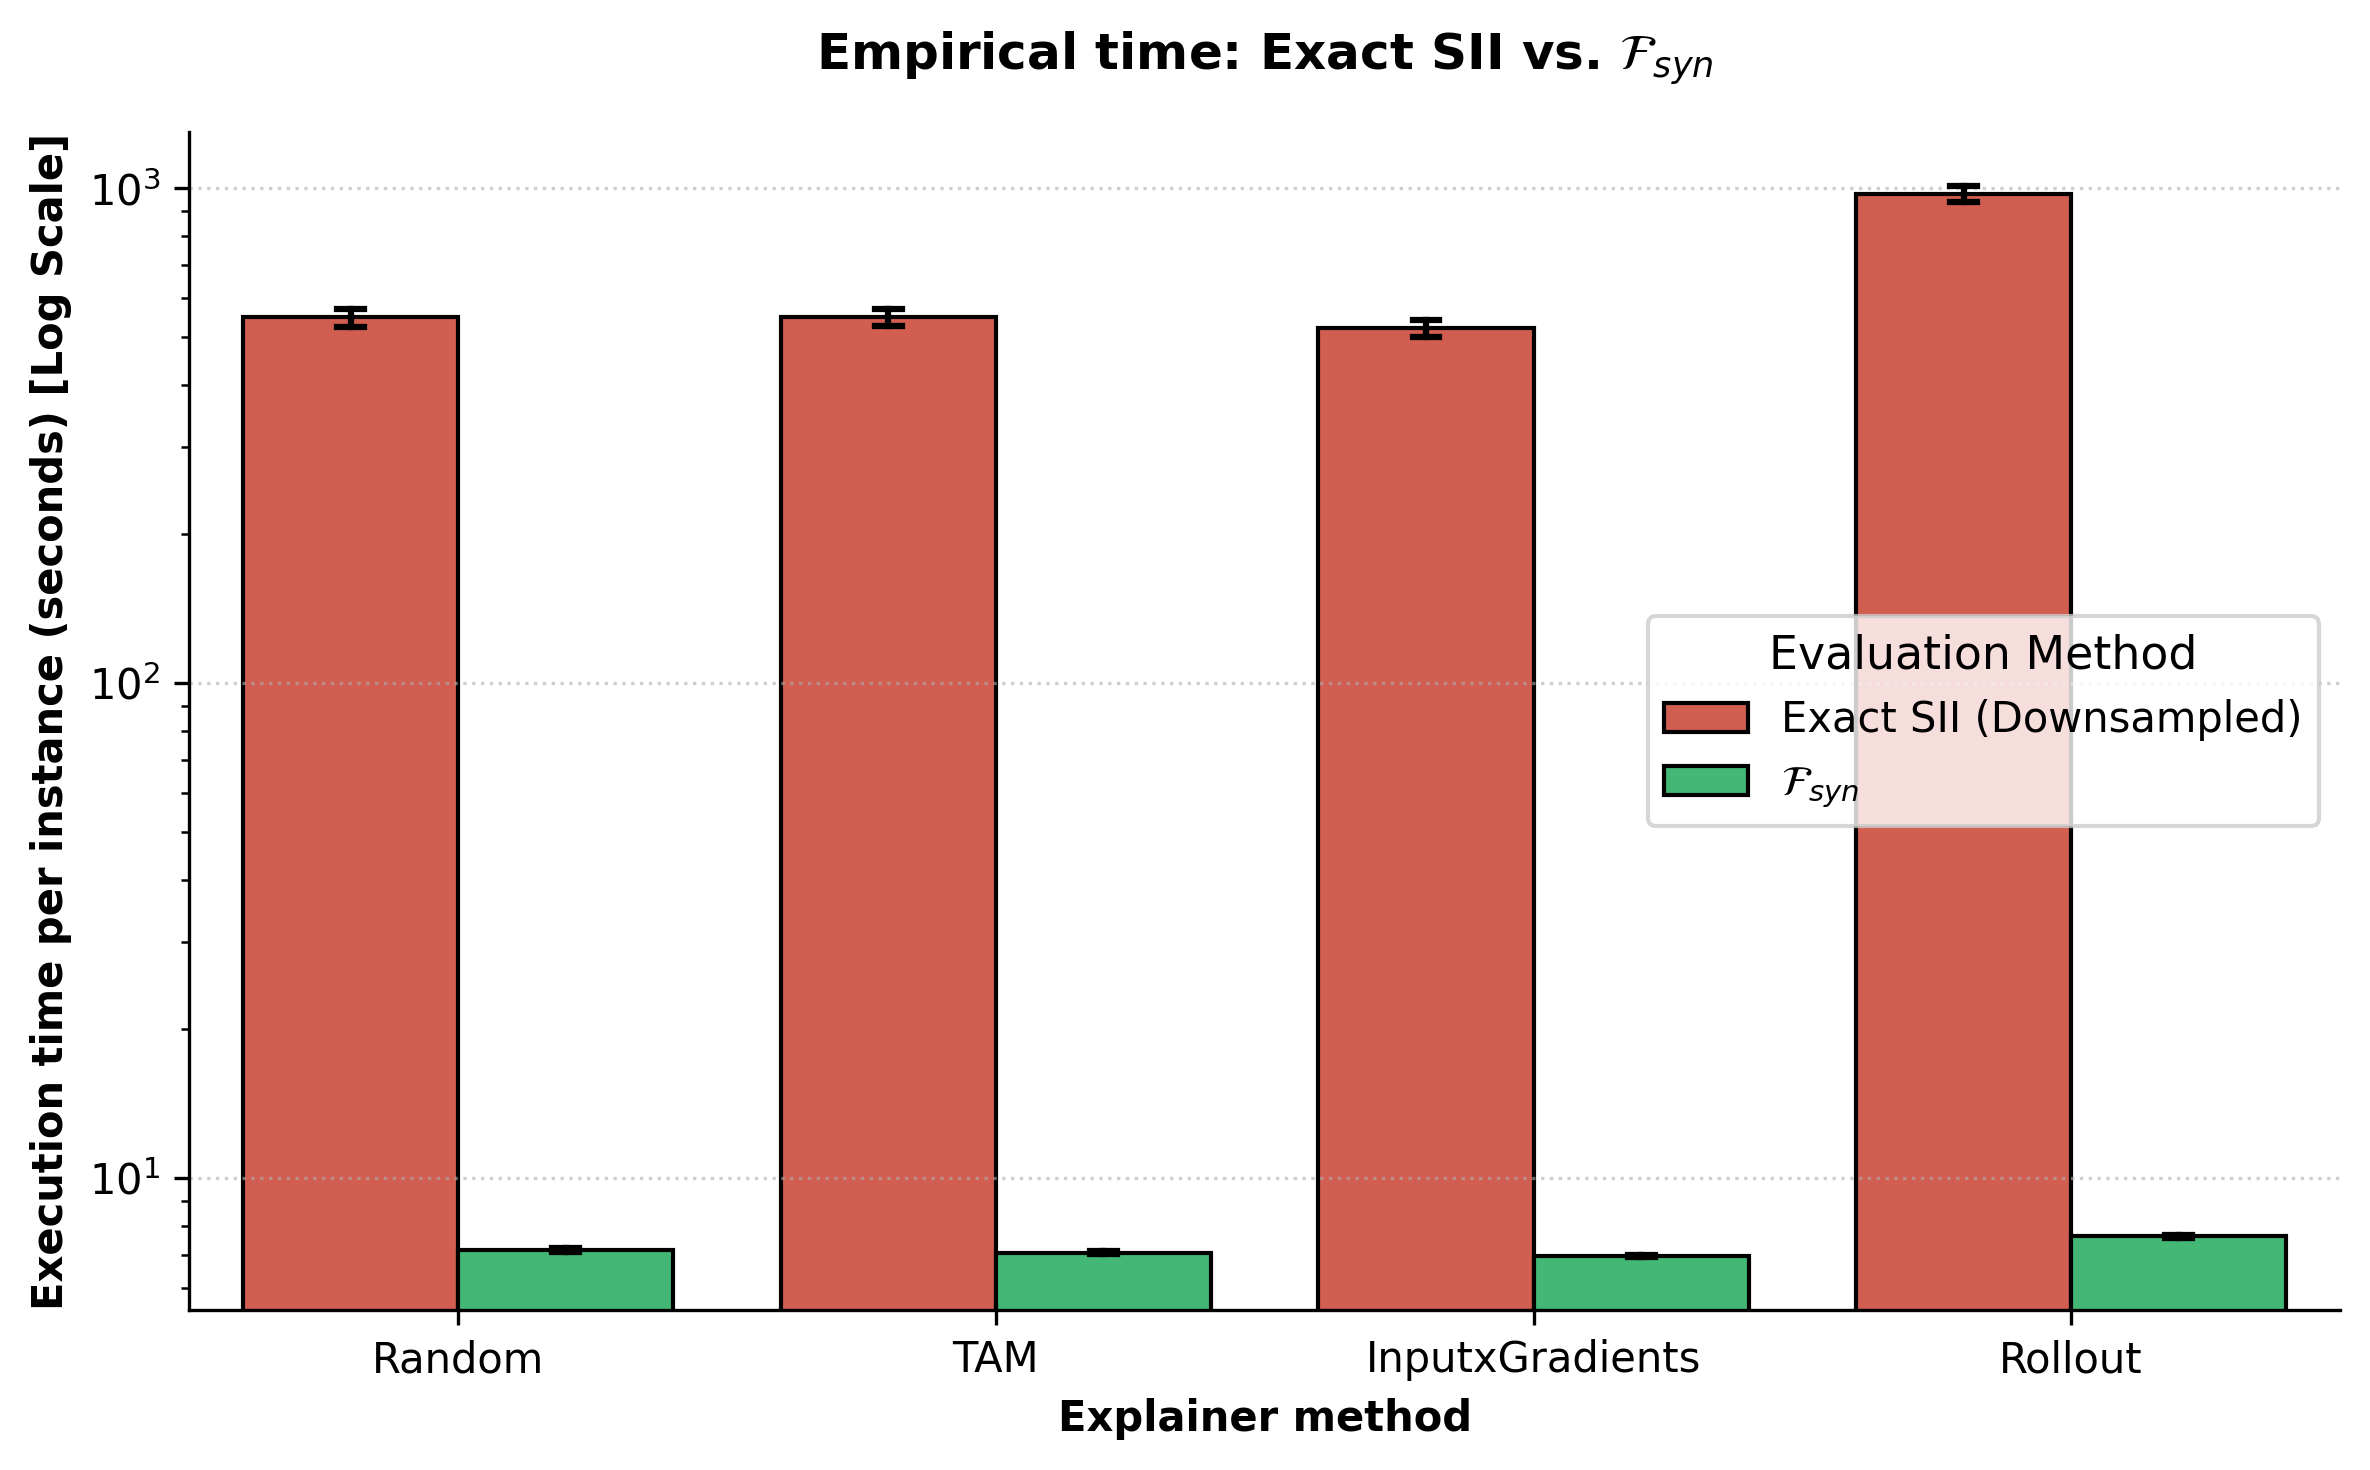

In [19]:
plot_time_comparison(df, sii_col='time_sii', syn_col='time_syn',
                     save_path="full_sii_runtime_comparison_bars",
                    savefig=False, format="pdf")

In [69]:
df.columns

Index(['sample_idx', 'image_id', 'question', 'label', 'prediction', 'time_sii',
       'sii_auc', 'sii_curve', 'time_syn', 'syn_del_synergy_curve',
       'syn_ins_synergy_curve', 'syn_ins_norm_synergy_curve',
       'syn_del_norm_synergy_curve', 'synergy_srg', 'Model', 'Dataset',
       'Explainer', 'syn_del_auc', 'syn_ins_auc', 'syn_del_norm_auc',
       'syn_ins_norm_auc', 'synergy_srg_unorm'],
      dtype='object')

In [32]:
df = load_all_correlation_data(base_dir="../logs/correlation_C_10")

# 2. Print speedup info (Calculated once globally)
if 'time_sii' in df.columns and 'time_syn' in df.columns:
    avg_sii_time = df['time_sii'].mean()
    avg_srg_time = df['time_syn'].mean()
    speedup_factor = avg_sii_time / avg_srg_time if avg_srg_time > 0 else 0
    print("\n--- Computational Efficiency ---")
    print(f"Avg Time per Image (Exact SII) : {avg_sii_time:.2f} seconds")
    print(f"Avg Time per Image (Fast SRG)  : {avg_srg_time:.2f} seconds")
    print(f"Speedup Factor SRG             : {speedup_factor:.1f}x Faster")
    print("==================================================\n")


[*] Found 3 result files. Aggregating...

--- Computational Efficiency ---
Avg Time per Image (Exact SII) : 565.93 seconds
Avg Time per Image (Fast SRG)  : 6.34 seconds
Speedup Factor SRG             : 89.3x Faster



#### Further analysis

In [6]:
import json
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# results_file="../repope_eval_res_baseline.json"
#results_file="../logs/repope_eval_res_baseline.json"


print(f"Loading curve data from {results_file}...")

# 1. Define your exact perturbation steps for the X-axis
pert_steps = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
num_steps = len(pert_steps)

sii_curves = []
del_curves = []
ins_curves = []
sum_curves = []
dif_curves = []

# 2. Extract Data
with open(results_file, 'r') as f:
    for line in f:
        data = json.loads(line.strip())
        
        # Make sure the sample has the curves (skip if failed/missing)
        if "sii_curve" in data and "syn_del_synergy_curve" in data:
            sii_curves.append(data["sii_curve"])
            del_curves.append(data["syn_del_synergy_curve"])
            ins_curves.append(data["syn_ins_synergy_curve"])


# Convert to 2D NumPy arrays: Shape (N_images, N_steps)
sii_mat = np.array(sii_curves)
del_mat = np.array(del_curves)
ins_mat = np.array(ins_curves)
sum_mat = (ins_mat + del_mat) / 2
dif_mat = ins_mat - del_mat

N = sii_mat.shape[0]
print(f"Successfully loaded {N} images with full step-wise curves.\n")

Loading curve data from ../logs/correlation/internvl/eval_repope_oracle_tam_results.jsonl...
Successfully loaded 200 images with full step-wise curves.



Saved Analysis A -> 'analysis_A_trajectory.png'


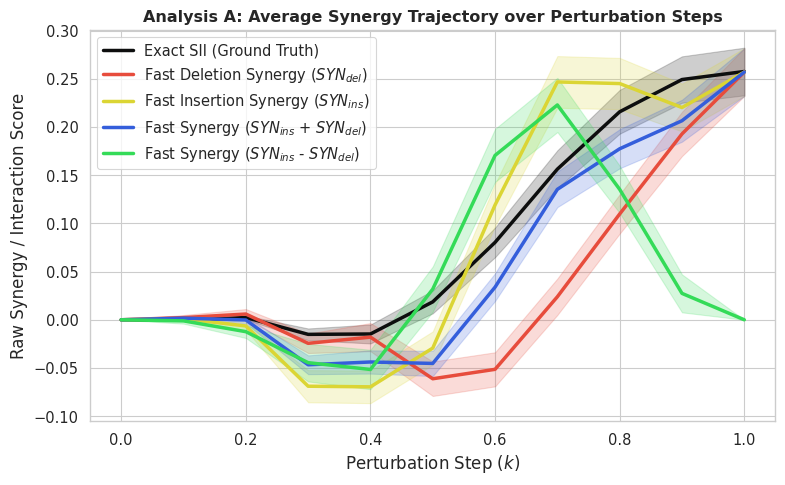

In [14]:
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# =========================================================
# ANALYSIS A: Mean Trajectory Plot (The "Shape" of Synergy)
# =========================================================
plt.figure(figsize=(8, 5))

def plot_mean_with_std(matrix, color, label):
    mean_curve = np.mean(matrix, axis=0)
    # Using Standard Error of the Mean (SEM) for cleaner shaded regions
    sem_curve = np.std(matrix, axis=0) / np.sqrt(N) 
    plt.plot(pert_steps, mean_curve, color=color, label=label, linewidth=2.5)
    plt.fill_between(pert_steps, mean_curve - sem_curve, mean_curve + sem_curve, color=color, alpha=0.2)

plot_mean_with_std(sii_mat, "#0D0E0E", 'Exact SII (Ground Truth)')
plot_mean_with_std(del_mat, '#E74C3C', 'Fast Deletion Synergy ($SYN_{del}$)')
plot_mean_with_std(ins_mat, "#DBD534", 'Fast Insertion Synergy ($SYN_{ins}$)')
plot_mean_with_std(sum_mat, "#345EDB", 'Fast Synergy ($SYN_{ins}$ + $SYN_{del}$)')
plot_mean_with_std(dif_mat, "#34DB58", 'Fast Synergy ($SYN_{ins}$ - $SYN_{del}$)')

plt.title('Analysis A: Average Synergy Trajectory over Perturbation Steps', weight='bold')
plt.xlabel('Perturbation Step ($k$)', fontsize=12)
plt.ylabel('Raw Synergy / Interaction Score', fontsize=12)
plt.legend()
plt.tight_layout()
# plt.savefig('analysis_A_trajectory.png', dpi=300)
# plt.close()
print("Saved Analysis A -> 'analysis_A_trajectory.png'")

Saved Analysis B -> 'analysis_B_stepwise_corr.png'


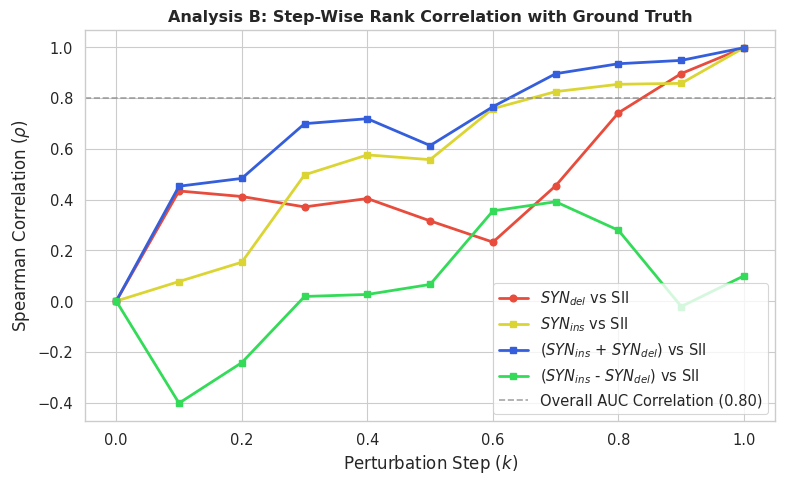

In [20]:
# =========================================================
# ANALYSIS B: Step-Wise Correlation (Tracking OOD Degradation)
# =========================================================
del_corrs = []
ins_corrs = []
sum_corrs = []
dif_corrs = []

for k in range(num_steps):
    # Extract the vector of all images at this specific step k
    sii_k = sii_mat[:, k]
    del_k = del_mat[:, k]
    ins_k = ins_mat[:, k]
    sum_k = sum_mat[:, k]
    dif_k = dif_mat[:, k]
    
    # Calculate Spearman rho at this exact step (ignoring step 0 where everything is 0)
    if k == 0:
        del_corrs.append(0.0)
        ins_corrs.append(0.0)
        sum_corrs.append(0.0)
        dif_corrs.append(0.0)
    else:
        rho_del, _ = stats.spearmanr(del_k, sii_k)
        rho_ins, _ = stats.spearmanr(ins_k, sii_k)
        rho_sum, _ = stats.spearmanr(sum_k, sii_k)
        rho_dif, _ = stats.spearmanr(dif_k, sii_k)
        del_corrs.append(rho_del)
        ins_corrs.append(rho_ins)
        sum_corrs.append(rho_sum)
        dif_corrs.append(rho_dif)

plt.figure(figsize=(8, 5))
plt.plot(pert_steps, del_corrs, marker='o', color='#E74C3C', label='$SYN_{del}$ vs SII', linewidth=2)
plt.plot(pert_steps, ins_corrs, marker='s', color='#DBD534', label='$SYN_{ins}$ vs SII', linewidth=2)
plt.plot(pert_steps, sum_corrs, marker='s', color='#345EDB', label='($SYN_{ins}$ + $SYN_{del}$) vs SII', linewidth=2)
plt.plot(pert_steps, dif_corrs, marker='s', color='#34DB58', label='($SYN_{ins}$ - $SYN_{del}$) vs SII', linewidth=2)

plt.title('Analysis B: Step-Wise Rank Correlation with Ground Truth', weight='bold')
plt.xlabel('Perturbation Step ($k$)', fontsize=12)
plt.ylabel('Spearman Correlation ($\\rho$)', fontsize=12)
plt.axhline(y=0.80, color='gray', linestyle='--', alpha=0.7, label='Overall AUC Correlation (0.80)')
plt.legend()
plt.tight_layout()
# plt.savefig('analysis_B_stepwise_corr.png', dpi=300)
# plt.close()
print("Saved Analysis B -> 'analysis_B_stepwise_corr.png'")


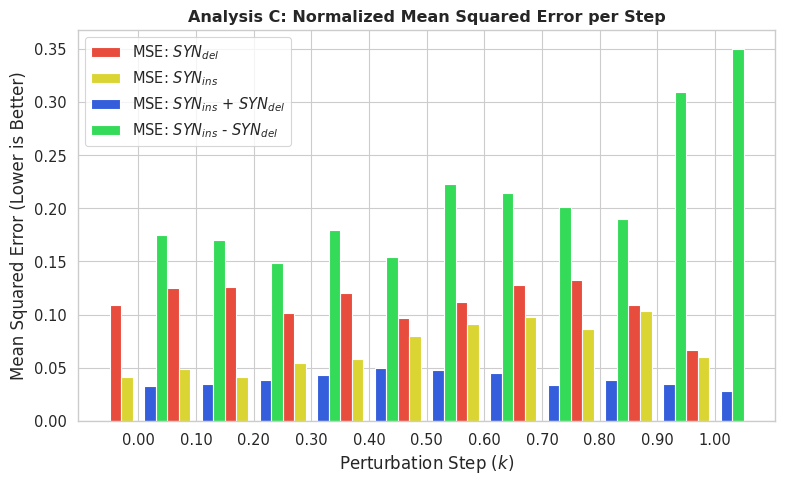

In [21]:
# =========================================================
# ANALYSIS C: Mean Squared Error (Time-to-Synergy Deviation)
# =========================================================
# To compute a fair MSE, we Min-Max scale the curves per-image 
# so they are all on a comparable 0 to 1 scale.
def min_max_normalize_2d(matrix):
    mins = matrix.min(axis=1, keepdims=True)
    maxs = matrix.max(axis=1, keepdims=True)
    # Avoid division by zero
    range_val = np.where((maxs - mins) == 0, 1e-8, (maxs - mins))
    return (matrix - mins) / range_val

sii_norm = min_max_normalize_2d(sii_mat)
del_norm = min_max_normalize_2d(del_mat)
ins_norm = min_max_normalize_2d(ins_mat)
sum_norm = min_max_normalize_2d(sum_mat)
dif_norm = min_max_normalize_2d(dif_mat)

# Calculate step-wise MSE
mse_del = np.mean((sii_norm - del_norm)**2, axis=0)
mse_ins = np.mean((sii_norm - ins_norm)**2, axis=0)
mse_sum = np.mean((sii_norm - sum_norm)**2, axis=0)
mse_dif = np.mean((sii_norm - dif_norm)**2, axis=0)

plt.figure(figsize=(8, 5))
plt.bar(np.arange(num_steps) - 0.4, mse_del, width=0.2, color='#E74C3C', label='MSE: $SYN_{del}$')
plt.bar(np.arange(num_steps) - 0.2, mse_ins, width=0.2, color='#DBD534', label='MSE: $SYN_{ins}$')
plt.bar(np.arange(num_steps) + 0.2, mse_sum, width=0.2, color='#345EDB', label='MSE: $SYN_{ins}$ + $SYN_{del}$')
plt.bar(np.arange(num_steps) + 0.4, mse_dif, width=0.2, color='#34DB58', label='MSE: $SYN_{ins}$ - $SYN_{del}$')
plt.xticks(np.arange(num_steps), [f"{s:.2f}" for s in pert_steps])

plt.title('Analysis C: Normalized Mean Squared Error per Step', weight='bold')
plt.xlabel('Perturbation Step ($k$)', fontsize=12)
plt.ylabel('Mean Squared Error (Lower is Better)', fontsize=12)
plt.legend()
plt.tight_layout()
# plt.savefig('analysis_C_mse.png', dpi=300)
# plt.close()
# print("Saved Analysis C -> 'analysis_C_mse.png'")

In [ ]:
import json
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_stepwise_curves(results_file="repope_evaluation_results.jsonl"):
    print(f"Loading curve data from {results_file}...")
    
    # 1. Define your exact perturbation steps for the X-axis
    pert_steps = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    num_steps = len(pert_steps)
    
    sii_curves = []
    del_curves = []
    ins_curves = []
    
    # 2. Extract Data
    with open(results_file, 'r') as f:
        for line in f:
            data = json.loads(line.strip())
            
            # Make sure the sample has the curves (skip if failed/missing)
            if "sii_curve" in data and "syn_del_synergy_curve" in data:
                sii_curves.append(data["sii_curve"])
                del_curves.append(data["syn_del_synergy_curve"])
                ins_curves.append(data["syn_ins_synergy_curve"])

    # Convert to 2D NumPy arrays: Shape (N_images, N_steps)
    sii_mat = np.array(sii_curves)
    del_mat = np.array(del_curves)
    ins_mat = np.array(ins_curves)
    
    N = sii_mat.shape[0]
    print(f"Successfully loaded {N} images with full step-wise curves.\n")
    
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    
    # =========================================================
    # ANALYSIS A: Mean Trajectory Plot (The "Shape" of Synergy)
    # =========================================================
    plt.figure(figsize=(8, 5))
    
    def plot_mean_with_std(matrix, color, label):
        mean_curve = np.mean(matrix, axis=0)
        # Using Standard Error of the Mean (SEM) for cleaner shaded regions
        sem_curve = np.std(matrix, axis=0) / np.sqrt(N) 
        plt.plot(pert_steps, mean_curve, color=color, label=label, linewidth=2.5)
        plt.fill_between(pert_steps, mean_curve - sem_curve, mean_curve + sem_curve, color=color, alpha=0.2)

    plot_mean_with_std(sii_mat, '#2C3E50', 'Exact SII (Ground Truth)')
    plot_mean_with_std(del_mat, '#E74C3C', 'Fast Deletion Synergy ($SYN_{del}$)')
    plot_mean_with_std(ins_mat, '#3498DB', 'Fast Insertion Synergy ($SYN_{ins}$)')
    
    plt.title('Analysis A: Average Synergy Trajectory over Perturbation Steps', weight='bold')
    plt.xlabel('Perturbation Step ($k$)', fontsize=12)
    plt.ylabel('Raw Synergy / Interaction Score', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.savefig('analysis_A_trajectory.png', dpi=300)
    plt.close()
    print("Saved Analysis A -> 'analysis_A_trajectory.png'")

    # =========================================================
    # ANALYSIS B: Step-Wise Correlation (Tracking OOD Degradation)
    # =========================================================
    del_corrs = []
    ins_corrs = []
    
    for k in range(num_steps):
        # Extract the vector of all images at this specific step k
        sii_k = sii_mat[:, k]
        del_k = del_mat[:, k]
        ins_k = ins_mat[:, k]
        
        # Calculate Spearman rho at this exact step (ignoring step 0 where everything is 0)
        if k == 0:
            del_corrs.append(0.0)
            ins_corrs.append(0.0)
        else:
            rho_del, _ = stats.spearmanr(del_k, sii_k)
            rho_ins, _ = stats.spearmanr(ins_k, sii_k)
            del_corrs.append(rho_del)
            ins_corrs.append(rho_ins)

    plt.figure(figsize=(8, 5))
    plt.plot(pert_steps, del_corrs, marker='o', color='#E74C3C', label='$SYN_{del}$ vs SII', linewidth=2)
    plt.plot(pert_steps, ins_corrs, marker='s', color='#3498DB', label='$SYN_{ins}$ vs SII', linewidth=2)
    
    plt.title('Analysis B: Step-Wise Rank Correlation with Ground Truth', weight='bold')
    plt.xlabel('Perturbation Step ($k$)', fontsize=12)
    plt.ylabel('Spearman Correlation ($\\rho$)', fontsize=12)
    plt.axhline(y=0.80, color='gray', linestyle='--', alpha=0.7, label='Overall AUC Correlation (0.80)')
    plt.legend()
    plt.tight_layout()
    plt.savefig('analysis_B_stepwise_corr.png', dpi=300)
    plt.close()
    print("Saved Analysis B -> 'analysis_B_stepwise_corr.png'")

    # =========================================================
    # ANALYSIS C: Mean Squared Error (Time-to-Synergy Deviation)
    # =========================================================
    # To compute a fair MSE, we Min-Max scale the curves per-image 
    # so they are all on a comparable 0 to 1 scale.
    def min_max_normalize_2d(matrix):
        mins = matrix.min(axis=1, keepdims=True)
        maxs = matrix.max(axis=1, keepdims=True)
        # Avoid division by zero
        range_val = np.where((maxs - mins) == 0, 1e-8, (maxs - mins))
        return (matrix - mins) / range_val

    sii_norm = min_max_normalize_2d(sii_mat)
    del_norm = min_max_normalize_2d(del_mat)
    ins_norm = min_max_normalize_2d(ins_mat)

    # Calculate step-wise MSE
    mse_del = np.mean((sii_norm - del_norm)**2, axis=0)
    mse_ins = np.mean((sii_norm - ins_norm)**2, axis=0)

    plt.figure(figsize=(8, 5))
    plt.bar(np.arange(num_steps) - 0.2, mse_del, width=0.4, color='#E74C3C', label='MSE: $SYN_{del}$')
    plt.bar(np.arange(num_steps) + 0.2, mse_ins, width=0.4, color='#3498DB', label='MSE: $SYN_{ins}$')
    plt.xticks(np.arange(num_steps), [f"{s:.2f}" for s in pert_steps])
    
    plt.title('Analysis C: Normalized Mean Squared Error per Step', weight='bold')
    plt.xlabel('Perturbation Step ($k$)', fontsize=12)
    plt.ylabel('Mean Squared Error (Lower is Better)', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.savefig('analysis_C_mse.png', dpi=300)
    plt.close()
    print("Saved Analysis C -> 'analysis_C_mse.png'")
    
    print("\nAll analyses completed! Check your working directory for the PNGs.")


### Paper plots

#### Configs

In [1]:
SAVE_DIR = "../figs"

In [2]:
import os
import glob
import json
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata, friedmanchisquare, wilcoxon
import itertools

def load_all_benchmark_data(base_dir="logs/results",
                            #dataset_name="repope_all"
                            ):
    """
    Crawls the directory structure to load all JSONL files, 
    automatically extracting the Model and Dataset from folder names.
    """
    all_data = []
    # Adjust this glob pattern based on your actual folder structure!
    # e.g., logs/llava/pope/ig_results.jsonl
    search_pattern = os.path.join(base_dir, "*", "*", "*.jsonl")
    file_list = glob.glob(search_pattern)
    
    print(f"[*] Found {len(file_list)} result files. Aggregating...")
    
    for file_path in file_list:
        # Extract metadata from the path 
        # (e.g., parts[-3] = model, parts[-2] = dataset)
        path_parts = os.path.normpath(file_path).split(os.sep)
        if len(path_parts) >= 3:
            model_name = path_parts[-3]
            dataset_name = path_parts[-2]
        else:
            model_name, dataset_name = "Unknown", "Unknown"
        
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    try:
                        row = json.loads(line)
                        # Ensure we don't overwrite if the JSON already has it
                        row['Model'] = row.get('model', model_name)
                        row['Dataset'] = row.get('dataset', dataset_name)
                        # Ensure explainer name is clean
                        row['Explainer'] = row.get('explainer', os.path.basename(file_path).replace('.jsonl', ''))
                        all_data.append(row)
                    except json.JSONDecodeError:
                        continue
                    
    df = pd.DataFrame(all_data)
    #df['Explainer'].replace('LXT', 'AttnLRP', inplace=True)
    df['Explainer'] = df['Explainer'].replace('LXT', 'AttnLRP')

    if "tok_norm_auc_ins" in df.columns.tolist():
        df["tok_srg_norm"] = df["tok_norm_auc_ins"] - df["tok_norm_auc_del"]
        df["tok_srg"] = df["tok_auc_ins"] - df["tok_auc_del"]
    if "img_norm_auc_ins" in df.columns.tolist():
        df["img_srg_norm"] = df["img_norm_auc_ins"] - df["img_norm_auc_del"]
        df["img_srg"] = df["img_auc_ins"] - df["img_auc_del"]
    
    # Optional: Calculate combined AUPC metrics if you saved curves instead of raw AUCs
    # ... (Insert your trapezoid np.trapezoid code here if needed) ...
    
    return df



# ==========================================
# 2. STATISTICAL TESTING
# ==========================================
def run_statistical_comparison(df, metric='img_ins_auc',
                               baseline_explainer='random', target_explainer='ours'):
    """Runs a Wilcoxon Signed-Rank test between two explainers."""
    print(f"\n--- Statistical Test: {target_explainer} vs {baseline_explainer} ({metric}) ---")
    
    # We need to compare them on the EXACT same images (Paired Test)
    pivot = df.pivot_table(index=['Model', 'Dataset', 'sample_idx'], 
                           columns='Explainer', 
                           values=metric).dropna()
    
    if baseline_explainer not in pivot.columns or target_explainer not in pivot.columns:
        print("[!] Explainers not found in data for paired testing.")
        return
        
    baseline_scores = pivot[baseline_explainer]
    target_scores = pivot[target_explainer]
    
    # Wilcoxon signed-rank test
    stat, p_value = stats.wilcoxon(target_scores, baseline_scores)
    
    mean_diff = target_scores.mean() - baseline_scores.mean()
    print(f"Mean Difference: {mean_diff:+.4f}")
    print(f"p-value        : {p_value:.2e}")
    if p_value < 0.05:
        print("Conclusion     : STATISTICALLY SIGNIFICANT DIFFERENCE (Reject Null)")
    else:
        print("Conclusion     : NO SIGNIFICANT DIFFERENCE")

# ==========================================
# 3. PUBLICATION PLOTS
# ==========================================

# ==========================================
# 1. MACRO BOXPLOT (Variance Distribution)
# ==========================================
def plot_macro_boxplot(df, metric='img_ins_auc', 
                       dataset_filter=None,
                       savefig=False, format="pdf"):
    """Generates a grouped boxplot. Filters by dataset if provided."""
    plot_df = df.copy()
    title_suffix = " (All Datasets)"
    
    if dataset_filter:
        plot_df = plot_df[plot_df['Dataset'] == dataset_filter]
        title_suffix = f" (Dataset: {dataset_filter})"
        
    if plot_df.empty:
        print(f"[!] No data found for dataset: {dataset_filter}")
        return
        
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.figure(figsize=(12, 6))
    
    ranking = plot_df.groupby('Explainer')[metric].median().sort_values(ascending=False).index
    
    ax = sns.boxplot(x='Explainer', y=metric, hue='Model', data=plot_df, 
                     order=ranking, palette='Set2', showfliers=False)
                     
    plt.title(f'Faithfulness score distribution across explainers{title_suffix}', weight='bold')
    plt.xlabel('XAI Method', weight='bold')
    plt.ylabel(metric)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title="Vision-Language Model", loc='best')
    
    filename = f'boxplot_{metric}_{dataset_filter or "global"}.{format}'
    plt.tight_layout()
    if savefig:
        filename = os.path.join(SAVE_DIR, filename)
        plt.savefig(filename, dpi=300, format=format)
        print(f"[*] Saved {filename}")
        #plt.close()
    plt.show()

# ==========================================
# 2. PARETO PLOT (Speed vs. Performance)
# ==========================================
def plot_speed_vs_performance(df, perf_metric='img_ins_auc',
                              time_metric='xai_gen_time',
                              dataset_filter=None,
                              format="pdf",
                              savefig=False
                              ):
    """Scatter plot showing computation time vs accuracy."""
    plot_df = df.copy()
    title_suffix = " (All Datasets)"
    
    if dataset_filter:
        plot_df = plot_df[plot_df['Dataset'] == dataset_filter]
        title_suffix = f"\n(Dataset: {dataset_filter})"

    if plot_df.empty or time_metric not in plot_df.columns:
        print(f"[!] Missing data or time metrics for {dataset_filter or 'global'}")
        return

    agg_df = plot_df.groupby('Explainer').agg({
        perf_metric: 'mean',
        time_metric: 'mean'
    }).reset_index()
    
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.figure(figsize=(8, 6))
    
    ax = sns.scatterplot(x=time_metric, y=perf_metric, data=agg_df, 
                         s=150, color="#ED481B", edgecolor='black')
    
    for line in range(0, agg_df.shape[0]):
         ax.text(agg_df[time_metric][line]*1.05, agg_df[perf_metric][line], 
                 agg_df['Explainer'][line], horizontalalignment='left', 
                 size='small', color='black', weight='semibold')

    plt.xscale('log')
    plt.title(f'Trade-off: Cost vs. Faithfulness{title_suffix}', weight='bold')
    plt.xlabel('Average Time per Image (Seconds, Log Scale)', weight='bold')
    plt.ylabel(r'Mean $\mathcal{F}_{syn}$', weight='bold')
    
    plt.axvline(agg_df[time_metric].median(), color='gray', linestyle='--', alpha=0.5)
    plt.axhline(agg_df[perf_metric].median(), color='gray', linestyle='--', alpha=0.5)
    
    filename = f'pareto_{perf_metric}_{dataset_filter or "global"}.{format}'
    plt.tight_layout()
    
    if savefig:
        filename = os.path.join(SAVE_DIR, filename)
        plt.savefig(filename, dpi=300, format=format)
        print(f"[*] Saved {filename}")
        #plt.close()
    plt.show()
    
# ==========================================
# 3. MEAN RANK & SIGNIFICANCE (Dynamic Winner Anchor)
# ==========================================
def compute_and_plot_ranks(df, metric='img_ins_auc',
                           ascending_metric=False,
                           dataset_filter=None,
                           savefig=False,
                           format="pdf"
                           ):
    """
    Computes the Mean Rank per image and plots a sleek bar chart.
    Statistical significance (symbols only) is cleanly tabulated on the right margin,
    with a legend explaining the symbols.
    """
    print("--- Generating Final Mean Rank Plot (Symbols Only) ---")
    plot_df = df.copy()
    title_suffix = "All Datasets"
    
    if dataset_filter:
        plot_df = plot_df[plot_df['Dataset'] == dataset_filter]
        title_suffix = f"Dataset: {dataset_filter}"

    pivot = plot_df.pivot_table(
        index=['Model', 'Dataset', 'sample_idx'], 
        columns='Explainer', 
        values=metric
    ).dropna()
    
    if pivot.empty:
        print("[!] No valid paired data found. Skipping.")
        return

    # 1. Ranks and Mean Ranks
    ranks_df = pivot.rank(axis=1, ascending=ascending_metric)
    mean_ranks = ranks_df.mean().sort_values()
    k = len(mean_ranks)
    best_explainer = mean_ranks.index[0]

    # 2. Statistical Testing (Wilcoxon vs Winner with Bonferroni correction)
    stats_results = {}
    num_comparisons = k - 1 
    
    for exp in mean_ranks.index:
        if exp == best_explainer:
            stats_results[exp] = {'p_adj': 1.0, 'sig': '-'}
            continue
            
        _, p_raw = wilcoxon(pivot[best_explainer], pivot[exp])
        p_adj = min(1.0, p_raw * num_comparisons)
        
        if p_adj < 0.001: sig_text = '***'
        elif p_adj < 0.01: sig_text = '**'
        elif p_adj < 0.05: sig_text = '*'
        else: sig_text = 'ns'
            
        stats_results[exp] = {'p_adj': p_adj, 'sig': sig_text}

    # 3. Plotting Setup
    sns.set_theme(style="white", context="paper", font_scale=1.2)
    fig, ax = plt.subplots(figsize=(9, 6), dpi=300)
    
    y_pos = np.arange(k)
    uniform_color = "#DC610F" 
    
    # Draw horizontal bars
    bars = ax.barh(y_pos, mean_ranks.values, color=uniform_color, 
                   height=0.6, edgecolor='black', linewidth=1.2, alpha=0.85)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(mean_ranks.index, weight='bold')
    ax.invert_yaxis() # Rank 1 at the top
    
    # 4. Text Annotations and Significance Margin
    max_rank = mean_ranks.max()
    
    # We need less space now, so we shrink the right margin slightly
    ax.set_xlim(0, max_rank * 1.30) 
    
    # Table Header
    ax.text(max_rank * 1.20, -0.8, "Sig.\nvs Top", ha='center', va='center', 
            weight='bold', fontsize=11, color='#2c3e50')
    
    # Subtle separator line
    ax.axvline(max_rank * 1.10, color='gray', linestyle=':', linewidth=1.5, alpha=0.5)

    for i, (exp, val) in enumerate(mean_ranks.items()):
        # Bar value annotation
        ax.text(val + 0.1, i, f"{val:.2f}", va='center', fontsize=10, weight='bold', color='#2c3e50')
        
        # Table row annotation (Symbols only)
        if exp == best_explainer:
            p_text = "Control"
            font_w = 'bold'
        else:
            sig = stats_results[exp]['sig']
            p_text = sig
            font_w = 'bold' if sig in ['ns', '***', '**', '*'] else 'normal'
            
        # Draw the symbol
        ax.text(max_rank * 1.20, i, p_text, ha='center', va='center', 
                fontsize=13 if p_text in ['***', '**', '*'] else 11, 
                weight=font_w, color='#2c3e50')

    # 5. Add Legend for Significance Symbols
    legend_text = "*** $p < 0.001$\n ** $p < 0.01$\n  * $p < 0.05$\n ns  not sig."
    props = dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.95, edgecolor='gray')
    ax.text(0.97, -0.14, legend_text, transform=ax.transAxes, fontsize=10,
            verticalalignment='bottom', horizontalalignment='right', 
            bbox=props, family='monospace')

    # 6. Formatting
    ax.set_xlabel('Average Rank (Lower is Better)', weight='bold', labelpad=10)
    ax.set_title(f'Mean Rank & Ordinal Significance ({title_suffix})', weight='bold', pad=25, fontsize=14)
    
    # Remove borders
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.grid(axis='x', linestyle='--', alpha=0.4)

    plt.tight_layout()
    
    filename = f'ranks_{metric}_{dataset_filter or "global"}.{format}'
    plt.tight_layout()
    if savefig:
        filename = os.path.join(SAVE_DIR, filename)
        plt.savefig(filename, dpi=300, bbox_inches='tight', format=format)
        print(f"[*] Saved {filename}")
        #plt.close()
    plt.show()


def global_ranking_and_friedman_test(df, metric='img_ins_auc',
                                     savefig=False,
                                     format="pdf"):
    """
    Ranks all explainers globally, runs a Friedman test, and generates 
    a Pairwise Significance Heatmap with Bonferroni correction.
    """
    print(f"\n{'='*50}\n[*] GLOBAL RANKING & STATISTICAL ANALYSIS ({metric})\n{'='*50}")

    # 1. Pivot the data so each row is a unique sample, and columns are the explainers
    # We group by Model, Dataset, and Image ID to ensure perfect paired matching.
    pivot = df.pivot_table(
        index=['Model', 'Dataset', 'sample_idx'], 
        columns='Explainer', 
        values=metric
    ).dropna() # Drop rows where ANY explainer failed/crashed
    
    explainers = pivot.columns.tolist()
    k = len(explainers)
    
    print(f"[*] Valid Paired Samples: {len(pivot)} (Evaluated successfully by ALL {k} explainers)")
    
    # 2. Print the Global Mean Ranking
    print("\n--- Mean Scores (Global) ---")
    mean_scores = pivot.mean().sort_values(ascending=False)
    for rank, (exp, score) in enumerate(mean_scores.items(), 1):
        print(f"{rank}. {exp:<20} : {score:.4f}")

    # 3. The Friedman Test
    # Unpack the columns into separate arrays for the test
    args = [pivot[col] for col in explainers]
    stat, p_value = stats.friedmanchisquare(*args)
    
    print("\n--- Step 1: Friedman Test ---")
    print(f"Chi-Square Stat : {stat:.3f}")
    print(f"p-value         : {p_value:.2e}")
    
    if p_value >= 0.05:
        print("[!] No significant difference found among the explainers. Stopping here.")
        return
    else:
        print("[*] Significant difference detected! Proceeding to Post-Hoc Pairwise tests.")

    # 4. Post-Hoc Pairwise Wilcoxon with Bonferroni Correction
    num_comparisons = (k * (k - 1)) / 2
    print(f"\n--- Step 2: Pairwise Tests (Bonferroni Penalty Multiplier: {num_comparisons}) ---")
    
    # Create an empty matrix to store the adjusted p-values
    p_matrix = pd.DataFrame(1.0, index=mean_scores.index, columns=mean_scores.index)
    
    for exp1, exp2 in itertools.combinations(mean_scores.index, 2):
        # Run standard Wilcoxon
        w_stat, p_val_raw = stats.wilcoxon(pivot[exp1], pivot[exp2])
        
        # Apply Bonferroni Correction (multiply p-value by number of comparisons)
        p_val_adj = min(1.0, p_val_raw * num_comparisons) 
        
        # Store symmetrically in the matrix
        p_matrix.loc[exp1, exp2] = p_val_adj
        p_matrix.loc[exp2, exp1] = p_val_adj

    # 5. Plot the Pairwise Significance Heatmap
    plot_significance_heatmap(p_matrix, metric, savefig=savefig, format=format)


def plot_significance_heatmap(p_matrix, metric, savefig=False,
                              format="pdf"):
    """
    Plots a heatmap showing which explainers are significantly different from each other.
    Green = Significantly Different (p < 0.05)
    Red/Gray = Statistically Tied (p >= 0.05)
    """
    sns.set_theme(style="white", context="paper", font_scale=1.1)
    plt.figure(figsize=(10, 8))
    
    # Create a binary mask: True if significant, False if not
    is_significant = p_matrix < 0.05
    
    # Plotting: We use a custom colormap. 
    # Let's show the actual adjusted p-values, but color them by significance.
    cmap = sns.diverging_palette(10, 130, as_cmap=True)
    
    # Generate a mask for the upper triangle so we don't duplicate data visually
    mask = np.triu(np.ones_like(p_matrix, dtype=bool))
    
    ax = sns.heatmap(
        p_matrix, mask=mask, annot=True, fmt=".3f", cmap="coolwarm_r", 
        vmin=0, vmax=0.1, linewidths=.5, cbar_kws={"label": "Adjusted p-value"}
    )
    
    plt.title(f'Pairwise Statistical Significance ({metric})\n(Bonferroni-Adjusted Wilcoxon, p < 0.05)', weight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    if savefig:
        savepath = os.path.join(SAVE_DIR, f'pairwise_significance_{metric}.{format}')
        plt.savefig(savepath, dpi=300, format=format)
    plt.show()


def generate_latex_table(df, metric='img_ins_auc'):
    """
    Automatically generates a Pandas Pivot Table and exports the LaTeX code
    for you to copy-paste directly into Overleaf!
    """
    print(f"\n--- Generating LaTeX Table for {metric} ---")
    pivot = df.pivot_table(index='Explainer', columns=['Model', 'Dataset'], 
                           values=metric, aggfunc='mean')
    
    # Sort explainers by their overall average across all columns
    pivot['Overall_Mean'] = pivot.mean(axis=1)
    pivot = pivot.sort_values(by='Overall_Mean', ascending=False).drop(columns=['Overall_Mean'])
    
    print(pivot.to_latex(float_format="%.3f"))
    return pivot



In [3]:
df = load_all_benchmark_data(base_dir="../logs/results/",
                            #dataset_name="repope_all"
                            )

[*] Found 108 result files. Aggregating...


In [4]:
# plaus_cols = ["time_plausibility", "plaus_obj_iou", "plaus_point_game", "plaus_energy_score",
#               "note", "category", "parse_success", "decision_token_idx", "decision_token_str", "image_id", "text"]

# df = df.drop(labels=plaus_cols, axis=1, errors="ignore")

col_to_keep = ["sample_idx", "question", "Explainer", "xai_gen_time", 'label',
               "syn_synergy_auc", "syn_synergy_norm_auc",
                'syn_del_norm_auc', 'syn_ins_norm_auc', 'syn_del_auc', 'syn_ins_auc',
               "Model", "Dataset", 'tok_srg_norm', 'tok_srg', 'img_srg_norm', 'img_srg',
               'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
               'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del', 'tok_auc_ins',
               'prediction'
               ]
df = df[col_to_keep]


In [5]:
df = df.dropna()

In [20]:
df.Model.unique()

array(['internvl', 'qwenvl', 'llava'], dtype=object)

In [31]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_score_scatter_per_dataset(df, metric='img_srg', model_filter=None, format="pdf", savefig=False, save_dir="figs"):
    """
    Generates a grid of scatterplots (one per dataset) showing the raw score 
    distribution for each explainer. Overlays a high-contrast outline boxplot.
    Optionally filters the data to plot results for only a specific VLM.
    """
    plot_df = df.dropna(subset=[metric]).copy()
    
    # Apply model filter if specified
    if model_filter:
        plot_df = plot_df[plot_df['Model'] == model_filter]
        
    if plot_df.empty:
        model_msg = f" for model '{model_filter}'" if model_filter else ""
        print(f"[!] No data found for metric '{metric}'{model_msg}.")
        return
        
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    
    # Sort explainers globally by median to ensure the X-axis order 
    # remains perfectly consistent across all dataset subplots
    ranking = plot_df.groupby('Explainer')[metric].median().sort_values(ascending=False).index
    
    # 1. Tweak the scatter plot for high-density data
    g = sns.catplot(
        data=plot_df, 
        x='Explainer', 
        y=metric, 
        col='Dataset',
        col_wrap=3,          
        kind='strip',        
        jitter=0.15,
        alpha=0.1,
        s=2,
        palette='Set2',
        order=ranking,
        hue='Explainer',     
        legend=False,
        height=5, 
        aspect=1.3,
        sharey=False         
    )
    
    # 2. Make the boxplot strictly outlines so it sits cleanly on top of the dense data
    g.map_dataframe(
        sns.boxplot, 
        x='Explainer', 
        y=metric, 
        order=ranking,
        boxprops=dict(facecolor='none', edgecolor='black', linewidth=1.5), 
        whiskerprops=dict(color='black', linewidth=1.5),
        capprops=dict(color='black', linewidth=1.5),
        medianprops=dict(color='#d95f02', linewidth=2.5), 
        showfliers=False     
    )
    
    # Add a global title if a specific model is filtered
    if model_filter:
        g.fig.subplots_adjust(top=0.85)
        g.fig.suptitle(f"Model: {model_filter}", weight='bold', fontsize=16)
        
    # Formatting titles and axes
    g.set_titles("{col_name}", weight='bold')
    if metric == "syn_synergy_norm_auc":
        metric_sym = r"Raw $\mathcal{F}_{syn}$ Score"
    elif metric == "tok_srg_norm":
        metric_sym = r"Raw $\mu_{T}^{srg}$ Score"
    elif metric == "img_srg_norm":
        metric_sym = r"Raw $\mu_{I}^{srg}$ Score"
    else:
        metric_sym = f"Raw ({metric}) Score"

    g.set_axis_labels("XAI Method", metric_sym, weight='bold')
    
    # Rotate x-axis labels for readability
    for ax in g.axes.flat:
        ax.set_xticks(range(len(ranking)))
        ax.set_xticklabels(ranking, rotation=45, ha='right')
    
    plt.tight_layout()
    
    if savefig:
        os.makedirs(save_dir, exist_ok=True)
        # Update filename to prevent overwriting global plots
        file_suffix = f"_{model_filter}" if model_filter else ""
        filename = os.path.join(save_dir, f'scatter_raw_{metric}{file_suffix}.{format}')
        plt.savefig(filename, dpi=300, format=format)
        print(f"[*] Saved {filename}")
        
    plt.show()

In [35]:
metric = "tok_srg_norm"

[*] Saved ../figs/scatter_raw_tok_srg_norm_qwenvl.pdf


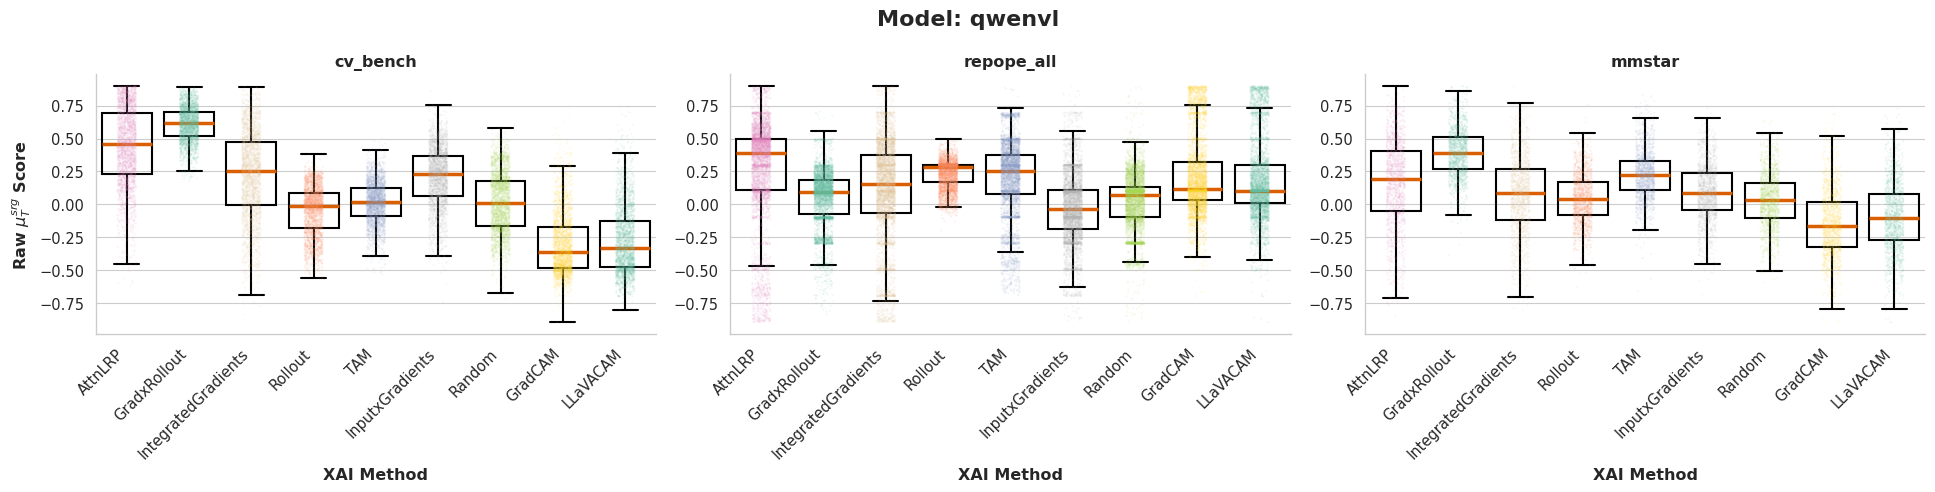

In [36]:
plot_score_scatter_per_dataset(
    df,
    model_filter="qwenvl",
    metric=metric,     # Or 'tok_srg', 'img_ins_auc', etc.
    savefig=True, 
    save_dir=SAVE_DIR,
    format="pdf"          # PDF is ideal for NeurIPS LaTeX compilation
)

[*] Saved ../figs/scatter_raw_tok_srg_norm_internvl.pdf


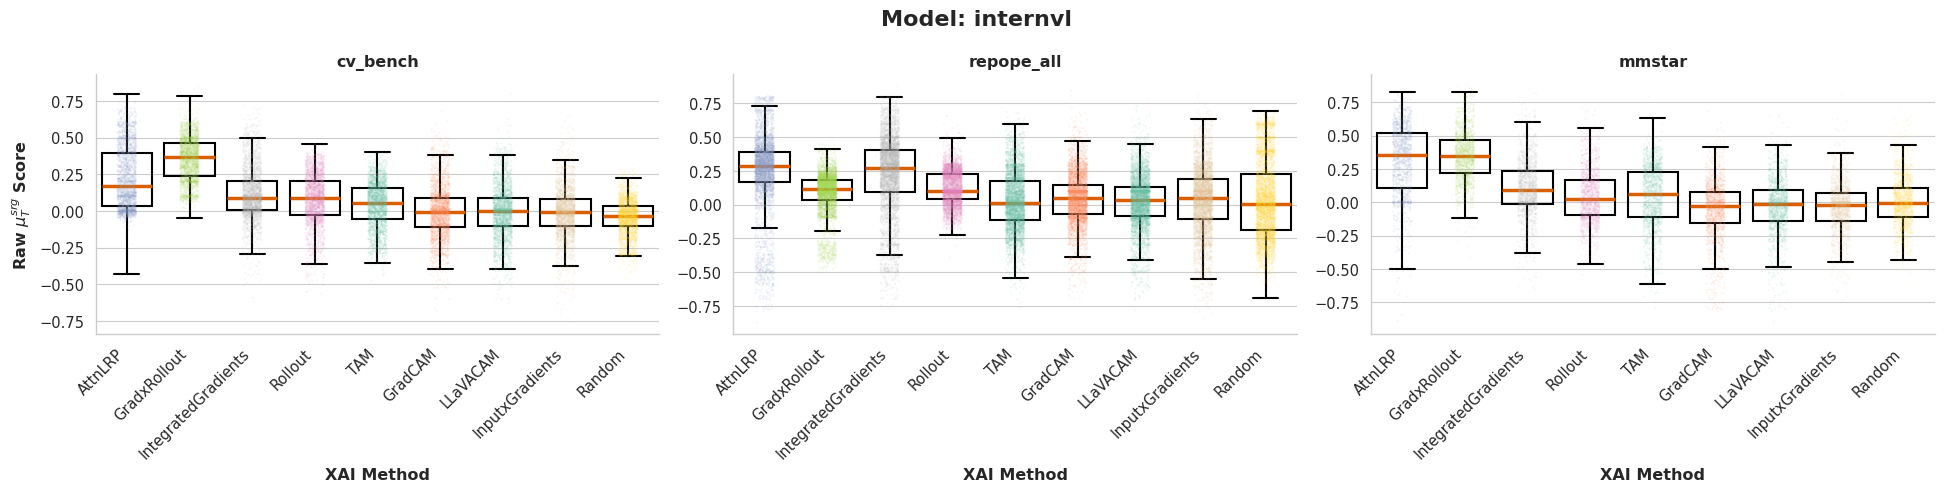

In [39]:
plot_score_scatter_per_dataset(
    df,
    model_filter="internvl",
    metric=metric,     # Or 'tok_srg', 'img_ins_auc', etc.
    savefig=True, 
    save_dir=SAVE_DIR,
    format="pdf"          # PDF is ideal for NeurIPS LaTeX compilation
)

[*] Saved ../figs/scatter_raw_tok_srg_norm_llava.pdf


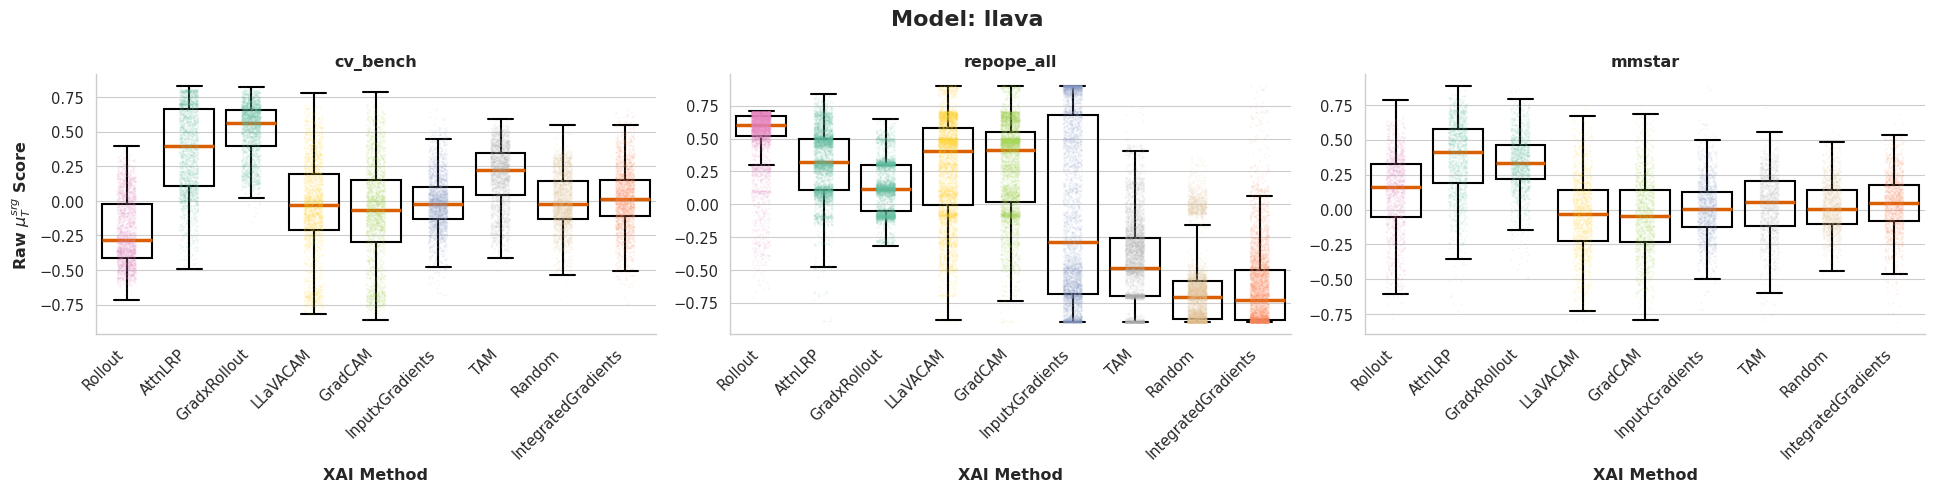

In [38]:
plot_score_scatter_per_dataset(
    df,
    model_filter="llava",
    metric=metric,     # Or 'tok_srg', 'img_ins_auc', etc.
    savefig=True, 
    save_dir=SAVE_DIR,
    format="pdf"          # PDF is ideal for NeurIPS LaTeX compilation
)

#### C-Macro players

In [20]:


def load_all_correlation_data(base_dir="logs/correlation",
                            #dataset_name="repope_all"
                            ):
    """
    Crawls the directory structure to load all JSONL files, 
    automatically extracting the Model and Dataset from folder names.
    """
    all_data = []
    # Adjust this glob pattern based on your actual folder structure!
    # e.g., logs/llava/pope/ig_results.jsonl
    search_pattern = os.path.join(base_dir, "*", "*", "*.jsonl")
    file_list = glob.glob(search_pattern)
    
    print(f"[*] Found {len(file_list)} result files. Aggregating...")
    
    for file_path in file_list:
        # Extract metadata from the path 
        # (e.g., parts[-3] = model, parts[-2] = dataset)
        path_parts = os.path.normpath(file_path).split(os.sep)
        if len(path_parts) >= 3:
            model_name = path_parts[-3]
            dataset_name = path_parts[-2]
        else:
            model_name, dataset_name = "Unknown", "Unknown"
        
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    try:
                        row = json.loads(line)
                        # Ensure we don't overwrite if the JSON already has it
                        row['Model'] = row.get('model', model_name)
                        row['Dataset'] = row.get('dataset', dataset_name)
                        # Ensure explainer name is clean
                        row['Explainer'] = row.get('explainer', os.path.basename(file_path).replace('.jsonl', '').split('_')[3])
                        all_data.append(row)
                    except json.JSONDecodeError:
                        continue
                    
    df = pd.DataFrame(all_data)
    df['Explainer'] = df["Explainer"].replace('Lxt', 'AttnLRP')
    pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    #pert_steps = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

    cols_to_drop = ['final_alignment', 'final_true_syn', 'synergy_refined_srg', 
       'final_redundancy', 'standard_srg']
    df = df.drop(cols_to_drop, axis=1)
    
    # Compute AUCs if they don't exist
    for col in ['syn_del', 'syn_ins', 'syn_del_norm', 'syn_ins_norm']:
        curve_col = f'{col}_synergy_curve'
        auc_col = f'{col}_auc'
        if auc_col not in df.columns and curve_col in df.columns:
            df[auc_col] = df[curve_col].apply(lambda val: np.trapezoid(val, x=pert_steps))

    # Calculate the unnormalized synergy
    if 'syn_ins_auc' in df.columns and 'syn_del_auc' in df.columns:
        df['synergy_srg_unorm'] = (df["syn_ins_auc"] + df["syn_del_auc"]) / 2.0

    if 'syn_ins_norm_auc' in df.columns and 'syn_del_norm_auc' in df.columns:
            df['synergy_srg_norm'] = (df["syn_ins_norm_auc"] + df["syn_del_norm_auc"]) / 2.0

    
    # Optional: Calculate combined AUPC metrics if you saved curves instead of raw AUCs
    # ... (Insert your trapezoid np.trapezoid code here if needed) ...
    
    return df



In [21]:
df_C_8 = load_all_correlation_data(base_dir="../logs/correlation/",
                            )

df_C_6 = load_all_correlation_data(base_dir="../logs/correlation_C_6/",
                            )

df_C_10 = load_all_correlation_data(base_dir="../logs/correlation_C_10/",
                            )



[*] Found 12 result files. Aggregating...
[*] Found 3 result files. Aggregating...
[*] Found 3 result files. Aggregating...


In [22]:
df_dict = {
    '4': df_C_6,
    '6': df_C_8,
    '8': df_C_10,
}

In [23]:
df_C_10.columns

Index(['sample_idx', 'image_id', 'question', 'label', 'prediction', 'time_sii',
       'sii_auc', 'sii_curve', 'time_syn', 'syn_del_synergy_curve',
       'syn_ins_synergy_curve', 'syn_ins_norm_synergy_curve',
       'syn_del_norm_synergy_curve', 'synergy_srg', 'Model', 'Dataset',
       'Explainer', 'syn_del_auc', 'syn_ins_auc', 'syn_del_norm_auc',
       'syn_ins_norm_auc', 'synergy_srg_unorm', 'synergy_srg_norm'],
      dtype='object')

In [26]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

def plot_c_correlation_consistency(c_dfs_dict, fsyn_col='img_srg', sii_col='exact_sii', 
                                   format="pdf", savefig=False, save_dir="figs"):
    """
    Plots the consistency of both Spearman and Pearson correlations between 
    F_syn and exact SII across different values of background macro-coalitions (C).
    """
    if not c_dfs_dict:
        print("[!] No DataFrames provided.")
        return

    results = []
    sorted_c_values = sorted(c_dfs_dict.keys())
    
    for c_val in sorted_c_values:
        df_c = c_dfs_dict[c_val].dropna(subset=[fsyn_col, sii_col])
        
        if df_c.empty:
            print(f"[!] Skipping C={c_val}: missing data for the specified columns.")
            continue
            
        # Compute both correlations
        spearman_corr, _ = spearmanr(df_c[fsyn_col], df_c[sii_col])
        pearson_corr, _ = pearsonr(df_c[fsyn_col], df_c[sii_col])
        
        results.append({'C': c_val, 'Correlation': spearman_corr, 'Metric': r'Spearman ($\rho$)'})
        results.append({'C': c_val, 'Correlation': pearson_corr, 'Metric': r'Pearson ($r$)'})
        
    results_df = pd.DataFrame(results)
    
    if results_df.empty:
        print("[!] No valid correlations could be computed.")
        return

    # Plotting
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.figure(figsize=(9, 5))
    
    # Plot both metrics using the 'hue' parameter
    ax = sns.lineplot(
        data=results_df, 
        x='C', 
        y='Correlation', 
        hue='Metric',
        style='Metric',      # Different line styles (solid vs dashed) for accessibility
        markers=['s', 'o'],  # Square for Spearman, Circle for Pearson
        markersize=9, 
        linewidth=2.5,
        palette=['#d95f02', '#1b9e77']  # Distinct colors
    )
    
    # Formatting
    plt.title('Approximation Consistency across Background Coalitions ($C$)', weight='bold')
    plt.xlabel('Number of Background Macro-Coalitions ($C$)', weight='bold')
    plt.ylabel('Correlation Coefficient', weight='bold')
    
    # Dynamically set Y-axis to frame the data well, but bounded up to 1.02
    y_min = max(0.0, results_df['Correlation'].min() - 0.1)
    plt.ylim(y_min, 1.05)
    plt.xticks(sorted_c_values)
    
    # Annotate points intelligently to avoid overlap
    for index, row in results_df.iterrows():
        # Offset Spearman text up and Pearson text down
        if 'Spearman' in row['Metric']:
            y_offset = 0.015
            va = 'bottom'
        else:
            y_offset = -0.015
            va = 'top'
            
        ax.text(row['C'], row['Correlation'] + y_offset, f"{row['Correlation']:.3f}", 
                ha='center', va=va, fontsize=10, color='black')

    # Adjust legend position
    plt.legend(title="Metric", loc='lower right')
    plt.tight_layout()
    
    if savefig:
        os.makedirs(save_dir, exist_ok=True)
        filename = os.path.join(save_dir, f'c_correlation_combined.{format}')
        plt.savefig(filename, dpi=300, format=format)
        print(f"[*] Saved {filename}")
        
    plt.show()
    
    return results_df

def plot_c_time_consistency(c_dfs_dict, time_col='sii_time', format="pdf",
                            savefig=False, save_dir="figs"):
    """
    Plots the average computational time of the macro-coalition SII 
    as the number of background macro-coalitions (C) increases.
    """
    if not c_dfs_dict:
        print("[!] No DataFrames provided.")
        return

    results = []
    sorted_c_values = sorted(c_dfs_dict.keys())
    
    for c_val in sorted_c_values:
        df_c = c_dfs_dict[c_val].dropna(subset=[time_col])
        
        if df_c.empty:
            print(f"[!] Skipping C={c_val}: missing data for '{time_col}'.")
            continue
            
        # Collect mean time and standard deviation to show variance
        mean_time = df_c[time_col].mean()
        results.append({'C': c_val, 'Time': mean_time})
        
    results_df = pd.DataFrame(results)
    
    if results_df.empty:
        print("[!] No valid time data could be computed.")
        return

    # Plotting
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    plt.figure(figsize=(8, 5))
    
    ax = sns.lineplot(
        data=results_df, 
        x='C', 
        y='Time', 
        marker='D',          # Diamond markers
        markersize=9, 
        linewidth=2.5,
        color="#7570b3"      # A distinct purple tone
    )
    
    # Formatting
    plt.title('Computational Cost vs. Background Coalitions ($C$)', weight='bold')
    plt.xlabel('Number of Background Macro-Coalitions ($C$)', weight='bold')
    plt.ylabel('Average Execution Time (Seconds)', weight='bold')
    
    plt.xticks(sorted_c_values)
    
    # Annotate points with the exact time
    for index, row in results_df.iterrows():
        ax.text(row['C'], row['Time'] * 1.05, f"{row['Time']:.1f}s", 
                ha='center', va='bottom', fontsize=10, color='black', weight='semibold')

    plt.tight_layout()
    
    if savefig:
        os.makedirs(save_dir, exist_ok=True)
        filename = os.path.join(save_dir, f'c_time_scaling.{format}')
        plt.savefig(filename, dpi=300, format=format)
        print(f"[*] Saved {filename}")
        
    plt.show()
    
    return results_df



[*] Saved ../figs/c_correlation_combined.pdf


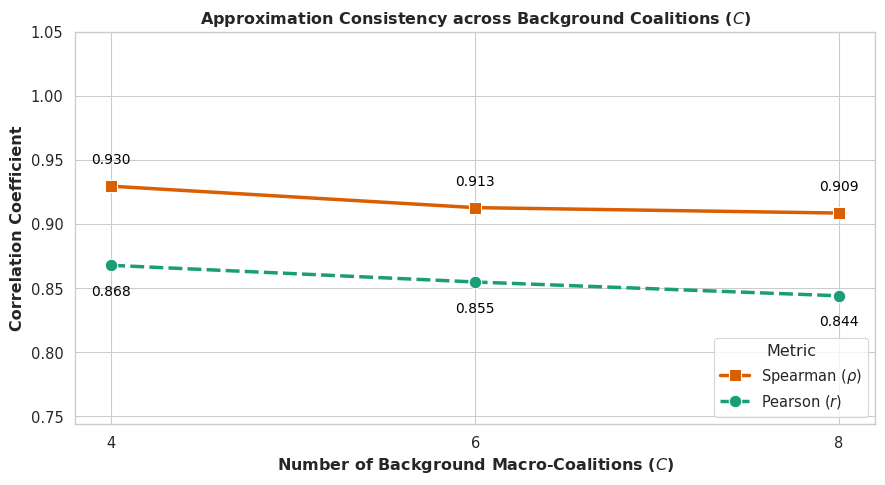

In [31]:
results_df = plot_c_correlation_consistency(df_dict, fsyn_col='synergy_srg_norm',
                                    sii_col='sii_auc', 
                                   #corr_method='pearson',
                                   format="pdf", 
                                   savefig=True, save_dir=SAVE_DIR)

[*] Saved ../figs/c_time_scaling.pdf


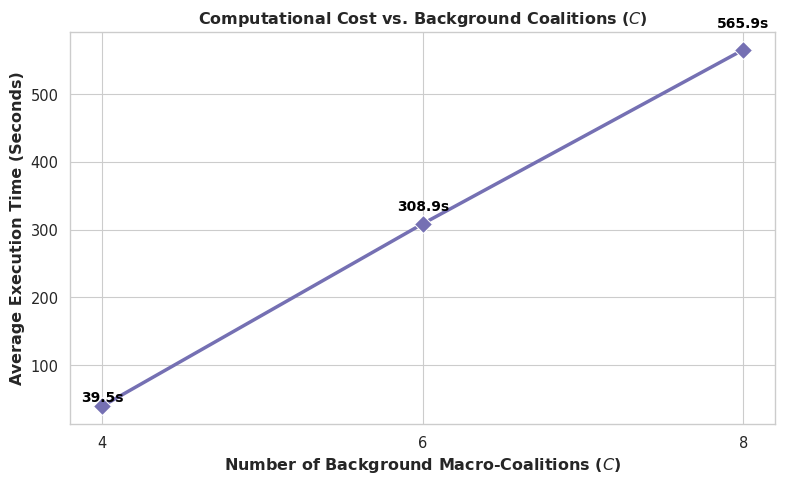

,C,Time
0,4,39.530014
1,6,308.881793
2,8,565.931014


In [32]:
plot_c_time_consistency(df_dict, time_col='time_sii', format="pdf",
                            savefig=True, save_dir=SAVE_DIR)

#### COCO Plausibility

In [17]:
df = load_all_benchmark_data(base_dir="../logs/results/",
                            #dataset_name="repope_all"
                            )

dataset_filter = "coco"
df_coco = df[df["Dataset"] == dataset_filter]

[*] Found 108 result files. Aggregating...


In [18]:
df_coco.columns

Index(['sample_idx', 'explainer', 'question', 'label', 'category',
       'prediction', 'parse_success', 'decision_token_idx',
       'decision_token_str', 'xai_gen_time', 'time_img_pert',
       'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
       'time_tok_pert', 'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del',
       'tok_auc_ins', 'time_syn_pert', 'syn_del_norm_auc', 'syn_ins_norm_auc',
       'syn_del_auc', 'syn_ins_auc', 'syn_synergy_auc', 'syn_synergy_norm_auc',
       'Model', 'Dataset', 'Explainer', 'image_id', 'text',
       'time_plausibility', 'plaus_obj_iou', 'plaus_point_game',
       'plaus_energy_score', 'note', 'tok_srg_norm', 'tok_srg', 'img_srg_norm',
       'img_srg'],
      dtype='object')

--- Generating Final Mean Rank Plot (Symbols Only) ---
[*] Saved ../figs/ranks_plaus_point_game_global.pdf


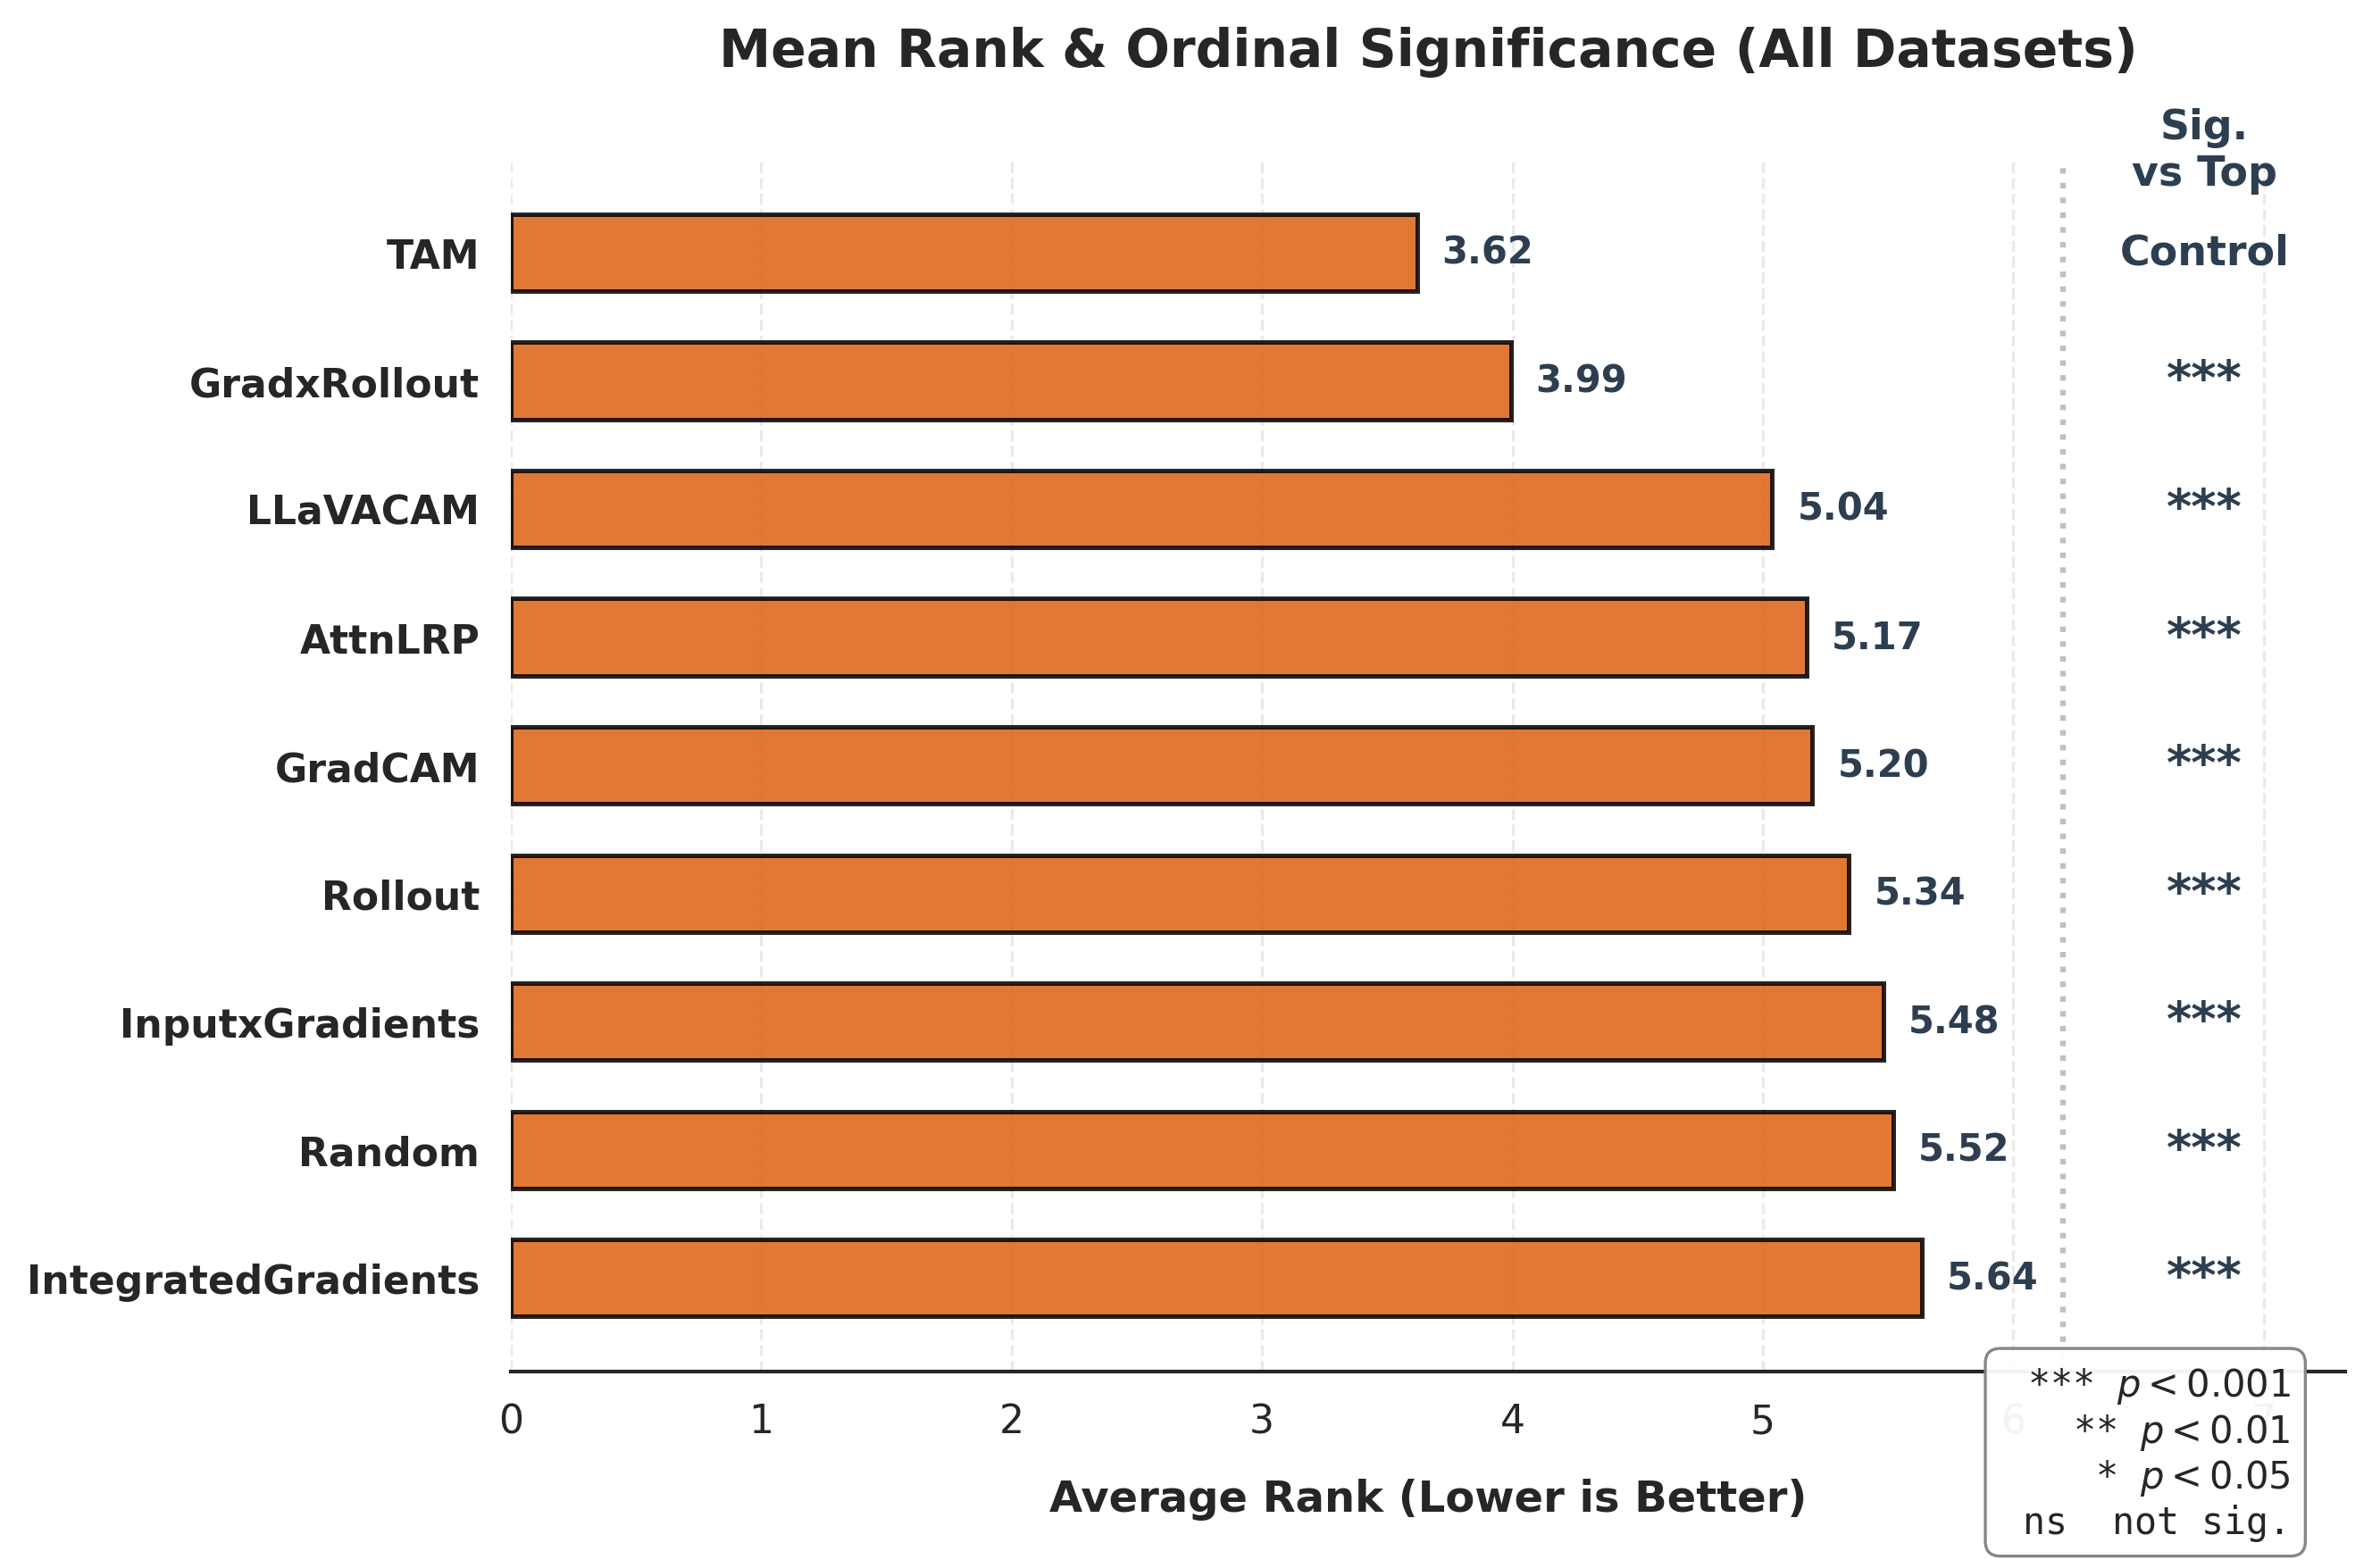

In [20]:
metric = 'plaus_point_game'
compute_and_plot_ranks(df, metric=metric,
                        ascending_metric=False, dataset_filter=None,
                        savefig=True)


[*] Saved ../figs/pareto_plaus_obj_iou_global.pdf


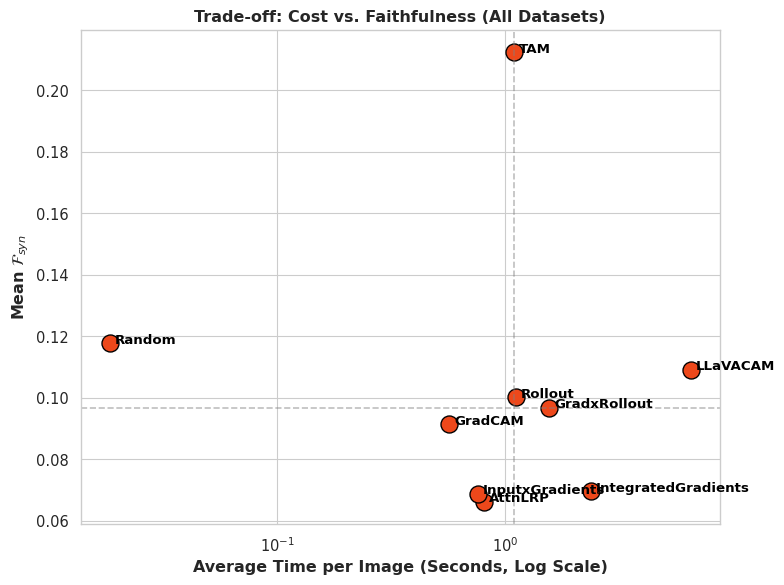

In [22]:
if 'xai_gen_time' in df.columns:
    plot_speed_vs_performance(df, perf_metric=metric,
                            time_metric='xai_gen_time',
                            dataset_filter=None, savefig=True)


#### Zero-state baselines

In [ ]:
df_gaussian_blur = load_all_benchmark_data(base_dir="../logs/results/",
                            #dataset_name="repope_all"
                            )
dataset_filter = "mmstar"
model = "internvl"
df_gaussian_blur = df_gaussian_blur[(df_gaussian_blur["Dataset"] == dataset_filter) &
                                    (df_gaussian_blur["Model"] == model)
                                    ]

df_zero_pad = load_all_benchmark_data(base_dir="../logs/zero_state_img/",
                            #dataset_name="repope_all"
                            )

In [ ]:
import pandas as pd
from scipy.stats import kendalltau, spearmanr

# 1. Calculate the mean F_syn score for each explainer in both dataframes
scores_blur = df_gaussian_blur.groupby('explainer')['syn_synergy_norm_auc'].mean().rename('score_blur')
scores_zero = df_zero_pad.groupby('explainer')['syn_synergy_norm_auc'].mean().rename('score_zero')

# 2. Merge them side-by-side into a single DataFrame
comparison_df = pd.concat([scores_blur, scores_zero], axis=1).dropna()

# 3. Rank the explainers (1.0 is the best score, so ascending=False)
comparison_df['rank_blur'] = comparison_df['score_blur'].rank(ascending=False).astype(int)
comparison_df['rank_zero'] = comparison_df['score_zero'].rank(ascending=False).astype(int)

# Sort by the original Blur baseline to clearly visualize if the hierarchy broke
comparison_df = comparison_df.sort_values(by='rank_blur')

print("--- Explainer Mean Scores & Rankings ---")
print(comparison_df[['rank_blur', 'rank_zero', 'score_blur', 'score_zero']])
print("\n" + "="*40 + "\n")

# 4. Compute the Rank Correlations
tau, _ = kendalltau(comparison_df['score_blur'], comparison_df['score_zero'])
rho, _ = spearmanr(comparison_df['score_blur'], comparison_df['score_zero'])

print(f"Kendall-Tau rank correlation (τ): {tau:.3f}")
print(f"Spearman rank correlation (ρ): {rho:.3f}")

# 5. Calculate the absolute and percentage score shift
comparison_df['absolute_shift'] = comparison_df['score_zero'] - comparison_df['score_blur']
comparison_df['percent_shift'] = (comparison_df['absolute_shift'] / comparison_df['score_blur']) * 100

print("--- Score Shift Analysis (OOD Impact) ---")
print(comparison_df[['score_blur', 'score_zero', 'absolute_shift', 'percent_shift']])

mean_shift = comparison_df['absolute_shift'].mean()
mean_pct_shift = comparison_df['percent_shift'].mean()

print("\n" + "="*40)
print(f"Average Absolute Shift: {mean_shift:.4f}")
print(f"Average Percentage Shift: {mean_pct_shift:.2f}%")
print("="*40)

#### Ground Truths

In [5]:
df = load_all_benchmark_data(base_dir="../logs/gt_exp/",
                            #dataset_name="repope_all"
                            )

[*] Found 9 result files. Aggregating...


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr

def plot_rebuttal_experiments(df):
    # Set global plotting style
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    
    # -----------------------------------------------------------------
    # PLOT 1: The Theoretical Bounds (Proving the Metric Spectrum)
    # -----------------------------------------------------------------
    plt.figure(figsize=(10, 6))
    
    # Extract bounds. Oracle and Anti-Oracle are columns, Random is an explainer row.
    # We take the mean of the bounds across the whole dataset
    oracle_mean = df['oracle_syn_auc'].mean()
    anti_oracle_mean = df['anti_oracle_syn_auc'].mean()
    
    # Extract Random baseline (assuming its explainer name in the JSON is 'Random' or 'random')
    random_df = df[df['explainer'].str.lower() == 'random']
    random_mean = random_df['syn_synergy_norm_auc'].mean() if not random_df.empty else 0.5
    
    # Get mean synergy for all REAL explainers (excluding Random)
    real_explainers = df[df['explainer'].str.lower() != 'random']
    explainer_means = real_explainers.groupby('explainer')['syn_synergy_norm_auc'].mean().sort_values(ascending=False)
    
    # Combine for the bar plot
    bounds_data = {'Oracle (Upper Bound)': oracle_mean}
    for exp, score in explainer_means.items():
        bounds_data[exp] = score
    bounds_data['Random Baseline'] = random_mean
    bounds_data['Anti-Oracle (Lower Bound)'] = anti_oracle_mean
    
    names = list(bounds_data.keys())
    scores = list(bounds_data.values())
    
    # Color coding: Green for bounds, gray for random, blue for explainers
    colors = ['#2ca02c'] + ['#1f77b4'] * len(explainer_means) + ['#7f7f7f', '#d62728']
    
    sns.barplot(x=scores, y=names, palette=colors)
    plt.title("Toy VLM Synergy Scores: Theoretical Bounds vs Explainers", fontweight='bold')
    plt.xlabel(r"Mean Synergy AUC ($\mathcal{F}_{syn}$)")
    plt.xlim(0, 1.05)
    plt.tight_layout()
    plt.savefig("rebuttal_fig1_bounds.png", dpi=300)
    plt.show()

    # -----------------------------------------------------------------
    # PLOT 2: Proximity vs Synergy (Image and Token Alignment)
    # -----------------------------------------------------------------
    # Group by explainer to get the average Proximity (AP) and Synergy per explainer
    agg_df = df.groupby('explainer').agg({
        'syn_synergy_norm_auc': 'mean',
        'proximity_img_ap': 'mean',  
        'proximity_txt_ap': 'mean'       # <-- Added Text AP
    }).reset_index()
    
    # Create a 1x2 grid of subplots
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # ==========================================
    # Subplot A: Image Proximity vs Synergy
    # ==========================================
    sns.scatterplot(
        data=agg_df, 
        x='proximity_img_ap', 
        y='syn_synergy_norm_auc', 
        hue='explainer', 
        s=150, 
        palette='tab10',
        ax=axes[0]
    )
    
    # Add labels to points
    for i in range(agg_df.shape[0]):
        axes[0].text(
            agg_df['proximity_img_ap'][i] + 0.005, 
            agg_df['syn_synergy_norm_auc'][i], 
            agg_df['explainer'][i], 
            horizontalalignment='left', 
            size='small', 
            color='black'
        )
    
    # Calculate correlation
    pearson_corr_img, _ = pearsonr(agg_df['proximity_img_ap'], agg_df['syn_synergy_norm_auc'])
    spearman_corr_img, _ = spearmanr(agg_df['proximity_img_ap'], agg_df['syn_synergy_norm_auc'])
    
    axes[0].set_title("A. Image Proximity vs Synergy Score", fontweight='bold')
    axes[0].set_xlabel("Image Ground Truth Proximity (Average Precision)")
    axes[0].set_ylabel(r"Toy VLM Synergy AUC ($\mathcal{F}_{syn}$)")
    
    # Display correlation text
    axes[0].annotate(f"Pearson $r$: {pearson_corr_img:.3f}\nSpearman $\\rho$: {spearman_corr_img:.3f}", 
                 xy=(0.05, 0.95), xycoords='axes fraction', 
                 ha='left', va='top', 
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=1))
    
    axes[0].legend([],[], frameon=False) 
    
    # ==========================================
    # Subplot B: Token Proximity vs Synergy
    # ==========================================
    sns.scatterplot(
        data=agg_df, 
        x='proximity_txt_ap', 
        y='syn_synergy_norm_auc', 
        hue='explainer', 
        s=150, 
        palette='tab10',
        ax=axes[1]
    )
    
    # Add labels to points
    for i in range(agg_df.shape[0]):
        axes[1].text(
            agg_df['proximity_txt_ap'][i] + 0.005, 
            agg_df['syn_synergy_norm_auc'][i], 
            agg_df['explainer'][i], 
            horizontalalignment='left', 
            size='small', 
            color='black'
        )
    
    # Calculate correlation
    pearson_corr_txt, _ = pearsonr(agg_df['proximity_txt_ap'], agg_df['syn_synergy_norm_auc'])
    spearman_corr_txt, _ = spearmanr(agg_df['proximity_txt_ap'], agg_df['syn_synergy_norm_auc'])
    
    axes[1].set_title("B. Token Proximity vs Synergy Score", fontweight='bold')
    axes[1].set_xlabel("Token Ground Truth Proximity (Average Precision)")
    axes[1].set_ylabel(r"Toy VLM Synergy AUC ($\mathcal{F}_{syn}$)")
    
    # Display correlation text
    axes[1].annotate(f"Pearson $r$: {pearson_corr_txt:.3f}\nSpearman $\\rho$: {spearman_corr_txt:.3f}", 
                 xy=(0.05, 0.95), xycoords='axes fraction', 
                 ha='left', va='top', 
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=1))
    
    axes[1].legend([],[], frameon=False) 

    # Finalize Layout
    plt.tight_layout()
    plt.savefig("rebuttal_fig2_alignment_multimodal.png", dpi=300)
    plt.show()
# Run the function
# plot_rebuttal_experiments(df)

/tmp/ipykernel_3380765/632644869.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=scores, y=names, palette=colors)


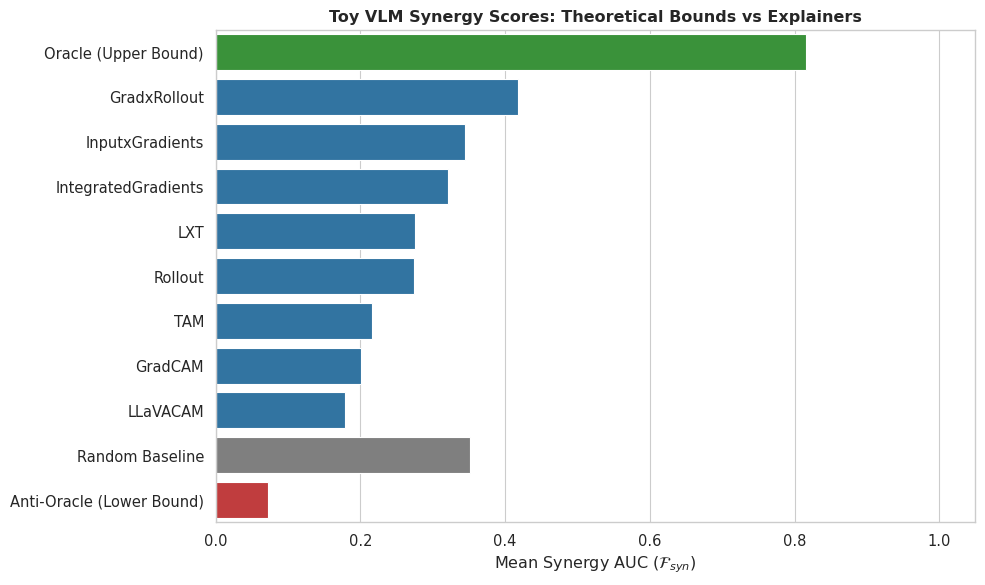

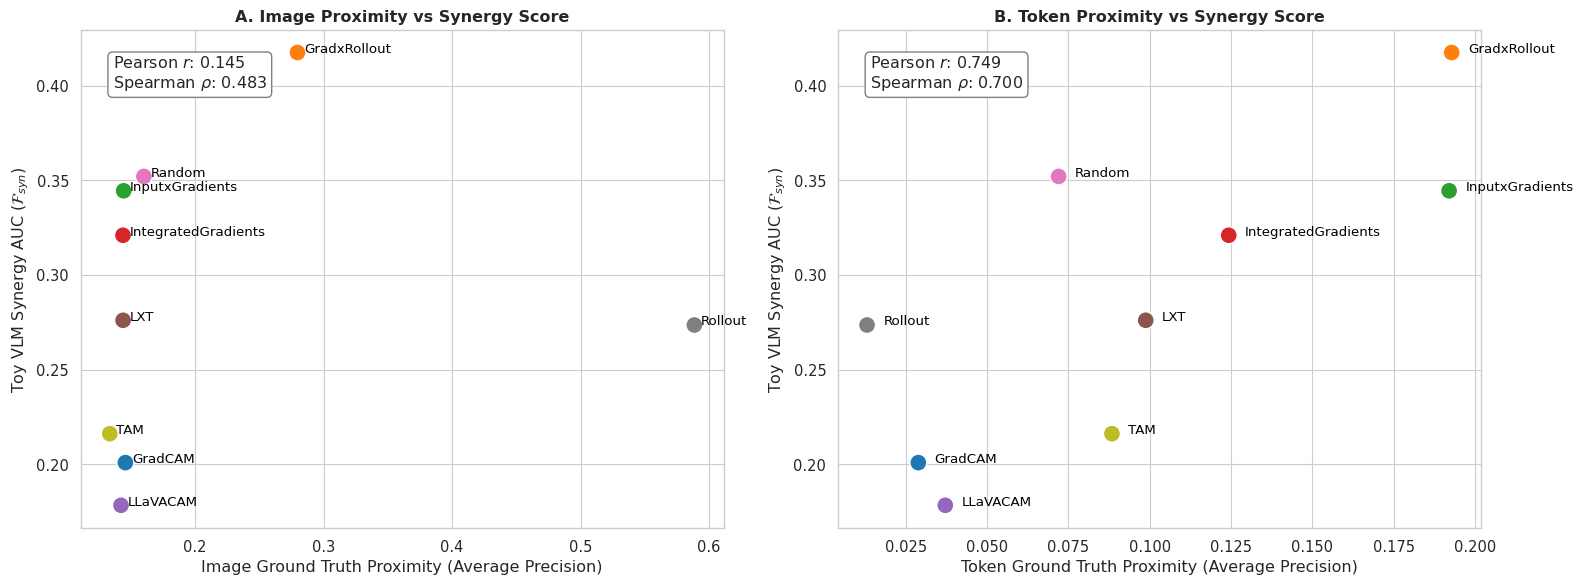

In [7]:
plot_rebuttal_experiments(df)

In [ ]:
import pandas as pd

# 1. Define the mapping for spelled-out numbers
word_to_digit = {
    "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4",
    "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9",
    "ten": "10", "eleven": "11", "twelve": "12", "thirteen": "13",
    "fourteen": "14", "fifteen": "15", "sixteen": "16", "seventeen": "17",
    "eighteen": "18", "nineteen": "19", "twenty": "20", 
    "none": "0"
}

def normalize_value(val):
    """Converts a value to a lowercase string and maps number words to digits."""
    # Handle NaN/None safely
    if pd.isna(val):
        return ""
        
    val_str = str(val).strip().lower()
    
    # If the word is in our dictionary, return the digit string. Otherwise, return the original string.
    return word_to_digit.get(val_str, val_str)

# 2. Apply normalization to create temporary comparison columns
df['norm_label'] = df['label'].apply(normalize_value)
df['norm_prediction'] = df['prediction'].apply(normalize_value)

# 3. Filter using the normalized columns
df_filtered = df[df['norm_label'] == df['norm_prediction']].copy()

print(f"Original samples: {len(df)}")
print(f"Correctly predicted samples: {len(df_filtered)}")

# Optional: Drop the temporary columns to keep your DataFrame clean before plotting
df_filtered = df_filtered.drop(columns=['norm_label', 'norm_prediction'])

# Now plot using the filtered data!
# plot_rebuttal_experiments(df_filtered)

In [8]:
import pandas as pd
import json

# Example usage assuming you load your jsonl file like this:
# df = pd.read_json("your_file.jsonl", lines=True)


def compare_baselines(df):
    # 1. Isolate the rows evaluating the Random explainer
    df_random = df[df['explainer'] == 'Random']
    
    # 2. Map the metric names to their respective columns in the dataframe
    metrics_map = {
        'Synergy (syn_synergy_norm_auc)': {
            'Oracle': 'oracle_syn_auc',
            'Random': 'syn_synergy_norm_auc',
            'Anti-Oracle': 'anti_oracle_syn_auc'
        },
        'Image Insertion (img_norm_auc_ins)': {
            'Oracle': 'oracle_img_norm_auc_ins',
            'Random': 'img_norm_auc_ins',
            'Anti-Oracle': 'anti_oracle_img_norm_auc_ins'
        },
        'Token Insertion (tok_norm_auc_ins)': {
            'Oracle': 'oracle_tok_norm_auc_ins',
            'Random': 'tok_norm_auc_ins',
            'Anti-Oracle': 'anti_oracle_tok_norm_auc_ins'
        }
    }
    
    # 3. Compute the mean for each column across the dataset
    results = []
    for metric_name, columns in metrics_map.items():
        results.append({
            'Metric': metric_name,
            'Oracle': df_random[columns['Oracle']].mean(),
            'Random': df_random[columns['Random']].mean(),
            'Anti-Oracle': df_random[columns['Anti-Oracle']].mean()
        })
        
    # 4. Format as a clean DataFrame for easy viewing/export
    comparison_df = pd.DataFrame(results)
    
    print("=== Baseline Comparison: Oracle vs Random vs Anti-Oracle ===")
    print(comparison_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    
    return comparison_df

# Run the comparison
df_summary = compare_baselines(df)

=== Baseline Comparison: Oracle vs Random vs Anti-Oracle ===
                            Metric  Oracle  Random  Anti-Oracle
    Synergy (syn_synergy_norm_auc)  0.8158  0.3520       0.0726
Image Insertion (img_norm_auc_ins)  0.8826  0.4852       0.0879
Token Insertion (tok_norm_auc_ins)  0.8316  0.5413       0.1410


#### Behavior on incorrect answers

In [19]:
df.columns

Index(['sample_idx', 'question', 'Explainer', 'xai_gen_time', 'label',
       'syn_synergy_auc', 'syn_synergy_norm_auc', 'syn_del_norm_auc',
       'syn_ins_norm_auc', 'syn_del_auc', 'syn_ins_auc', 'Model', 'Dataset',
       'tok_srg_norm', 'tok_srg', 'img_srg_norm', 'img_srg',
       'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
       'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del', 'tok_auc_ins',
       'prediction', 'is_correct'],
      dtype='object')

In [8]:
df_full = df.copy()

In [23]:
df_full.Model.unique()

array(['internvl', 'qwenvl', 'llava'], dtype=object)

In [64]:
dataset_filter = "mmstar"
model_name = "internvl"
target_metric = "syn_synergy_norm_auc"
df = df_full[(df_full['Dataset'] == dataset_filter) &
            (df_full['Model'] == model_name)]

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kendalltau
import json

target_metric = "syn_synergy_norm_auc"

# 2. Split the Data into Correct vs. Incorrect Predictions
# We strip whitespace and make uppercase to ensure clean matching (e.g. " B" == "B")
clean_preds = df['prediction'].astype(str).str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
clean_labels = df['label'].astype(str).str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)

df['is_correct'] = clean_preds == clean_labels

df_correct = df[df['is_correct'] == True]
df_incorrect = df[df['is_correct'] == False]

print(f"[*] Total Samples: {len(df)}")
print(f"[*] Correct Predictions: {len(df_correct)}")
print(f"[*] Incorrect Predictions (Hallucinations/Errors): {len(df_incorrect)}\n")

# 3. Calculate the Mean F_syn Scores for Both Groups
scores_correct = df_correct.groupby('Explainer')[target_metric].mean().sort_values(ascending=False)
scores_incorrect = df_incorrect.groupby('Explainer')[target_metric].mean().sort_values(ascending=False)

# 4. Rank the Explainers
ranks_correct = scores_correct.rank(ascending=False)
ranks_incorrect = scores_incorrect.rank(ascending=False)

# 5. Compute Ordinal Stability (Kendall's Tau)
# We align the indexes to ensure we are comparing the exact same explainers
aligned_incorrect = ranks_incorrect.reindex(ranks_correct.index)
tau, p_value = kendalltau(ranks_correct, aligned_incorrect)

print(f"{'='*50}\nLEADERBOARD: CORRECT PREDICTIONS\n{'='*50}")
for rank, (exp, score) in enumerate(scores_correct.items(), 1):
    print(f"{rank}. {exp:<15} : {score:.4f}")

print(f"\n{'='*50}\nLEADERBOARD: INCORRECT PREDICTIONS\n{'='*50}")
for rank, (exp, score) in enumerate(scores_incorrect.items(), 1):
    print(f"{rank}. {exp:<15} : {score:.4f}")

print(f"\n{'='*50}\nORDINAL STABILITY ANALYSIS\n{'='*50}")
print(f"Kendall's Tau Correlation: {tau:.3f} (p-value: {p_value:.3e})")
if tau > 0.8:
    print("Conclusion: Strong rank stability. The explainers behave consistently regardless of model accuracy.")
else:
    print("Conclusion: Rank shifting detected. The explainers are highly sensitive to whether the model hallucinates.")



[*] Total Samples: 13131
[*] Correct Predictions: 6693
[*] Incorrect Predictions (Hallucinations/Errors): 6438

LEADERBOARD: CORRECT PREDICTIONS
1. GradxRollout    : 0.2995
2. Rollout         : 0.2773
3. AttnLRP         : 0.2607
4. TAM             : 0.2449
5. InputxGradients : 0.2332
6. IntegratedGradients : 0.2166
7. LLaVACAM        : 0.2005
8. GradCAM         : 0.1978
9. Random          : 0.1824

LEADERBOARD: INCORRECT PREDICTIONS
1. GradxRollout    : 0.2514
2. AttnLRP         : 0.2300
3. Rollout         : 0.2196
4. InputxGradients : 0.2053
5. TAM             : 0.1963
6. IntegratedGradients : 0.1899
7. GradCAM         : 0.1683
8. LLaVACAM        : 0.1647
9. Random          : 0.1623

ORDINAL STABILITY ANALYSIS
Kendall's Tau Correlation: 0.833 (p-value: 8.543e-04)
Conclusion: Strong rank stability. The explainers behave consistently regardless of model accuracy.


/tmp/ipykernel_8405/17172087.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['is_correct'] = clean_preds == clean_labels


In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def generate_stratification_barplot(df,
                                    target_metric="syn_synergy_norm_auc",
                                    savefig=False,
                                    output_file="f_syn_correctness_stratification.pdf"):
    """
    Generates a grouped bar chart showing the mean F_syn scores 
    for correct vs. incorrect predictions across different explainers.
    
    Args:
        df (pd.DataFrame): The raw dataframe containing 'Explainer', target_metric, and 'is_correct' columns.
        target_metric (str): The column name of the faithfulness score.
        output_file (str): The filename for saving the plot.
    """
    print(f"[*] Generating bar plot for {len(df)} total samples...")
    
    # 1. Determine global explainer order (Ranked by performance on Correct generations)
    correct_means = df[df['is_correct'] == True].groupby('Explainer')[target_metric].mean()
    explainer_order = correct_means.sort_values(ascending=False).index.tolist()
    
    # 2. Prepare grouped data for Seaborn
    plot_df = df.groupby(['Explainer', 'is_correct'])[target_metric].mean().reset_index()
    plot_df['Status'] = plot_df['is_correct'].map({
        True: 'Correct Generation', 
        False: 'Incorrect Generation'
    })
    
    # 3. Setup Seaborn theme
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    
    # 4. Generate the Grouped Bar Chart
    ax = sns.barplot(
        data=plot_df, 
        x='Explainer', 
        y=target_metric, 
        hue='Status',
        palette=['#2ca02c', '#d62728'], # Green for correct, Red for incorrect
        order=explainer_order           # Order by the top performers on correct data
    )
    
    # 5. Formatting and Labels
    plt.title(r'Explainer Faithfulness ($\mathcal{F}_{syn}$) Conditioned on VLM Accuracy', weight='bold', fontsize=14)
    plt.xlabel('XAI Method', weight='bold')
    plt.ylabel(r'Mean $\mathcal{F}_{syn}$ (at $K=11$)', weight='bold')
    plt.xticks(rotation=45, ha='right')
    
    # Adjust legend position and layout
    plt.legend(title='VLM Output Status', loc='upper right')
    plt.tight_layout()
    
    # 6. Save and Display
    if savefig:
        plt.savefig(output_file, dpi=300, bbox_inches='tight')
        print(f"[*] Bar plot saved successfully to {output_file}")
    plt.show()



def generate_stratification_plot(df,
                                target_metric="syn_synergy_norm_auc",
                                savefig=False,
                                output_file="f_syn_violin_faceted.pdf"):
    """
    Generates a faceted split-violin plot showing F_syn distributions 
    for correct vs. hallucinated predictions across different VLM models.
    
    Args:
        df (pd.DataFrame): Combined dataframe containing data from all models.
                           Must have 'Explainer', 'Model', target_metric, and 'is_correct' columns.
        target_metric (str): The column name of the faithfulness score.
        output_file (str): The filename for saving the plot.
    """
    print(f"[*] Generating plot for {len(df)} total samples...")
    
    # 1. Create a safe copy and map the status labels for the plot legend
    plot_df = df.copy()
    plot_df['Status'] = plot_df['is_correct'].map({
        True: 'Correct Generation', 
        False: 'Hallucination'
    })
    
    # 2. Determine global explainer order (Ranked by performance on Correct generations)
    # This keeps the x-axis consistent across all model subplots
    correct_means = plot_df[plot_df['is_correct'] == True].groupby('Explainer')[target_metric].mean()
    explainer_order = correct_means.sort_values(ascending=False).index.tolist()
    
    # 3. Setup Seaborn theme
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    
    # 4. Generate the Faceted Split-Violin Plot
    g = sns.catplot(
        data=plot_df, 
        x='Explainer', 
        y=target_metric, 
        hue='Status',
        col='Model',                 # One subplot per model
        kind='violin',
        split=True,                  # Fuses correct/incorrect distributions side-by-side
        inner="quart",               # Shows median and interquartile ranges
        palette=['#2ca02c', '#d62728'], # Green for correct, Red for hallucination
        order=explainer_order,       # Applies the consistent global ranking
        height=5,
        aspect=1.2,
        sharey=False                 # Lets each model scale to its own baseline magnitude
    )
    
    # 5. Formatting the Grid and Labels
    g.set_axis_labels("XAI Method", r'$\mathcal{F}_{syn}$ Score (at $K=11$)')
    g.set_titles("{col_name}", weight='bold', fontsize=14)
    
    # Rotate x-axis labels for every subplot
    for ax in g.axes.flat:
        ax.tick_params(axis='x', rotation=45)
        for label in ax.get_xticklabels():
            label.set_ha('right')
            
    # Adjust legend position and layout
    sns.move_legend(g, "upper center", bbox_to_anchor=(0.5, 1.05), ncol=2, title=None, frameon=False)
    plt.tight_layout()
    
    # 6. Save and Display
    if savefig:
        plt.savefig(output_file, dpi=300, bbox_inches='tight')
        print(f"[*] Plot saved successfully to {output_file}")
    plt.show()



[*] Generating plot for 13131 total samples...


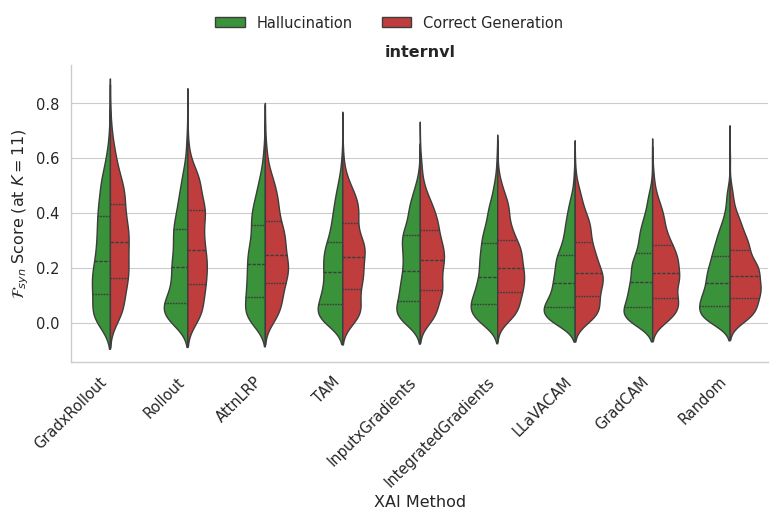

In [67]:
generate_stratification_plot(df, target_metric=target_metric,
                            savefig=False,
                            #output_file=
                            )

[*] Generating bar plot for 13131 total samples...


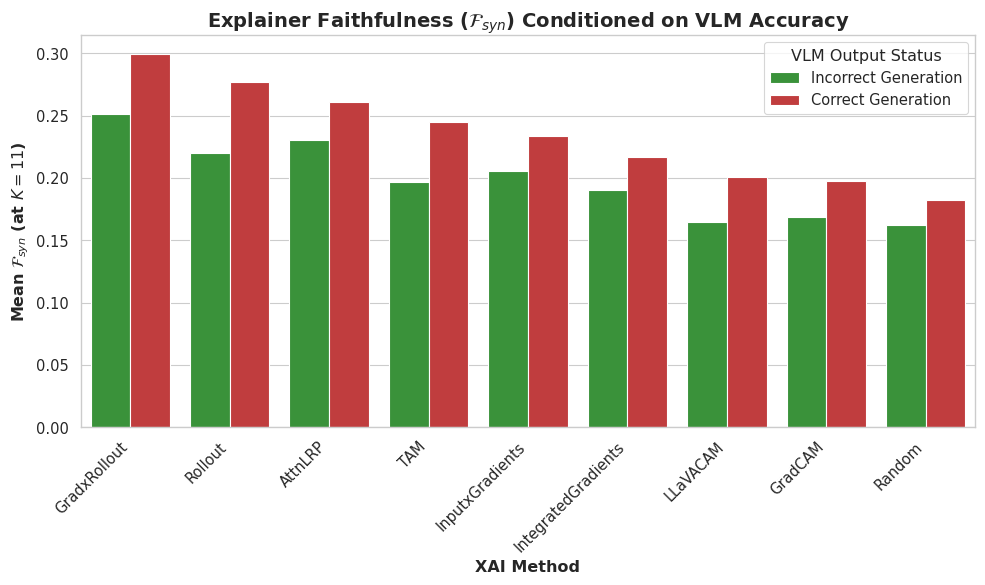

In [68]:
generate_stratification_barplot(df, target_metric=target_metric,
                            savefig=False,
                            #output_file=
                            )

#### Riemann steps sensitivity

In [23]:
df = load_all_benchmark_data(base_dir="../logs/sensitivity/",
                            #dataset_name="repope_all"
                            )

[*] Found 9 result files. Aggregating...


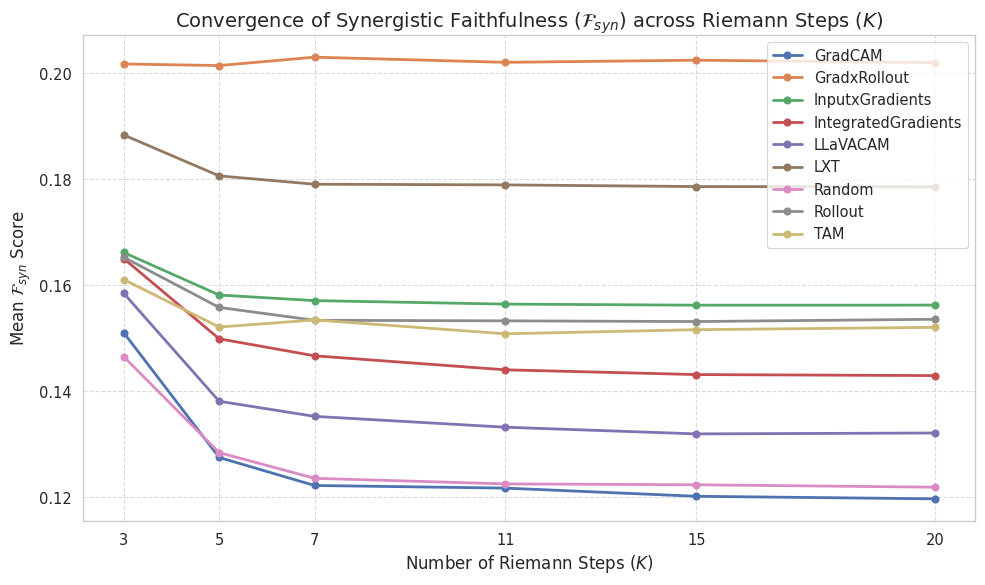

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kendalltau
import json

# Define the K values we tested
k_values = [3, 5, 7, 11, 15, 20]

# ==========================================
# ANALYSIS 1: Mean F_syn Convergence
# ==========================================
# Create a dataframe of just the mean F_syn scores per explainer
score_cols = {f"k{k}_syn_synergy_auc": k for k in k_values}
df_scores = df.groupby('explainer')[list(score_cols.keys())].mean()
df_scores.columns = k_values # Rename columns to just the K integer

plt.figure(figsize=(10, 6))
for explainer in df_scores.index:
    plt.plot(k_values, df_scores.loc[explainer], marker='o', label=explainer, linewidth=2)

plt.title(r'Convergence of Synergistic Faithfulness ($\mathcal{F}_{syn}$) across Riemann Steps ($K$)', fontsize=14)
plt.xlabel('Number of Riemann Steps ($K$)', fontsize=12)
plt.ylabel(r'Mean $\mathcal{F}_{syn}$ Score', fontsize=12)
plt.xticks(k_values)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
# plt.savefig('f_syn_convergence.pdf') # Save for NeurIPS
plt.show()

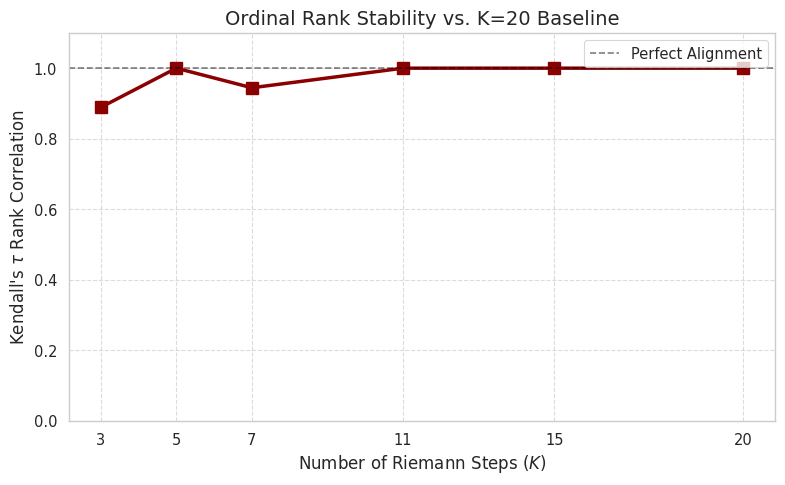

In [26]:
# ==========================================
# ANALYSIS 2: Rank Stability (Kendall's Tau)
# ==========================================
# Rank the explainers for each K (1 is best, 8 is worst)
# We rank descending because higher F_syn is better
df_ranks = df_scores.rank(ascending=False)

# Treat K=20 as the "Ground Truth" ranking
ground_truth_ranks = df_ranks[20]

tau_scores = []
for k in k_values:
    # Calculate Kendall's Tau between current K and K=20
    tau, p_value = kendalltau(df_ranks[k], ground_truth_ranks)
    tau_scores.append(tau)

plt.figure(figsize=(8, 5))
plt.plot(k_values, tau_scores, marker='s', color='darkred', linewidth=2.5, markersize=8)
plt.axhline(y=1.0, color='black', linestyle='--', alpha=0.5, label='Perfect Alignment')

plt.title('Ordinal Rank Stability vs. K=20 Baseline', fontsize=14)
plt.xlabel('Number of Riemann Steps ($K$)', fontsize=12)
plt.ylabel(r"Kendall's $\tau$ Rank Correlation", fontsize=12)
plt.xticks(k_values)
plt.ylim(0, 1.1)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
filename = os.path.join(SAVE_DIR, 'rank_stability_tau.pdf')
plt.savefig(filename)
plt.show()

In [9]:
tau_scores

[np.float64(0.8888888888888888),
 np.float64(1.0),
 np.float64(0.9444444444444445),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0)]

In [46]:
print(df_ranks)

                      3    5    7    11   15   20
explainer                                        
GradCAM              8.0  9.0  9.0  9.0  9.0  9.0
GradxRollout         1.0  1.0  1.0  1.0  1.0  1.0
InputxGradients      3.0  3.0  3.0  3.0  3.0  3.0
IntegratedGradients  5.0  6.0  6.0  6.0  6.0  6.0
LLaVACAM             7.0  7.0  7.0  7.0  7.0  7.0
LXT                  2.0  2.0  2.0  2.0  2.0  2.0
Random               9.0  8.0  8.0  8.0  8.0  8.0
Rollout              4.0  4.0  5.0  4.0  4.0  4.0
TAM                  6.0  5.0  4.0  5.0  5.0  5.0


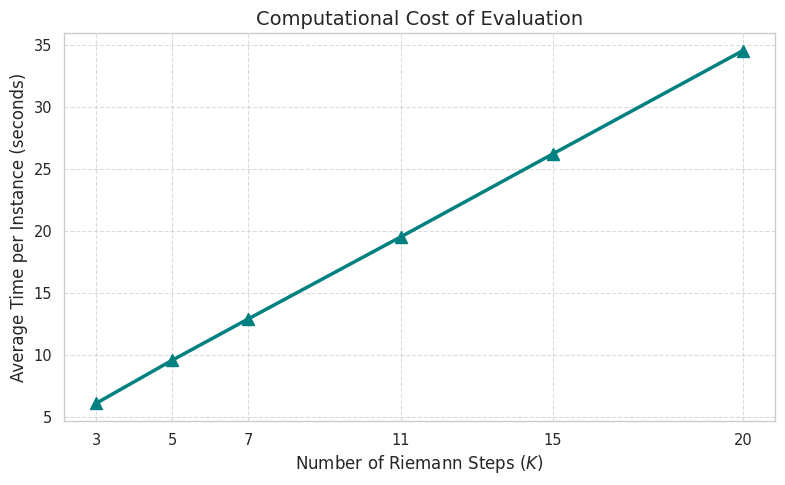

In [27]:
# ==========================================
# ANALYSIS 3: Computational Time Trade-off
# ==========================================
time_cols = {f"k{k}_time_syn_pert": k for k in k_values}
df_time = df[list(time_cols.keys())].mean()
df_time.index = k_values

plt.figure(figsize=(8, 5))
plt.plot(k_values, df_time.values, marker='^', color='teal', linewidth=2.5, markersize=8)

plt.title('Computational Cost of Evaluation', fontsize=14)
plt.xlabel('Number of Riemann Steps ($K$)', fontsize=12)
plt.ylabel('Average Time per Instance (seconds)', fontsize=12)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
filename = os.path.join(SAVE_DIR, 'compute_time_tradeoff.pdf')
plt.savefig(filename)
plt.show()

#### Limitations of metrics

In [137]:
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIGURATION ---
# Replace these with your actual column names for unimodal image and text metrics
IMG_METRIC = 'img_srg_norm'  
TOK_METRIC = 'tok_srg_norm'  

def compute_kendalls_tau(df, img_col, tok_col):
    print("=== Kendall's Tau: Image vs Text Ranking Instability ===")
    
    datasets = df['Dataset'].unique()
    results = []

    for ds in datasets:
        df_ds = df[df['Dataset'] == ds]
        
        # Get the mean score for each explainer on this dataset
        means = df_ds.groupby('Explainer')[[img_col, tok_col]].mean()
        
        # Rank them (higher score = rank 1, etc.)
        # Adjust ascending=False/True depending on if higher is better for your metric
        img_ranks = means[img_col].rank(ascending=False)
        tok_ranks = means[tok_col].rank(ascending=False)
        
        # Compute Kendall's Tau
        tau, p_value = stats.kendalltau(img_ranks, tok_ranks)
        
        results.append({'Dataset': ds, 'Kendalls_Tau': tau, 'p_value': p_value})
        print(f"- {ds}: Tau = {tau:.3f} (p={p_value:.3f})")

    # Overall Global Tau
    global_means = df.groupby('Explainer')[[img_col, tok_col]].mean()
    global_tau, global_p = stats.kendalltau(global_means[img_col].rank(ascending=False), 
                                            global_means[tok_col].rank(ascending=False))
    print(f"- GLOBAL (All Datasets): Tau = {global_tau:.3f} (p={global_p:.3f})")
    print("========================================================\n")
    
    return pd.DataFrame(results)

def plot_rank_shift_bump_chart(df, img_col, tok_col,
                                          savefig=False,
                                          format='pdf',
                                          save_path="rank_shift",
                                          ):
    # 1. Calculate global mean scores and rank them
    means = df.groupby('Explainer')[[img_col, tok_col]].mean()
    
    # rank() assigns lower numbers to lower values by default. 
    # We want the best explainer (highest score) to be Rank 1.
    means['Img_Rank'] = means[img_col].rank(ascending=False)
    means['Tok_Rank'] = means[tok_col].rank(ascending=False)
    
    # Sort by Image Rank for plotting order
    means = means.sort_values('Img_Rank')
    explainers = means.index.tolist()

    # 2. Setup the Plot for NeurIPS (Wide and short to save vertical space)
    fig, ax = plt.subplots(figsize=(10, 3.5), dpi=300)
    
    # Coordinates for the two horizontal axes
    y_img, y_tok = 1, 0

    # 3. Draw the lines and points
    colors = plt.cm.tab10(np.linspace(0, 1, len(explainers)))

    for i, explainer in enumerate(explainers):
        r_img = means.loc[explainer, 'Img_Rank']
        r_tok = means.loc[explainer, 'Tok_Rank']
        
        # Plot the line connecting the two ranks (X=rank, Y=modality)
        ax.plot([r_img, r_tok], [y_img, y_tok], marker='o', markersize=8, 
                linewidth=2.5, color=colors[i], label=explainer)
        
        # Add Explainer text labels above the top line and below the bottom line.
        # We rotate them 40 degrees so the names don't overlap horizontally.
        ax.text(r_img, y_img + 0.1, f"{explainer} ({int(r_img)})", 
                ha='left', va='bottom', rotation=20, fontsize=9, fontweight='bold', color=colors[i])
        
        ax.text(r_tok, y_tok - 0.1, f"({int(r_tok)}) {explainer}", 
                ha='right', va='top', rotation=20, fontsize=9, fontweight='bold', color=colors[i])

    # 4. Formatting the axes to look like a clean Slope Graph
    # Set X limits and invert so Rank 1 is on the far left
    ax.set_xlim(len(explainers) + 0.5, 0.5) 
    
    # Set Y limits to give the rotated text plenty of breathing room
    ax.set_ylim(-0.6, 1.6) 
    
    # Remove all borders/spines
    for spine in ax.spines.values():
        spine.set_visible(False)
        
    ax.set_xticks([]) # Remove default x-ticks
    ax.set_yticks([y_tok, y_img])
    
    # Add the labels to the Y-axis
    ax.set_yticklabels(['Unimodal\nText Metric', 'Unimodal\nImage Metric'], 
                       fontsize=10, fontweight='bold')
    
    # Draw horizontal lines to act as the axes
    ax.axhline(y=y_img, color='black', linewidth=1, alpha=0.5)
    ax.axhline(y=y_tok, color='black', linewidth=1, alpha=0.5)

    plt.title("Ranking Instability: Image vs. Text Perturbation", 
              fontsize=12, fontweight='bold', pad=30)
    
    plt.tight_layout()
    if savefig:
        full_save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(full_save_path, format=format, bbox_inches='tight')
        print(f"[*] Saved figure to {full_save_path}")
    plt.show()

def plot_dataset_wise_bump_charts(df, img_col, tok_col,
                                  format='pdf',
                                  savefig=False):

    datasets = df['Dataset'].unique()
    
    for ds in datasets:
        # 1. Filter for the specific dataset
        df_ds = df[df['Dataset'] == ds]
        
        # 2. Calculate mean scores and rank them for this dataset ONLY
        means = df_ds.groupby('Explainer')[[img_col, tok_col]].mean()
        
        # Rank them (highest score = Rank 1)
        means['Img_Rank'] = means[img_col].rank(ascending=False)
        means['Tok_Rank'] = means[tok_col].rank(ascending=False)
        
        # Sort by Image Rank for a clean top axis
        means = means.sort_values('Img_Rank')
        explainers = means.index.tolist()

        # 3. Setup the Plot for NeurIPS (Wide and short)
        fig, ax = plt.subplots(figsize=(10, 3.5), dpi=300)
        
        # Coordinates for the two horizontal axes
        y_img, y_tok = 1, 0
        colors = plt.cm.tab10(np.linspace(0, 1, len(explainers)))

        # 4. Draw lines and labels
        for i, explainer in enumerate(explainers):
            r_img = means.loc[explainer, 'Img_Rank']
            r_tok = means.loc[explainer, 'Tok_Rank']
            
            # Plot the line connecting the two ranks (X=rank, Y=modality)
            ax.plot([r_img, r_tok], [y_img, y_tok], marker='o', markersize=8, 
                    linewidth=2.5, color=colors[i], label=explainer)
            
            # Add Explainer text labels above the top line and below the bottom line.
            ax.text(r_img, y_img + 0.1, f"{explainer} ({int(r_img)})", 
                    ha='left', va='bottom', rotation=20, fontsize=9, fontweight='bold', color=colors[i])
            
            ax.text(r_tok, y_tok - 0.1, f"({int(r_tok)}) {explainer}", 
                    ha='right', va='top', rotation=20, fontsize=9, fontweight='bold', color=colors[i])

        # 5. Formatting the axes
        # Set X limits and invert so Rank 1 is on the far left
        ax.set_xlim(len(explainers) + 0.5, 0.5) 
        
        # Set Y limits to give the rotated text breathing room
        ax.set_ylim(-0.6, 1.6) 
        
        # Remove all borders/spines
        for spine in ax.spines.values():
            spine.set_visible(False)
            
        ax.set_xticks([]) # Remove default x-ticks
        ax.set_yticks([y_tok, y_img])
        
        ax.set_yticklabels(['Unimodal\nText Metric', 'Unimodal\nImage Metric'], 
                           fontsize=10, fontweight='bold')
        
        # Draw horizontal lines to act as the axes
        ax.axhline(y=y_img, color='black', linewidth=1, alpha=0.5)
        ax.axhline(y=y_tok, color='black', linewidth=1, alpha=0.5)

        # Title includes the dataset name
        plt.title(f"Ranking Instability on {ds}", fontsize=12, fontweight='bold', pad=30)
        
        plt.tight_layout()
        
        # Save dynamically named file
        if savefig:
            filename = f"rank_shift_{ds.lower()}.{format}"
            save_path = os.path.join(SAVE_DIR, filename)
            plt.savefig(save_path, format=format, bbox_inches='tight')
            print(f"[*] Saved: {save_path}")
        plt.show()

# Run it! (Replace with your actual column names)
# plot_dataset_wise_bump_charts(df, 'img_srg_norm', 'tok_srg_norm')

=== Kendall's Tau: Image vs Text Ranking Instability ===
- repope_all: Tau = 0.222 (p=0.477)
- cv_bench: Tau = 0.389 (p=0.180)
- mmstar: Tau = 0.500 (p=0.075)
- GLOBAL (All Datasets): Tau = 0.167 (p=0.612)

[*] Saved figure to ../figs/rank_shift.pdf


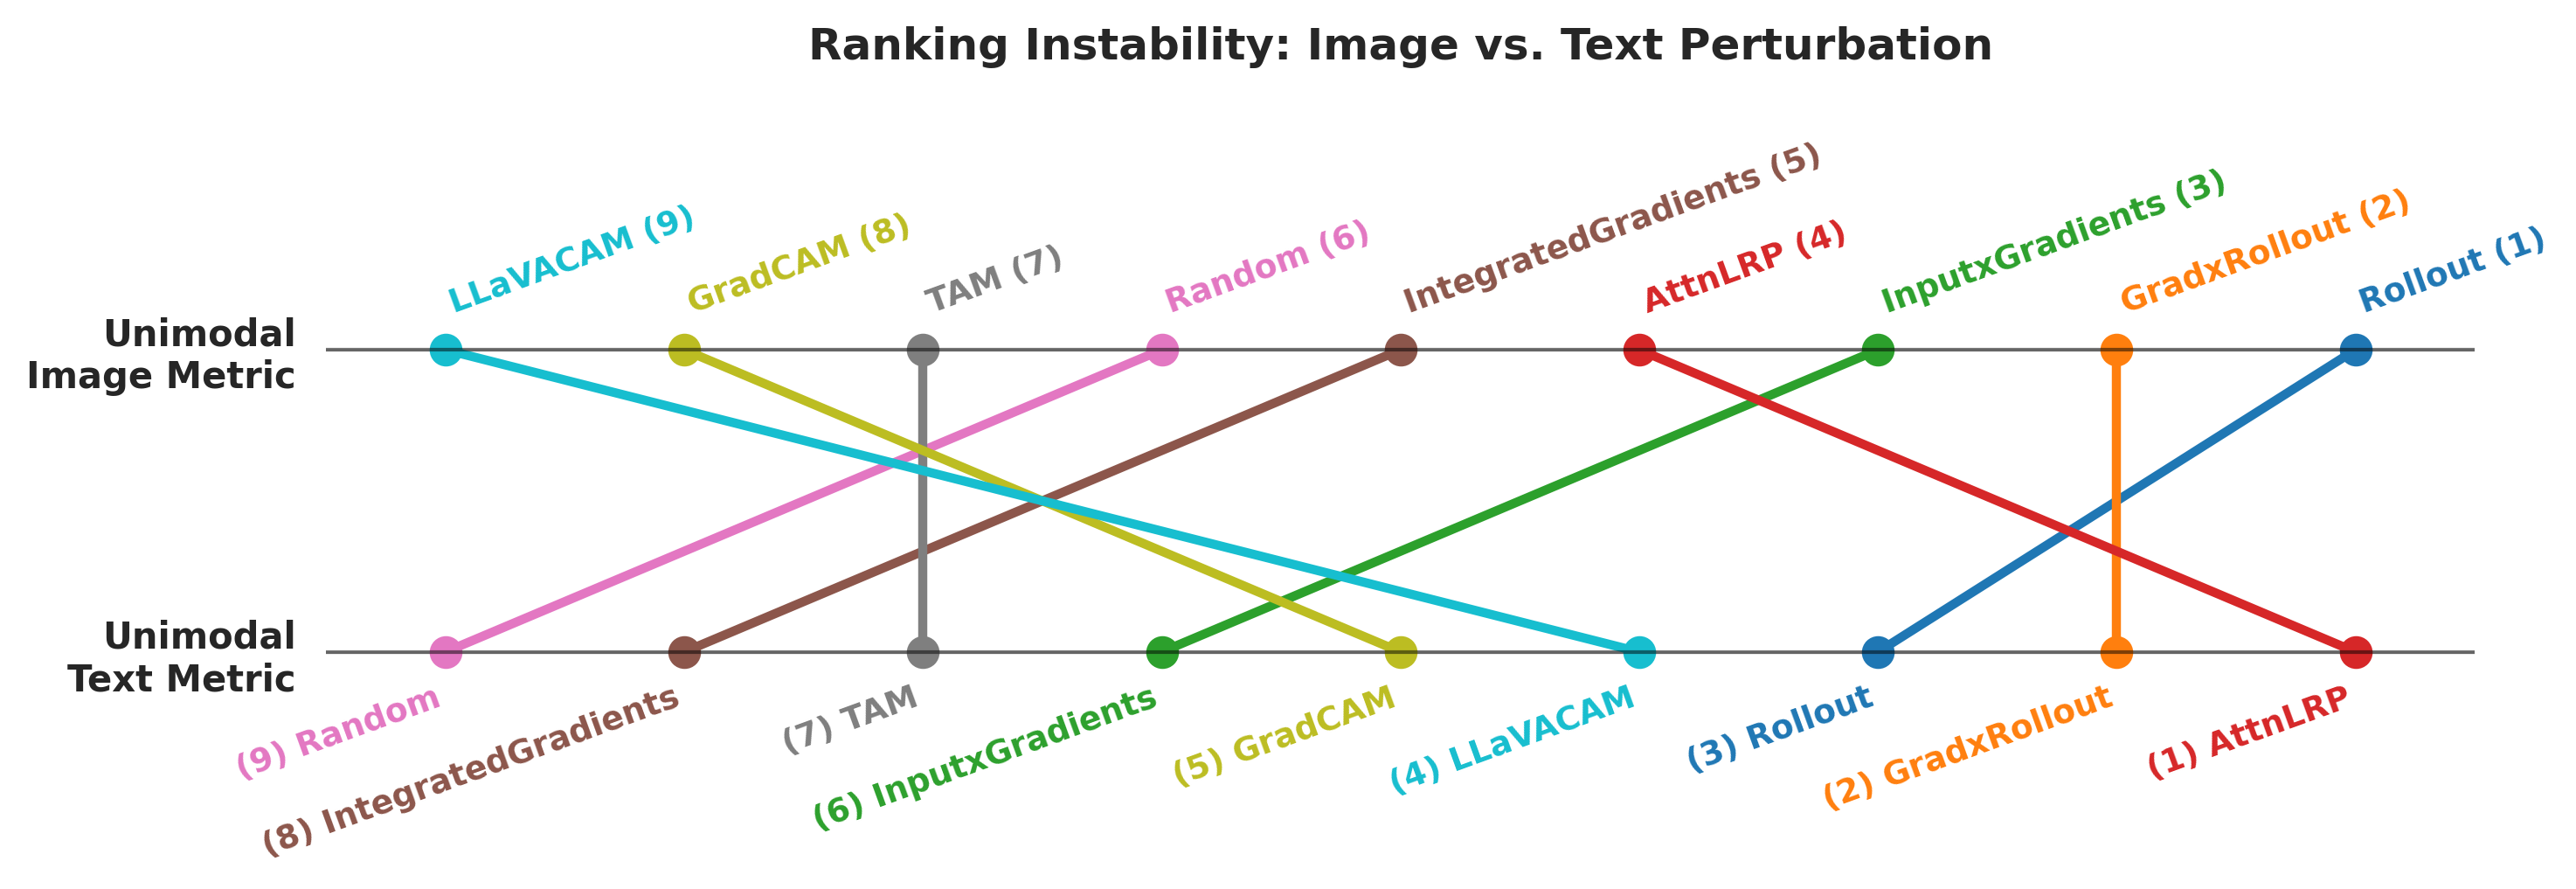

In [138]:
metric = "srg_norm"
IMG_METRIC = f'img_{metric}'
# TOK_METRIC = f''tok_{metric}''
TOK_METRIC = f'tok_{metric}'

# Run the function
tau_df = compute_kendalls_tau(df, IMG_METRIC, TOK_METRIC)
# Run the plotting function
plot_rank_shift_bump_chart(df, IMG_METRIC, TOK_METRIC, savefig=True)



[*] Saved: ../figs/rank_shift_repope_all.pdf


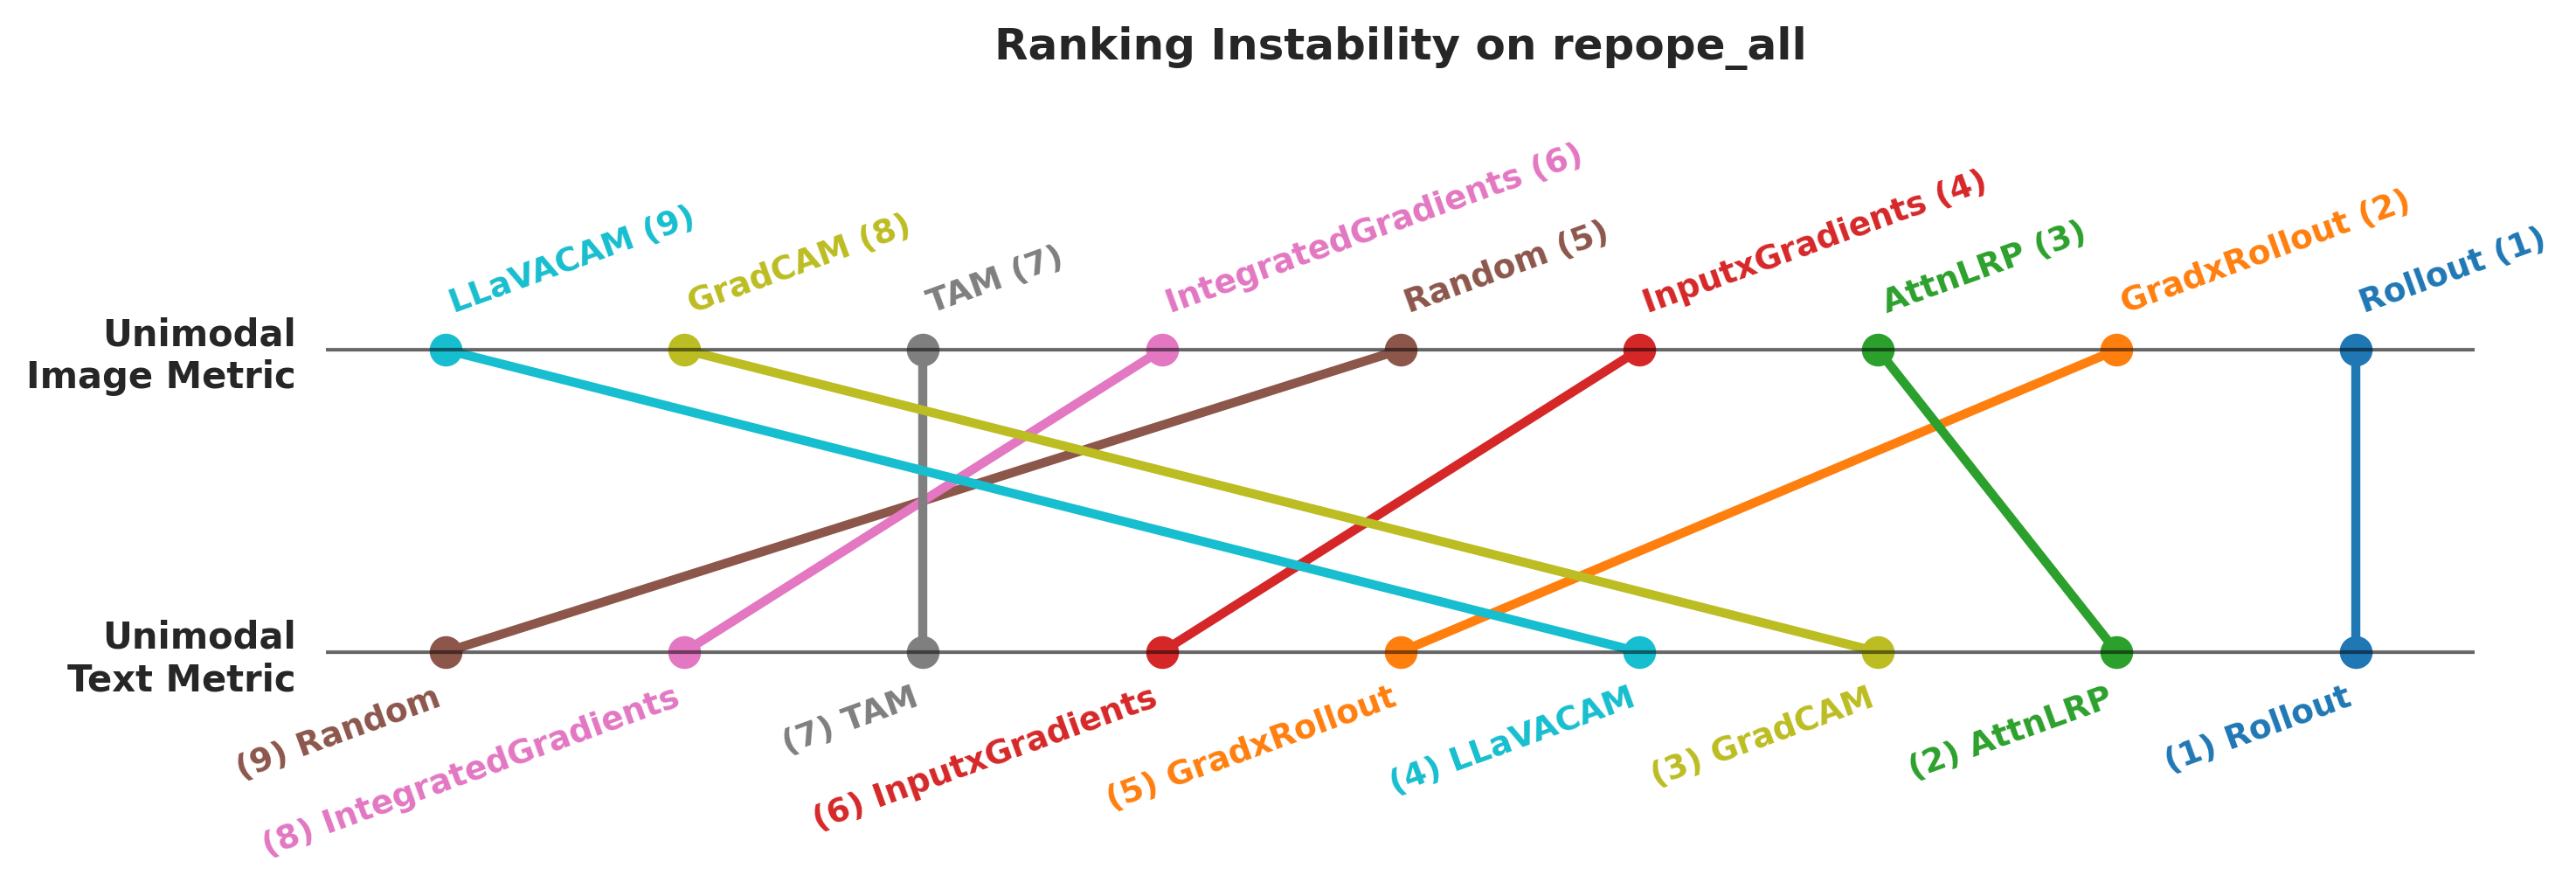

[*] Saved: ../figs/rank_shift_cv_bench.pdf


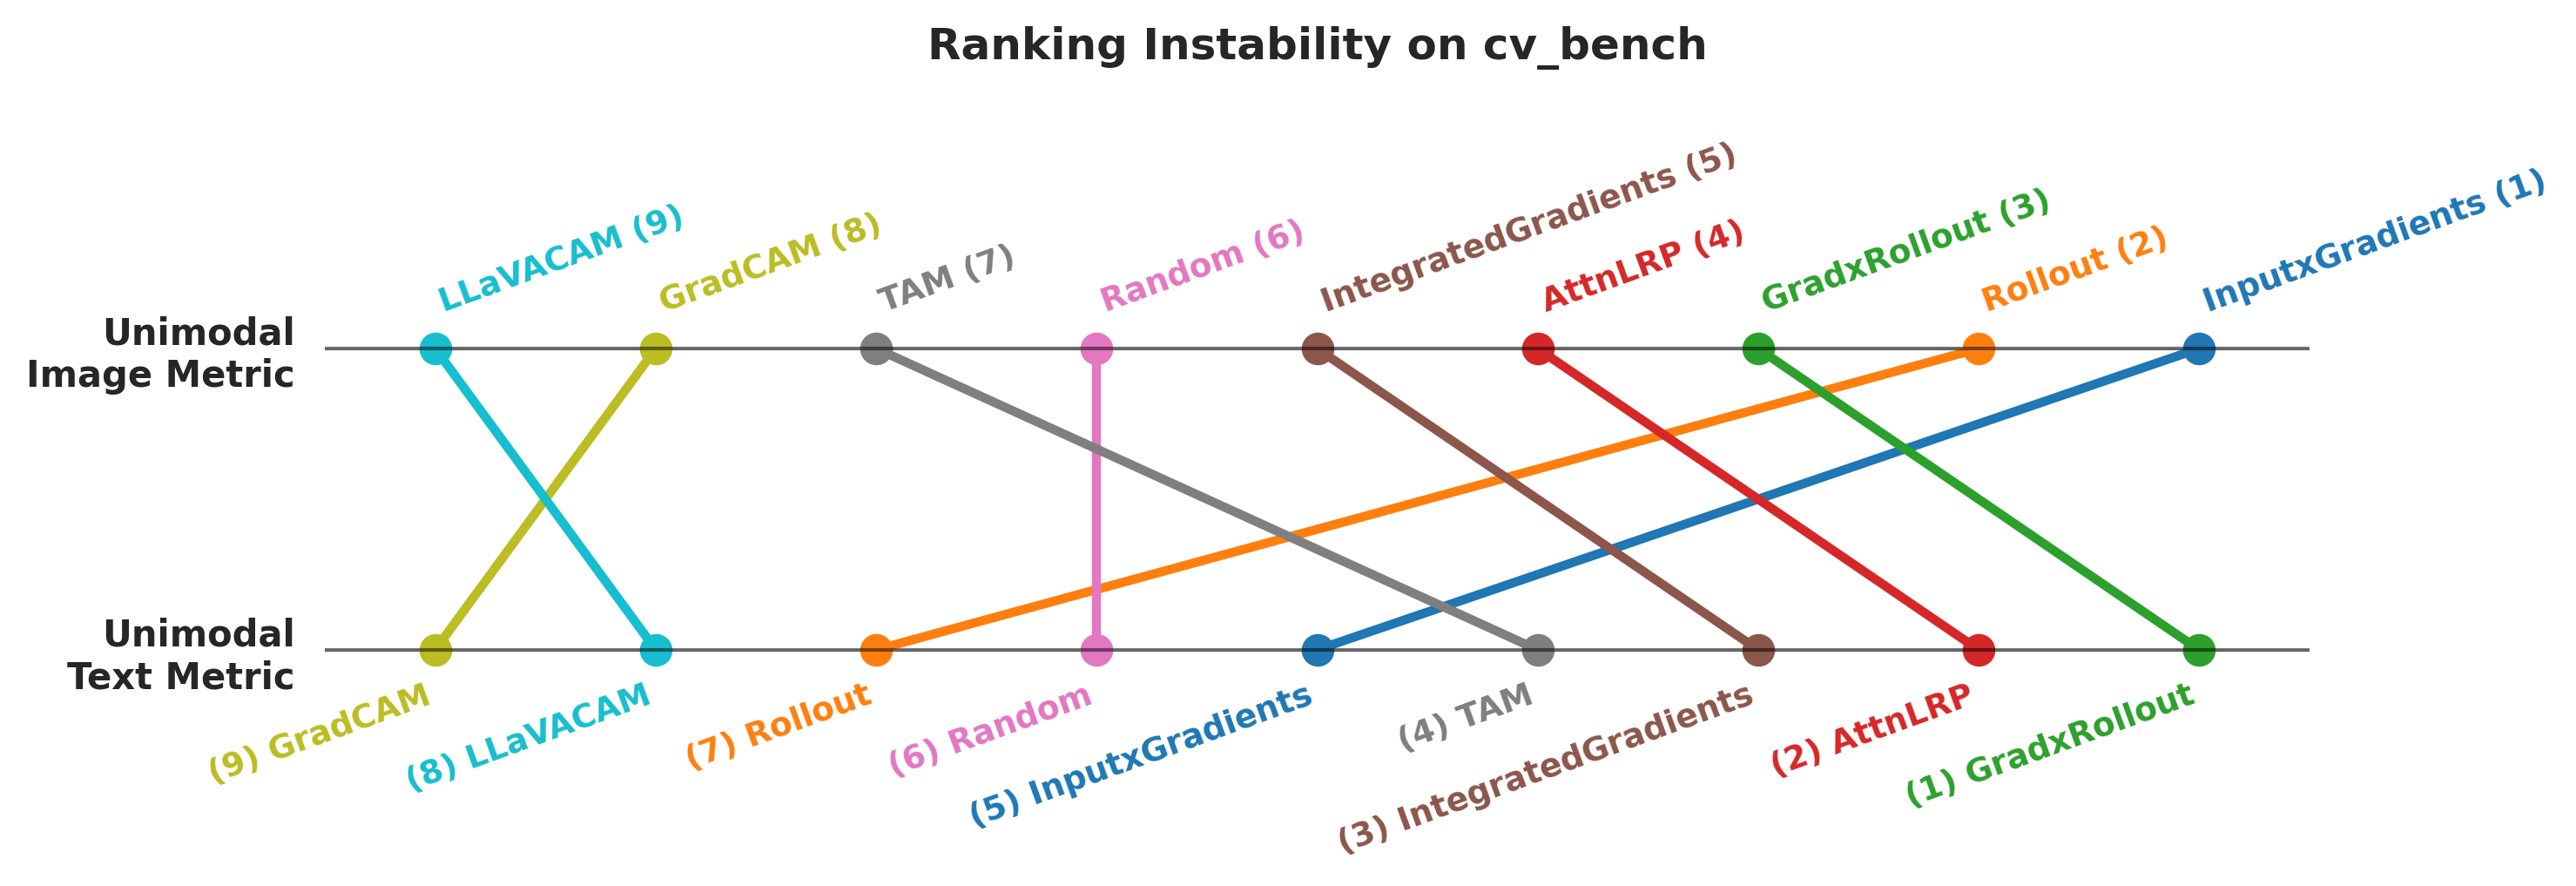

[*] Saved: ../figs/rank_shift_mmstar.pdf


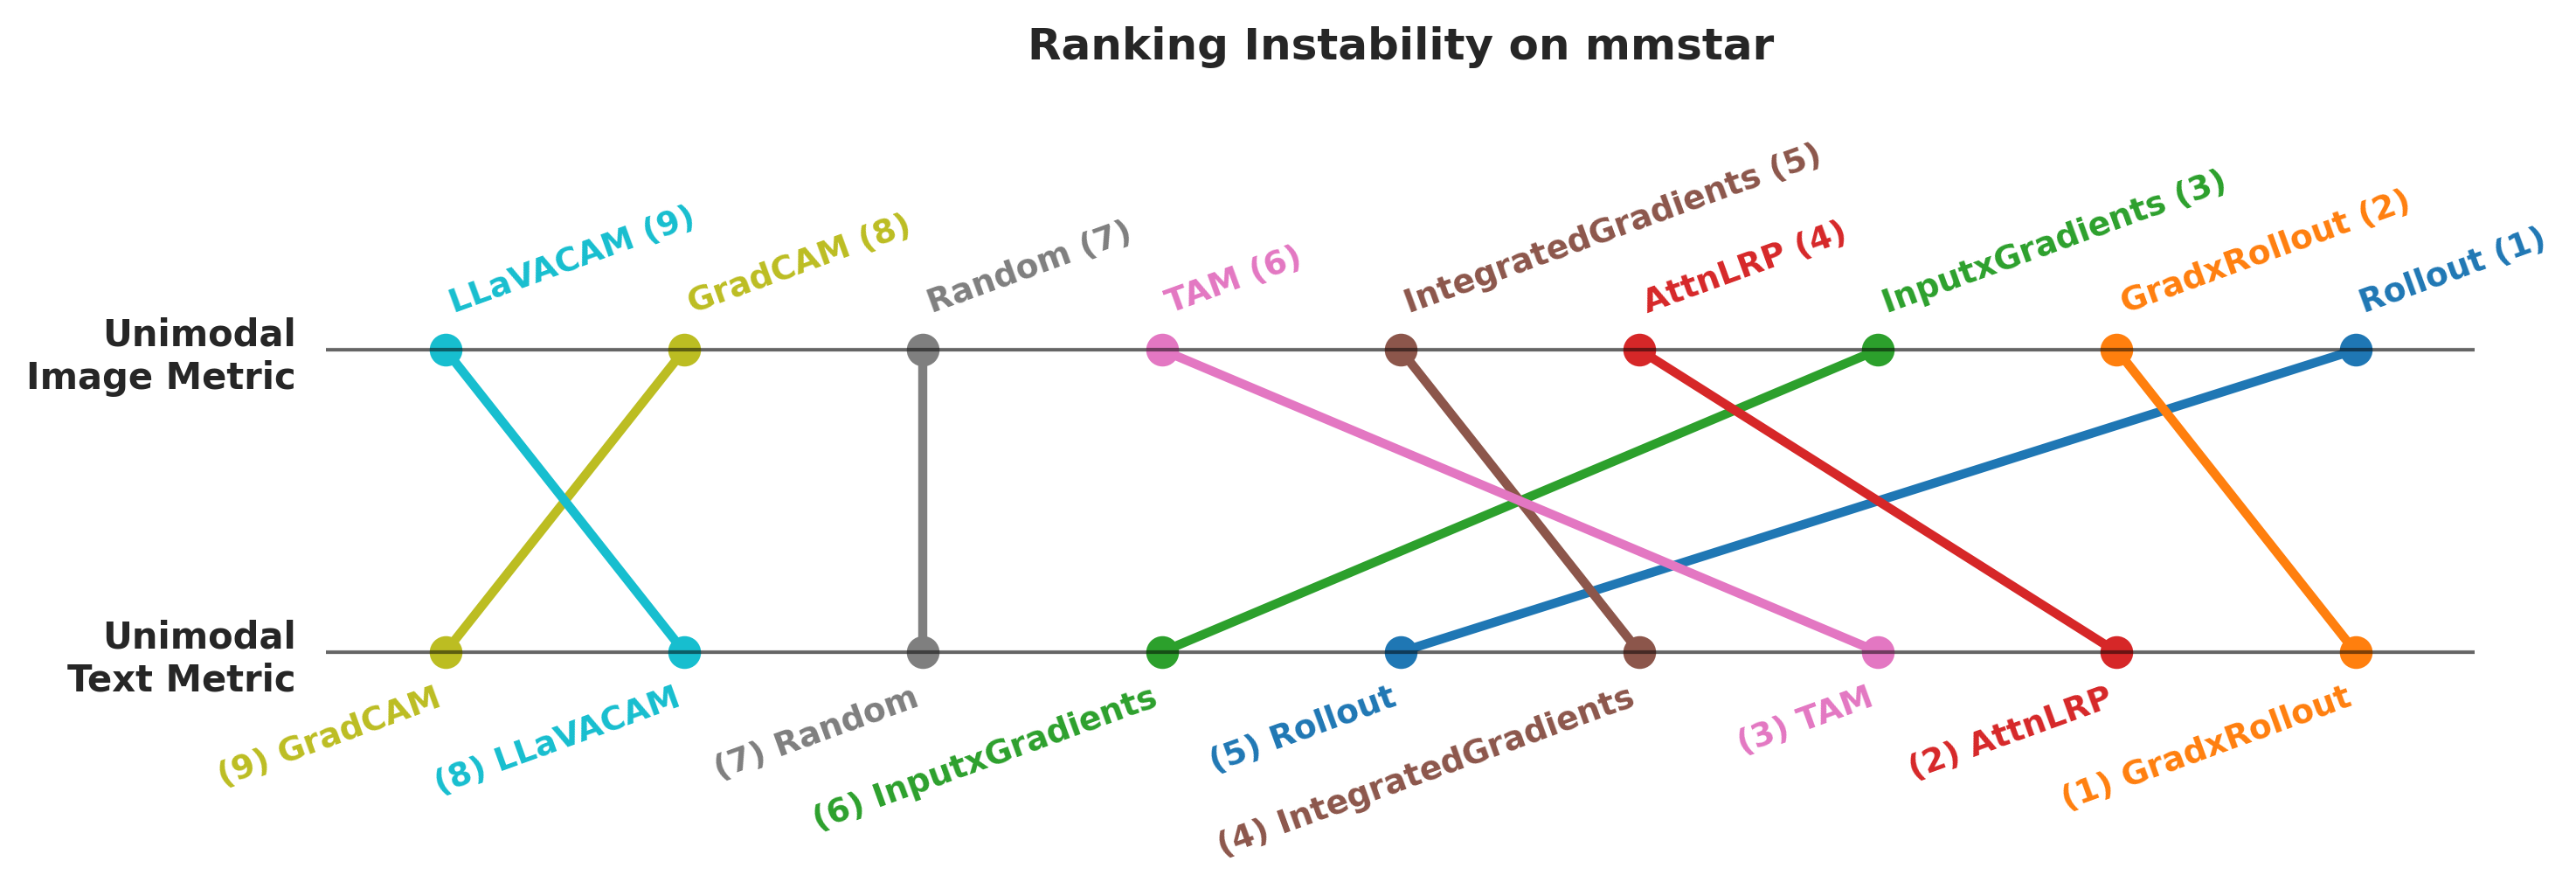

In [139]:
plot_dataset_wise_bump_charts(df, IMG_METRIC, TOK_METRIC, savefig=True)

#### Larger VLMs

In [49]:
df_large = load_all_benchmark_data(base_dir="../logs/results_large_models/",
                            #dataset_name="repope_all"
                            )



[*] Found 45 result files. Aggregating...


##### LMMs plots

In [52]:
def generate_forest_plot(summary_df=None,
                        savefig=False, format='pdf',
                        summary_csv_path="../logs/lmm_whole.csv",
                        save_path="lmm_forest_plot"
                                  ):
    print("--- Generating Upgraded LMM Forest Plot ---")
    
    # 1. Load and clean the dataframe
    if summary_df is None:
        summary_df = pd.read_csv(summary_csv_path, index_col=0)

    explainer_df = summary_df[summary_df.index.str.contains(r"C\(Explainer\)\[T\.")].copy()

    # Clean up the index names
    explainer_df.index = explainer_df.index.str.replace("C(Explainer)[T.", "", regex=False).str.replace("]", "", regex=False)

    # Sort the explainers by coefficient value
    explainer_df = explainer_df.sort_values('coef', ascending=True)

    # 2. Setup the Plot for a clean, modern look
    sns.set_theme(style="white", context="paper", font_scale=1.2)
    fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

    y_ticks = np.arange(len(explainer_df))
    xerr_lower = explainer_df['coef'] - explainer_df['lower_ci']
    xerr_upper = explainer_df['upper_ci'] - explainer_df['coef']

    # 3. Add Zebra Striping for readability
    for idx in range(len(y_ticks)):
        if idx % 2 == 0:
            ax.axhspan(idx - 0.5, idx + 0.5, color='#f8f9fa', zorder=0)

    # 4. Generate a dynamic color palette based on the coefficients
    norm = plt.Normalize(explainer_df['coef'].min(), explainer_df['coef'].max())
    cmap = sns.color_palette("crest", as_cmap=True) # A sleek teal/blue scientific gradient
    colors = cmap(norm(explainer_df['coef']))

    # 5. Plot the points, error bars, and exact value labels
    for i, (idx, row) in enumerate(explainer_df.iterrows()):
        # Draw the error bar
        ax.errorbar(x=row['coef'], y=i,
                    xerr=[[xerr_lower.iloc[i]], [xerr_upper.iloc[i]]],
                    fmt='none', ecolor=colors[i], elinewidth=2.5, capsize=5, capthick=2, 
                    zorder=2, alpha=0.7)
        
        # Draw the main marker point (larger, with a white border for pop)
        ax.plot(row['coef'], i, marker='o', markersize=12, color=colors[i],
                markeredgecolor='white', markeredgewidth=1.5, zorder=3)

        # Annotate the exact Beta value just to the right of the error bar
        ax.text(row['coef'] + xerr_upper.iloc[i] + 0.0015, i,
                f"+{row['coef']:.3f}", va='center', ha='left',
                fontsize=10, fontweight='bold', color=colors[i])

    # 6. Add the Random Baseline (Zero Line)
    ax.axvline(x=0, color='#e74c3c', linestyle='--', linewidth=2, zorder=1)
    
    # Inline annotation for the baseline instead of a legend
    ax.text(0.0005, 0.05, "Random Baseline", color='#e74c3c', rotation=90,
            va='bottom', ha='left', fontsize=11, fontweight='bold', alpha=0.8,
            transform=ax.get_xaxis_transform())

    # 7. Formatting the axes and labels
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(explainer_df.index, fontweight='bold')
    ax.set_xlabel(r'LMM fixed Effect ($\beta$) vs. Random explainer baseline', fontweight='bold', labelpad=10)
    ax.set_title('Explainer faithfulness: LMM fixed effects', fontweight='bold', pad=20, fontsize=14)

    # Clean up spines and add an x-axis grid
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False) # Remove left spine so zebra stripes sit flush with labels
    ax.grid(axis='x', linestyle=':', alpha=0.6, zorder=0)

    # Dynamically stretch the x-axis limit so our new text labels aren't cut off
    max_val = explainer_df['upper_ci'].max()
    ax.set_xlim(-0.002, max_val + 0.006) 

    plt.tight_layout()

    if savefig:
        full_save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(full_save_path, format=format, bbox_inches='tight')
        print(f"[*] Saved stunning figure to {full_save_path}")
        
    plt.show()


--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_big_llms_forest_plot.pdf


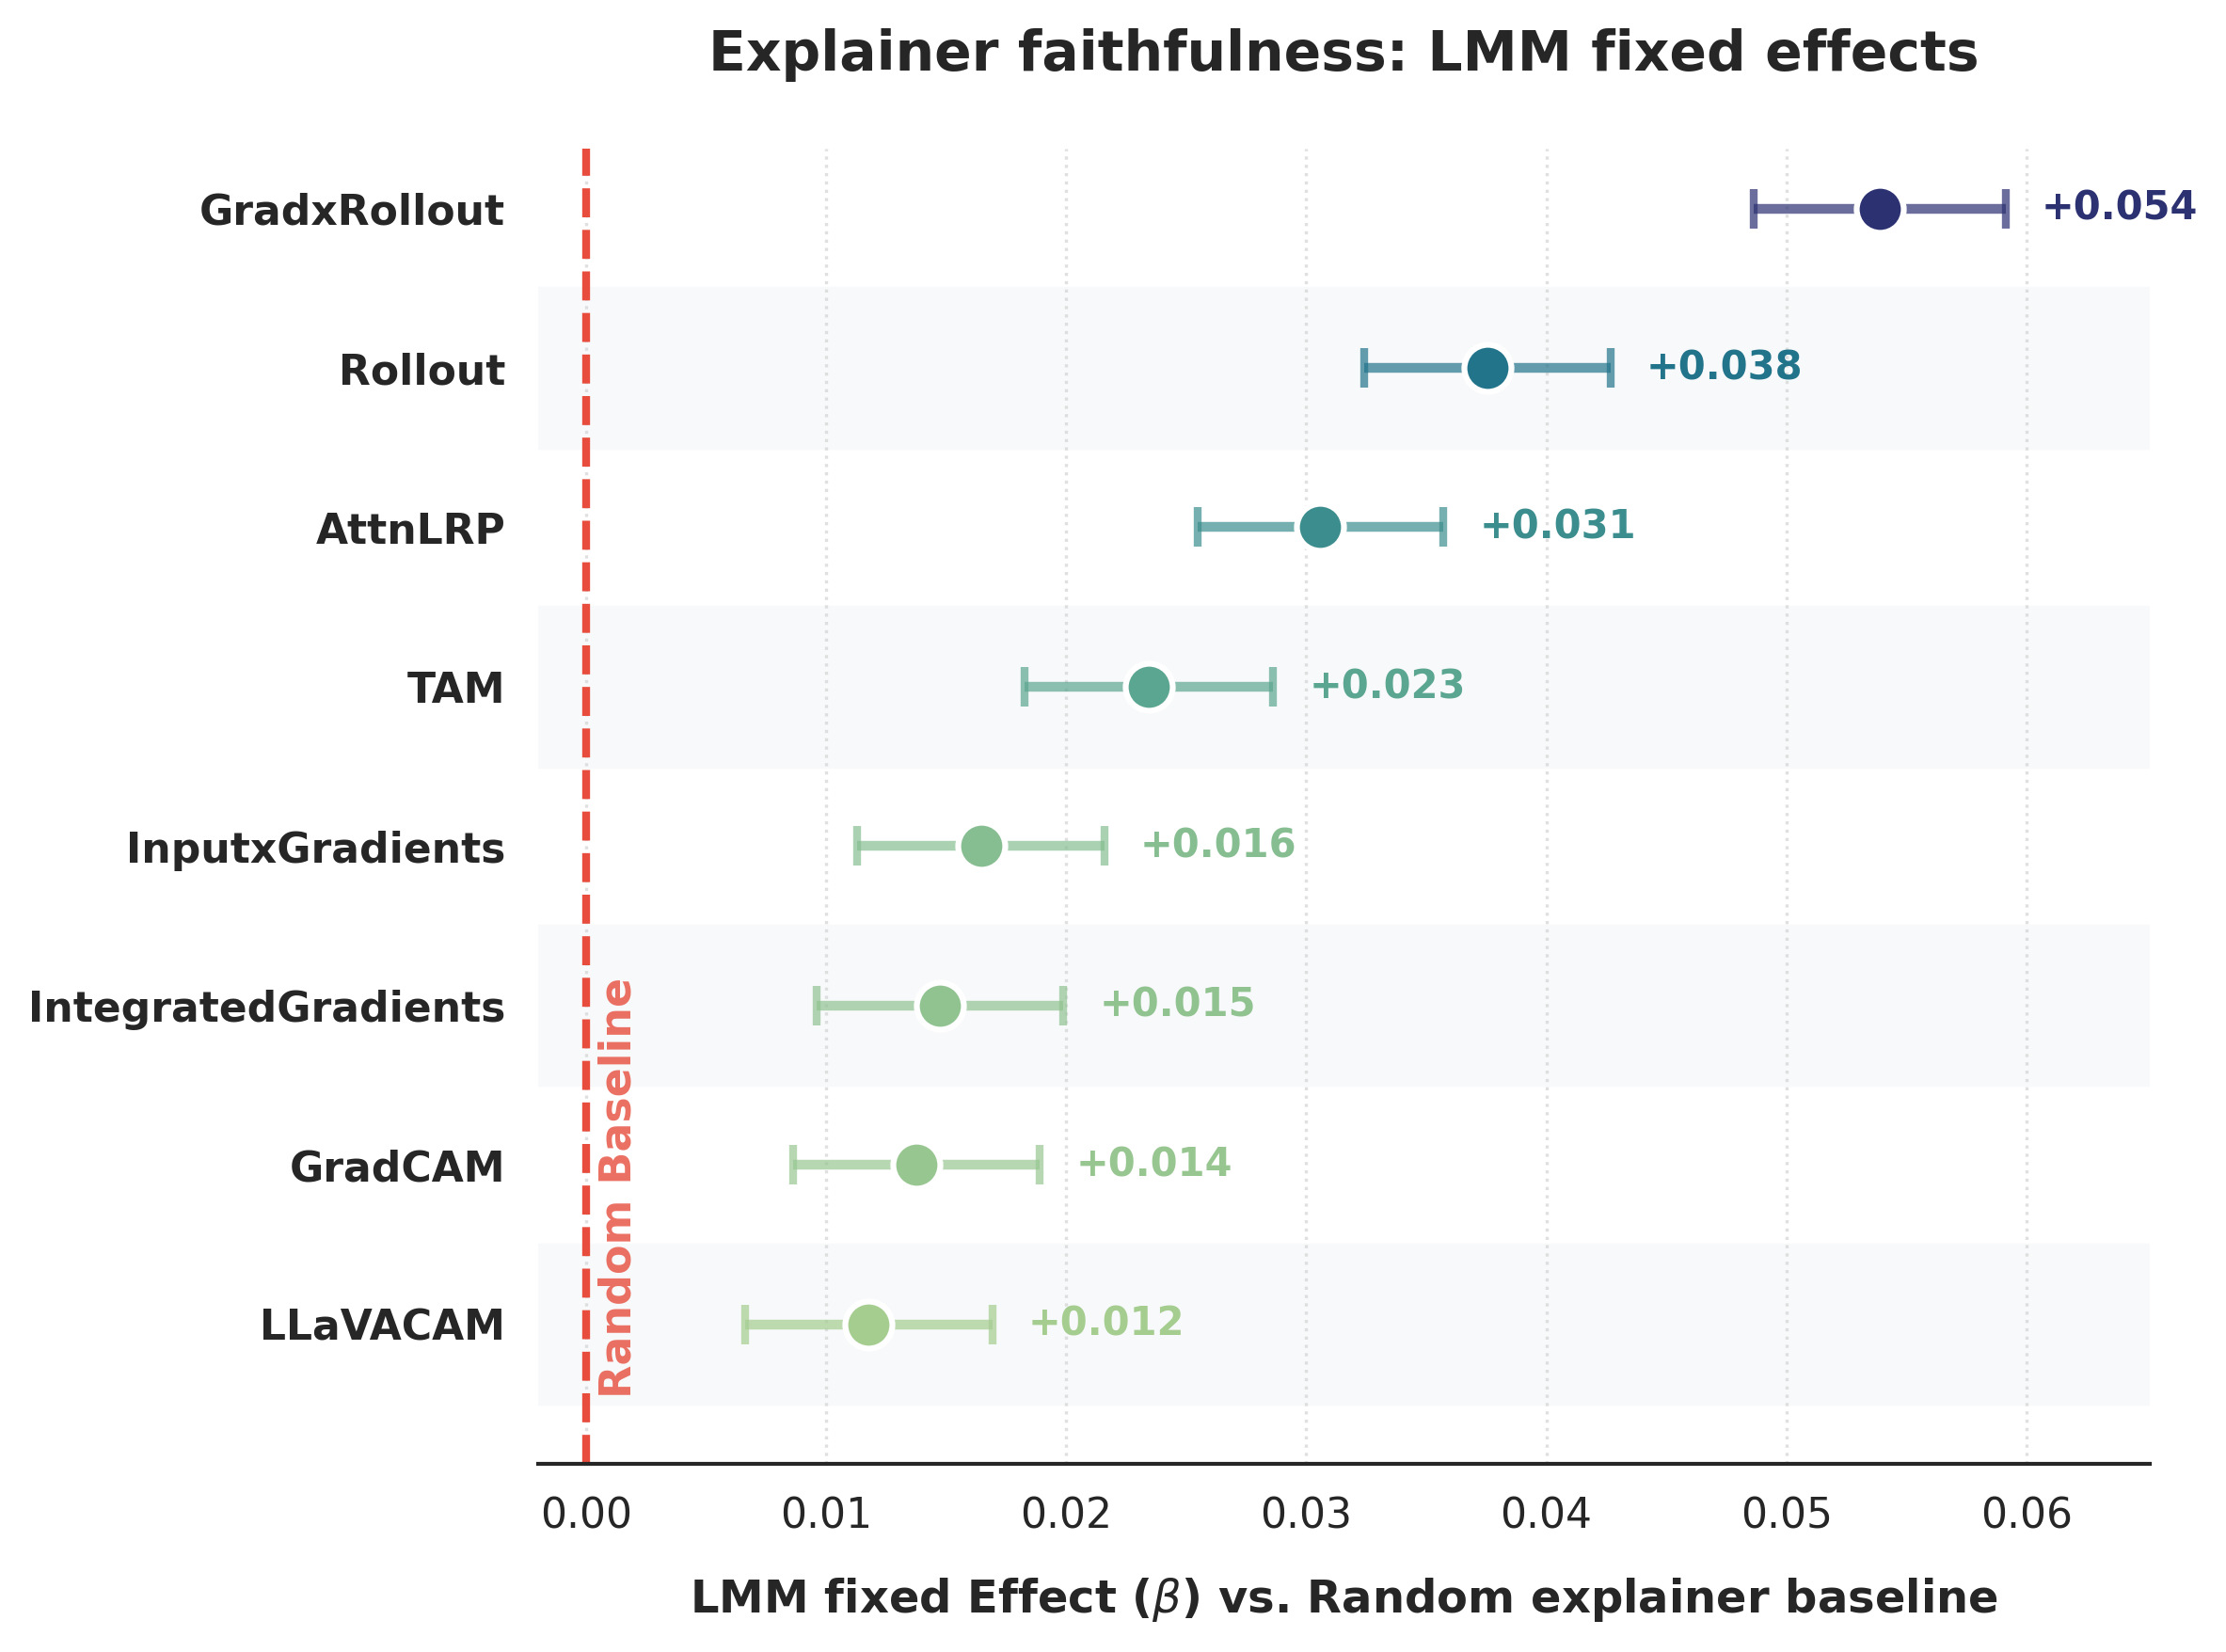

In [60]:
generate_forest_plot(summary_df=None,
                    savefig=True, format='pdf',
                    summary_csv_path="../logs/lmms/lmm_mmstar_big.csv",
                    save_path="lmm_big_llms_forest_plot"
                    )

In [57]:
import pandas as pd
import numpy as np

def format_pvalue(p):
    """Formats the p-value with LaTeX significance stars."""
    if pd.isna(p):
        return "---"
    if p < 0.001:
        return r"$<0.001^{***}$"
    elif p < 0.01:
        return f"${p:.3f}^{{**}}$"
    elif p < 0.05:
        return f"${p:.3f}^{{*}}$"
    else:
        return f"${p:.3f}$"

def generate_latex_lmm_table(mmstar_path):
    """Reads the LMM CSVs and generates the complete LaTeX table."""
    
    # 1. Load the dataframes and set the Explainer column as index
    df_mmstar = pd.read_csv(mmstar_path).set_index('Explainer')


    # Add suffixes to differentiate the columns during concatenation
    df_mmstar.columns = [f"{c}_mms" for c in df_mmstar.columns]

    # Combine them into one master dataframe
    df_merged = pd.concat([df_mmstar], axis=1)

    # 2. Define the exact grouping and LaTeX-formatted names
    # Dictionary mapping: { "Name in CSV" : "Beautiful LaTeX Name" }
    explainer_groups = [
        # Group 1: Attention-based
        {
            'AttnLRP': 'AttnLRP',
            'GradxRollout': r'Grad$\times$Rollout',
            'Rollout': 'Rollout'
        },
        # Group 2: VLM-native
        {
            'TAM': 'TAM',
            'LLaVACAM': 'LLaVA-CAM'
        },
        # Group 3: Classical
        {
            'GradCAM': 'GradCAM',
            'InputxGradients': r'Input$\times$Grad',
            'IntegratedGradients': 'Integ. Gradients'
        }
    ]

    # 3. Build the LaTeX String
    latex_str = r"""\begin{table}[h]
\centering
\caption{Dataset-Specific LMM Statistics for $\mathcal{F}_{syn}$. All values are calculated relative to the Random Attribution baseline. Significance thresholds: $^* p < 0.05$, $^{**} p < 0.01$, $^{***} p < 0.001$.}
\label{tab:lmm_pvalues}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l | r r r | r r r | r r r}
\toprule
\textbf{} & \multicolumn{3}{c|}{\textbf{RePOPE}} & \multicolumn{3}{c|}{\textbf{CVBench}} & \multicolumn{3}{c}{\textbf{MMStar}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
\textbf{Explainer} & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value \\
\midrule
"""

    # 4. Iterate through groups and build rows
    for i, group in enumerate(explainer_groups):
        for raw_name, latex_name in group.items():
            # If the explainer isn't in the dataframe, skip it gracefully
            if raw_name not in df_merged.index:
                continue
            
            row = df_merged.loc[raw_name]
            
            
            # Format MMStar
            mms_coef = f"{row['coef_mms']:.3f}"
            mms_se   = f"{row['se_mms']:.3f}"
            mms_p    = format_pvalue(row['pvalue_mms'])
            
            # Add the row to the table
            latex_str += f"{latex_name} & {mms_coef} & {mms_se} & {mms_p} \\\\\n"
        
        # Add a midrule after each group (except the last one)
        if i < len(explainer_groups) - 1:
            latex_str += "\\midrule\n"

    # 5. Finish the table
    latex_str += r"""\bottomrule
\end{tabular}%
}
\end{table}"""

    return latex_str



In [59]:
final_latex = generate_latex_lmm_table(mmstar_path="../logs/lmms/lmm_mmstar_big.csv")
print(final_latex)

\begin{table}[h]
\centering
\caption{Dataset-Specific LMM Statistics for $\mathcal{F}_{syn}$. All values are calculated relative to the Random Attribution baseline. Significance thresholds: $^* p < 0.05$, $^{**} p < 0.01$, $^{***} p < 0.001$.}
\label{tab:lmm_pvalues}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l | r r r | r r r | r r r}
\toprule
\textbf{} & \multicolumn{3}{c|}{\textbf{RePOPE}} & \multicolumn{3}{c|}{\textbf{CVBench}} & \multicolumn{3}{c}{\textbf{MMStar}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
\textbf{Explainer} & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value \\
\midrule
AttnLRP & 0.031 & 0.003 & $<0.001^{***}$ \\
Grad$\times$Rollout & 0.054 & 0.003 & $<0.001^{***}$ \\
Rollout & 0.038 & 0.003 & $<0.001^{***}$ \\
\midrule
TAM & 0.023 & 0.003 & $<0.001^{***}$ \\
LLaVA-CAM & 0.012 & 0.003 & $<0.001^{***}$ \\
\midrule
GradCAM & 0.014 & 0.003 & $<0.001^{***}$ \\
Input$\times$Grad & 0.016 & 0.003 & $<0.001^{

##### Generate result table

In [50]:
import pandas as pd
import numpy as np

def generate_latex_table_with_overall(df, metric='syn_synergy_norm_auc', columns='Model'):
    """
    Generates a Pandas Pivot Table with Mean ± Std, a true Overall column, 
    and exports the LaTeX code.
    """
    print(f"\n--- Generating LaTeX Table for {metric} (Mean ± Std) with OVERALL ---")
    
    # 1. Calculate Mean and Std for the individual columns (e.g., per Model)
    mean_df = df.pivot_table(index='Explainer', columns=columns, values=metric, aggfunc='mean')
    std_df = df.pivot_table(index='Explainer', columns=columns, values=metric, aggfunc='std')
    
    # 2. Calculate the TRUE Overall Mean and Std directly from the raw dataframe
    # This prevents the "averaging averages" math error.
    overall_mean = df.groupby('Explainer')[metric].mean()
    overall_std = df.groupby('Explainer')[metric].std()
    
    # Sort explainers from best to worst based on the true overall mean
    overall_mean = overall_mean.sort_values(ascending=False)
    
    # Align all dataframes to the newly sorted index
    mean_df = mean_df.reindex(overall_mean.index)
    std_df = std_df.reindex(overall_mean.index)
    overall_std = overall_std.reindex(overall_mean.index)
    
    # 3. Combine them into formatted strings: "Mean $\pm$ Std"
    combined_df = mean_df.copy()
    for col in mean_df.columns:
        combined_df[col] = mean_df[col].apply(lambda x: f"{x:.3f}") + r"$_{(\pm" + std_df[col].apply(lambda x: f"{x:.2f}") + ")}$"
    
    # 4. Add the formatted Overall column
    combined_df['Overall'] = overall_mean.apply(lambda x: f"{x:.3f}") + r"$_{(\pm" + overall_std.apply(lambda x: f"{x:.2f}") + ")}$"
    
    # 5. Export to LaTeX
    # escape=False prevents Pandas from breaking our LaTeX math formatting
    latex_code = combined_df.to_latex(escape=False)
    
    print(latex_code)
    return combined_df

# Run it!
# table_df = generate_latex_table_with_overall(df, metric='syn_synergy_norm_auc', columns='Model')

In [51]:
pivot = generate_latex_table_with_overall(df_large, metric='syn_synergy_norm_auc')


--- Generating LaTeX Table for syn_synergy_norm_auc (Mean ± Std) with OVERALL ---
\begin{tabular}{lllll}
\toprule
Model & internvl_14b & llava_13b & qwen3_5_27b & Overall \\
Explainer &  &  &  &  \\
\midrule
GradxRollout & 0.282$_{(\pm0.18)}$ & 0.107$_{(\pm0.13)}$ & 0.270$_{(\pm0.17)}$ & 0.204$_{(\pm0.18)}$ \\
Rollout & 0.227$_{(\pm0.16)}$ & 0.100$_{(\pm0.12)}$ & 0.260$_{(\pm0.17)}$ & 0.178$_{(\pm0.16)}$ \\
AttnLRP & 0.231$_{(\pm0.18)}$ & 0.097$_{(\pm0.12)}$ & 0.232$_{(\pm0.16)}$ & 0.174$_{(\pm0.17)}$ \\
TAM & 0.200$_{(\pm0.15)}$ & 0.084$_{(\pm0.11)}$ & 0.253$_{(\pm0.16)}$ & 0.161$_{(\pm0.15)}$ \\
InputxGradients & 0.208$_{(\pm0.15)}$ & 0.086$_{(\pm0.11)}$ & 0.221$_{(\pm0.15)}$ & 0.158$_{(\pm0.15)}$ \\
IntegratedGradients & 0.197$_{(\pm0.15)}$ & 0.085$_{(\pm0.10)}$ & 0.226$_{(\pm0.15)}$ & 0.153$_{(\pm0.14)}$ \\
LLaVACAM & 0.200$_{(\pm0.15)}$ & 0.076$_{(\pm0.10)}$ & 0.230$_{(\pm0.15)}$ & 0.152$_{(\pm0.15)}$ \\
GradCAM & 0.193$_{(\pm0.15)}$ & 0.077$_{(\pm0.10)}$ & 0.243$_{(\pm0.16)}$ & 

#### Benchmark results

In [5]:
df = load_all_benchmark_data(base_dir="../logs/results/",
                            #dataset_name="repope_all"
                            )

[*] Found 108 result files. Aggregating...


In [6]:
# plaus_cols = ["time_plausibility", "plaus_obj_iou", "plaus_point_game", "plaus_energy_score",
#               "note", "category", "parse_success", "decision_token_idx", "decision_token_str", "image_id", "text"]

# df = df.drop(labels=plaus_cols, axis=1, errors="ignore")

col_to_keep = ["sample_idx", "question", "Explainer", "xai_gen_time", 'label',
               "syn_synergy_auc", "syn_synergy_norm_auc",
                'syn_del_norm_auc', 'syn_ins_norm_auc', 'syn_del_auc', 'syn_ins_auc',
               "Model", "Dataset", 'tok_srg_norm', 'tok_srg', 'img_srg_norm', 'img_srg',
               'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
               'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del', 'tok_auc_ins',
               'prediction'
               ]
df = df[col_to_keep]


In [7]:
df.columns

Index(['sample_idx', 'question', 'Explainer', 'xai_gen_time', 'label',
       'syn_synergy_auc', 'syn_synergy_norm_auc', 'syn_del_norm_auc',
       'syn_ins_norm_auc', 'syn_del_auc', 'syn_ins_auc', 'Model', 'Dataset',
       'tok_srg_norm', 'tok_srg', 'img_srg_norm', 'img_srg',
       'img_norm_auc_del', 'img_norm_auc_ins', 'img_auc_del', 'img_auc_ins',
       'tok_norm_auc_del', 'tok_norm_auc_ins', 'tok_auc_del', 'tok_auc_ins',
       'prediction'],
      dtype='object')

##### LMM Plots

In [11]:
import pandas as pd
import statsmodels.formula.api as smf
import os

def compute_and_save_lmm(
    df: pd.DataFrame,
    output_path: str,
    target_datasets: list = None,
    baseline_explainer: str = 'Random',
    score_col: str = 'syn_synergy_norm_auc'
):
    """
    Fits a Linear Mixed-Effects Model (LMM) and saves the fixed effects to a CSV.
    
    Args:
        df: The full benchmark dataframe.
        output_path: Where to save the CSV results.
        target_datasets: List of dataset names to filter by (e.g., ['repope']). If None, uses all.
        baseline_explainer: The explainer to treat as the reference (intercept).
        score_col: The target metric column.
    """
    # 1. Filter dataset if requested
    if target_datasets is not None:
        df = df[df['Dataset'].isin(target_datasets)].copy()
        if len(df) == 0:
            raise ValueError(f"Filtered dataframe is empty. Check dataset names: {target_datasets}")
    else:
        df = df.copy()

    # 2. Set the reference category for the Explainer dynamically
    unique_explainers = [e for e in df['Explainer'].unique() if e != baseline_explainer]
    ordered_explainers = [baseline_explainer] + unique_explainers
    
    df['Explainer'] = pd.Categorical(df['Explainer'], categories=ordered_explainers, ordered=True)

    # 3. Setup the Dummy Group for crossed random effects
    df['dummy_group'] = 1

    # 4. Dynamically build the Variance Components (Random Effects)
    # We ALWAYS want Model and sample_idx as random effects
    vcf = {
        "Model": "0 + C(Model)",
        "sample_idx": "0 + C(sample_idx)"
    }

    # ONLY include Dataset as a random effect if we are evaluating multiple datasets.
    if target_datasets is None or len(target_datasets) > 1:
        vcf["Dataset"] = "0 + C(Dataset)"

    # 5. Define and Fit the Model
    formula = f"{score_col} ~ C(Explainer)"
    print(f"\n--- Fitting LMM ---")
    print(f"Datasets: {target_datasets if target_datasets else 'All (Global)'}")
    print(f"Random Effects: {list(vcf.keys())}")
    
    model = smf.mixedlm(
        formula=formula,
        data=df,
        groups=df['dummy_group'],
        vc_formula=vcf
    )

    print("Fitting model (this may take a minute)...")
    result = model.fit()

    # 6. Extract the Fixed Effects (Coefficients, CIs, P-values)
    summary_df = pd.DataFrame({
        'term': result.params.index,
        'coef': result.params,
        'se': result.bse,              # Standard Error (Useful for your table)
        'lower_ci': result.conf_int()[0],
        'upper_ci': result.conf_int()[1],
        'pvalue': result.pvalues
    })

    # Clean up the term names (statsmodels outputs things like "C(Explainer)[T.TAM]")
    # This regex extracts just the explainer name. It leaves the Intercept and random effects alone.
    summary_df['Explainer'] = summary_df['term'].str.extract(r'\[T\.(.*)\]').fillna(summary_df['term'])

    # Filter out the variance component rows (we only want the Explainer fixed effects and intercept)
    # summary_df = summary_df[~summary_df['Explainer'].str.contains('Var')]
    
    # Clean up columns and set intercept to represent the baseline explicitly
    summary_df.loc[summary_df['Explainer'] == 'Intercept', 'Explainer'] = f'Intercept ({baseline_explainer})'
    summary_df = summary_df[['Explainer', 'coef', 'se', 'pvalue', 'lower_ci', 'upper_ci']]

    # 7. Save to CSV
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    summary_df.to_csv(output_path, index=True)
    print(f"Successfully saved LMM results to {output_path}")

    return summary_df



In [12]:
# 2. RePOPE Specific LMM
repope_df = compute_and_save_lmm(
    df=df, 
    output_path="../logs/lmm_mmstar_big.csv",
    target_datasets=['mmstar']
)



--- Fitting LMM ---
Datasets: ['mmstar']
Random Effects: ['Model', 'sample_idx']
Fitting model (this may take a minute)...


/home/jky/xai-vlms-benchmark/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Successfully saved LMM results to ../logs/lmm_mmstar_big.csv


In [26]:
# 3. CVBench Specific LMM
cvbench_df = compute_and_save_lmm(
    df=df, 
    output_path="../logs/lmm_cvbench_fsyn.csv",
    target_datasets=['cv_bench']
)



--- Fitting LMM ---
Datasets: ['cv_bench']
Random Effects: ['Model', 'sample_idx']
Fitting model (this may take a minute)...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Successfully saved LMM results to ../logs/lmm_cvbench_fsyn.csv


In [15]:

# 4. MMStar Specific LMM
mmstar_df = compute_and_save_lmm(
    df=df, 
    output_path="../logs/lmm_mmstar_fsyn.csv",
    target_datasets=['mmstar']
)


--- Fitting LMM ---
Datasets: ['mmstar']
Random Effects: ['Model', 'sample_idx']
Fitting model (this may take a minute)...


/home/jky/xai-vdoc-benchmark/.venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Successfully saved LMM results to ../logs/lmm_mmstar_fsyn.csv


In [ ]:
def generate_forest_plot(summary_df=None,
                        savefig=False, format='pdf',
                        summary_csv_path="../logs/lmm_whole.csv",
                        save_path="lmm_forest_plot"
                                  ):
    print("--- Generating Upgraded LMM Forest Plot ---")
    
    # 1. Load and clean the dataframe
    if summary_df is None:
        summary_df = pd.read_csv(summary_csv_path, index_col=0)

    explainer_df = summary_df[summary_df.index.str.contains(r"C\(Explainer\)\[T\.")].copy()

    # Clean up the index names
    explainer_df.index = explainer_df.index.str.replace("C(Explainer)[T.", "", regex=False).str.replace("]", "", regex=False)

    # Sort the explainers by coefficient value
    explainer_df = explainer_df.sort_values('coef', ascending=True)

    # 2. Setup the Plot for a clean, modern look
    sns.set_theme(style="white", context="paper", font_scale=1.2)
    fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

    y_ticks = np.arange(len(explainer_df))
    xerr_lower = explainer_df['coef'] - explainer_df['lower_ci']
    xerr_upper = explainer_df['upper_ci'] - explainer_df['coef']

    # 3. Add Zebra Striping for readability
    for idx in range(len(y_ticks)):
        if idx % 2 == 0:
            ax.axhspan(idx - 0.5, idx + 0.5, color='#f8f9fa', zorder=0)

    # 4. Generate a dynamic color palette based on the coefficients
    norm = plt.Normalize(explainer_df['coef'].min(), explainer_df['coef'].max())
    cmap = sns.color_palette("crest", as_cmap=True) # A sleek teal/blue scientific gradient
    colors = cmap(norm(explainer_df['coef']))

    # 5. Plot the points, error bars, and exact value labels
    for i, (idx, row) in enumerate(explainer_df.iterrows()):
        # Draw the error bar
        ax.errorbar(x=row['coef'], y=i,
                    xerr=[[xerr_lower.iloc[i]], [xerr_upper.iloc[i]]],
                    fmt='none', ecolor=colors[i], elinewidth=2.5, capsize=5, capthick=2, 
                    zorder=2, alpha=0.7)
        
        # Draw the main marker point (larger, with a white border for pop)
        ax.plot(row['coef'], i, marker='o', markersize=12, color=colors[i],
                markeredgecolor='white', markeredgewidth=1.5, zorder=3)

        # Annotate the exact Beta value just to the right of the error bar
        ax.text(row['coef'] + xerr_upper.iloc[i] + 0.0015, i,
                f"+{row['coef']:.3f}", va='center', ha='left',
                fontsize=10, fontweight='bold', color=colors[i])

    # 6. Add the Random Baseline (Zero Line)
    ax.axvline(x=0, color='#e74c3c', linestyle='--', linewidth=2, zorder=1)
    
    # Inline annotation for the baseline instead of a legend
    ax.text(0.0005, 0.05, "Random Baseline", color='#e74c3c', rotation=90,
            va='bottom', ha='left', fontsize=11, fontweight='bold', alpha=0.8,
            transform=ax.get_xaxis_transform())

    # 7. Formatting the axes and labels
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(explainer_df.index, fontweight='bold')
    ax.set_xlabel(r'LMM fixed Effect ($\beta$) vs. Random explainer baseline', fontweight='bold', labelpad=10)
    ax.set_title('Explainer faithfulness: LMM fixed effects', fontweight='bold', pad=20, fontsize=14)

    # Clean up spines and add an x-axis grid
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False) # Remove left spine so zebra stripes sit flush with labels
    ax.grid(axis='x', linestyle=':', alpha=0.6, zorder=0)

    # Dynamically stretch the x-axis limit so our new text labels aren't cut off
    max_val = explainer_df['upper_ci'].max()
    ax.set_xlim(-0.002, max_val + 0.006) 

    plt.tight_layout()

    if savefig:
        full_save_path = os.path.join(SAVE_DIR, f"{save_path}.{format}")
        plt.savefig(full_save_path, format=format, bbox_inches='tight')
        print(f"[*] Saved stunning figure to {full_save_path}")
        
    plt.show()


In [14]:
repope_df

,Explainer,coef,se,pvalue,lower_ci,upper_ci
Intercept,NaN,0.150731,0.050659,2.926174e-03,0.051441,0.250021
C(Explainer)[T.IntegratedGradients],IntegratedGradients,0.014737,0.002624,1.942148e-08,0.009595,0.019880
C(Explainer)[T.Rollout],Rollout,0.037539,0.002618,1.284194e-46,0.032407,0.042670
C(Explainer)[T.TAM],TAM,0.023452,0.002640,6.459965e-19,0.018278,0.028626
C(Explainer)[T.AttnLRP],AttnLRP,0.030590,0.002618,1.541403e-31,0.025459,0.035722
C(Explainer)[T.GradCAM],GradCAM,0.013766,0.002624,1.550600e-07,0.008623,0.018908
C(Explainer)[T.GradxRollout],GradxRollout,0.053877,0.002678,5.047505e-90,0.048629,0.059126
C(Explainer)[T.InputxGradients],InputxGradients,0.016445,0.002623,3.603811e-10,0.011305,0.021586
C(Explainer)[T.LLaVACAM],LLaVACAM,0.011775,0.002624,7.199510e-06,0.006632,0.016918
Model Var,NaN,0.498565,0.505215,3.237222e-01,-0.491638,1.488768


--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_forest_plot_big_mmstar.pdf


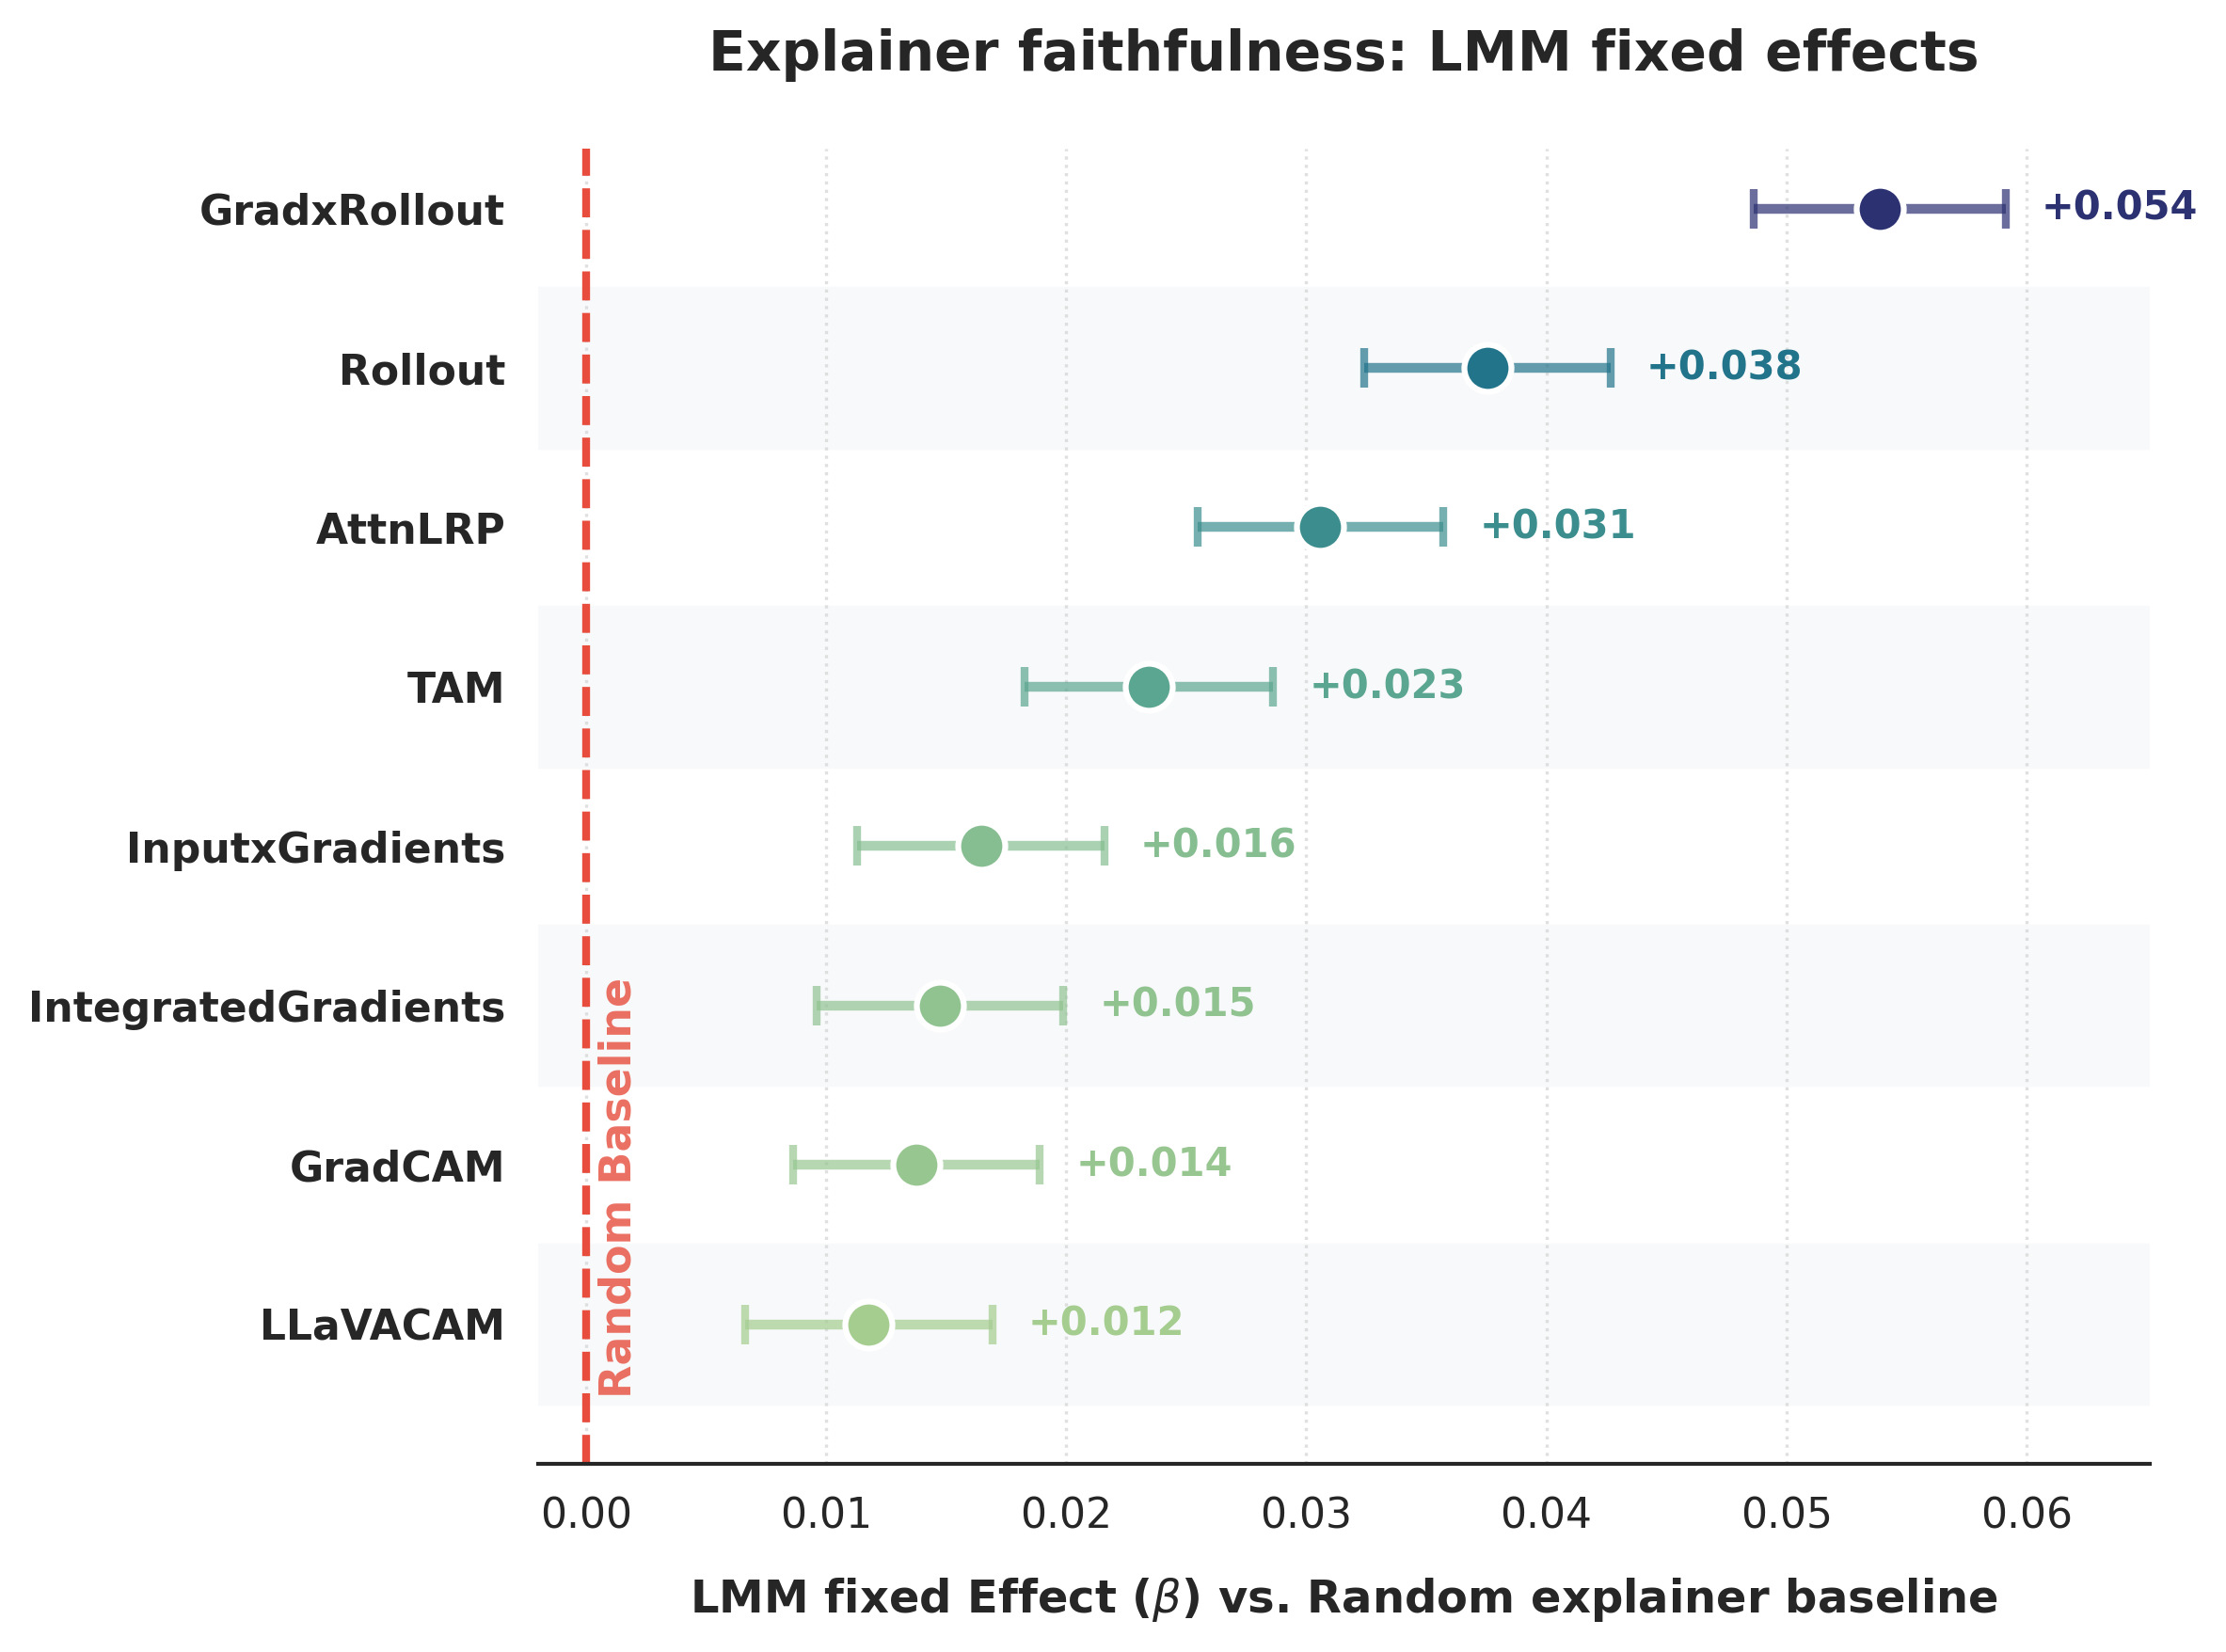

In [17]:
generate_forest_plot(summary_df=repope_df,
                    savefig=True, format='pdf',
                    save_path="lmm_forest_plot_big_mmstar")

--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_mmstar_forest_plot.pdf


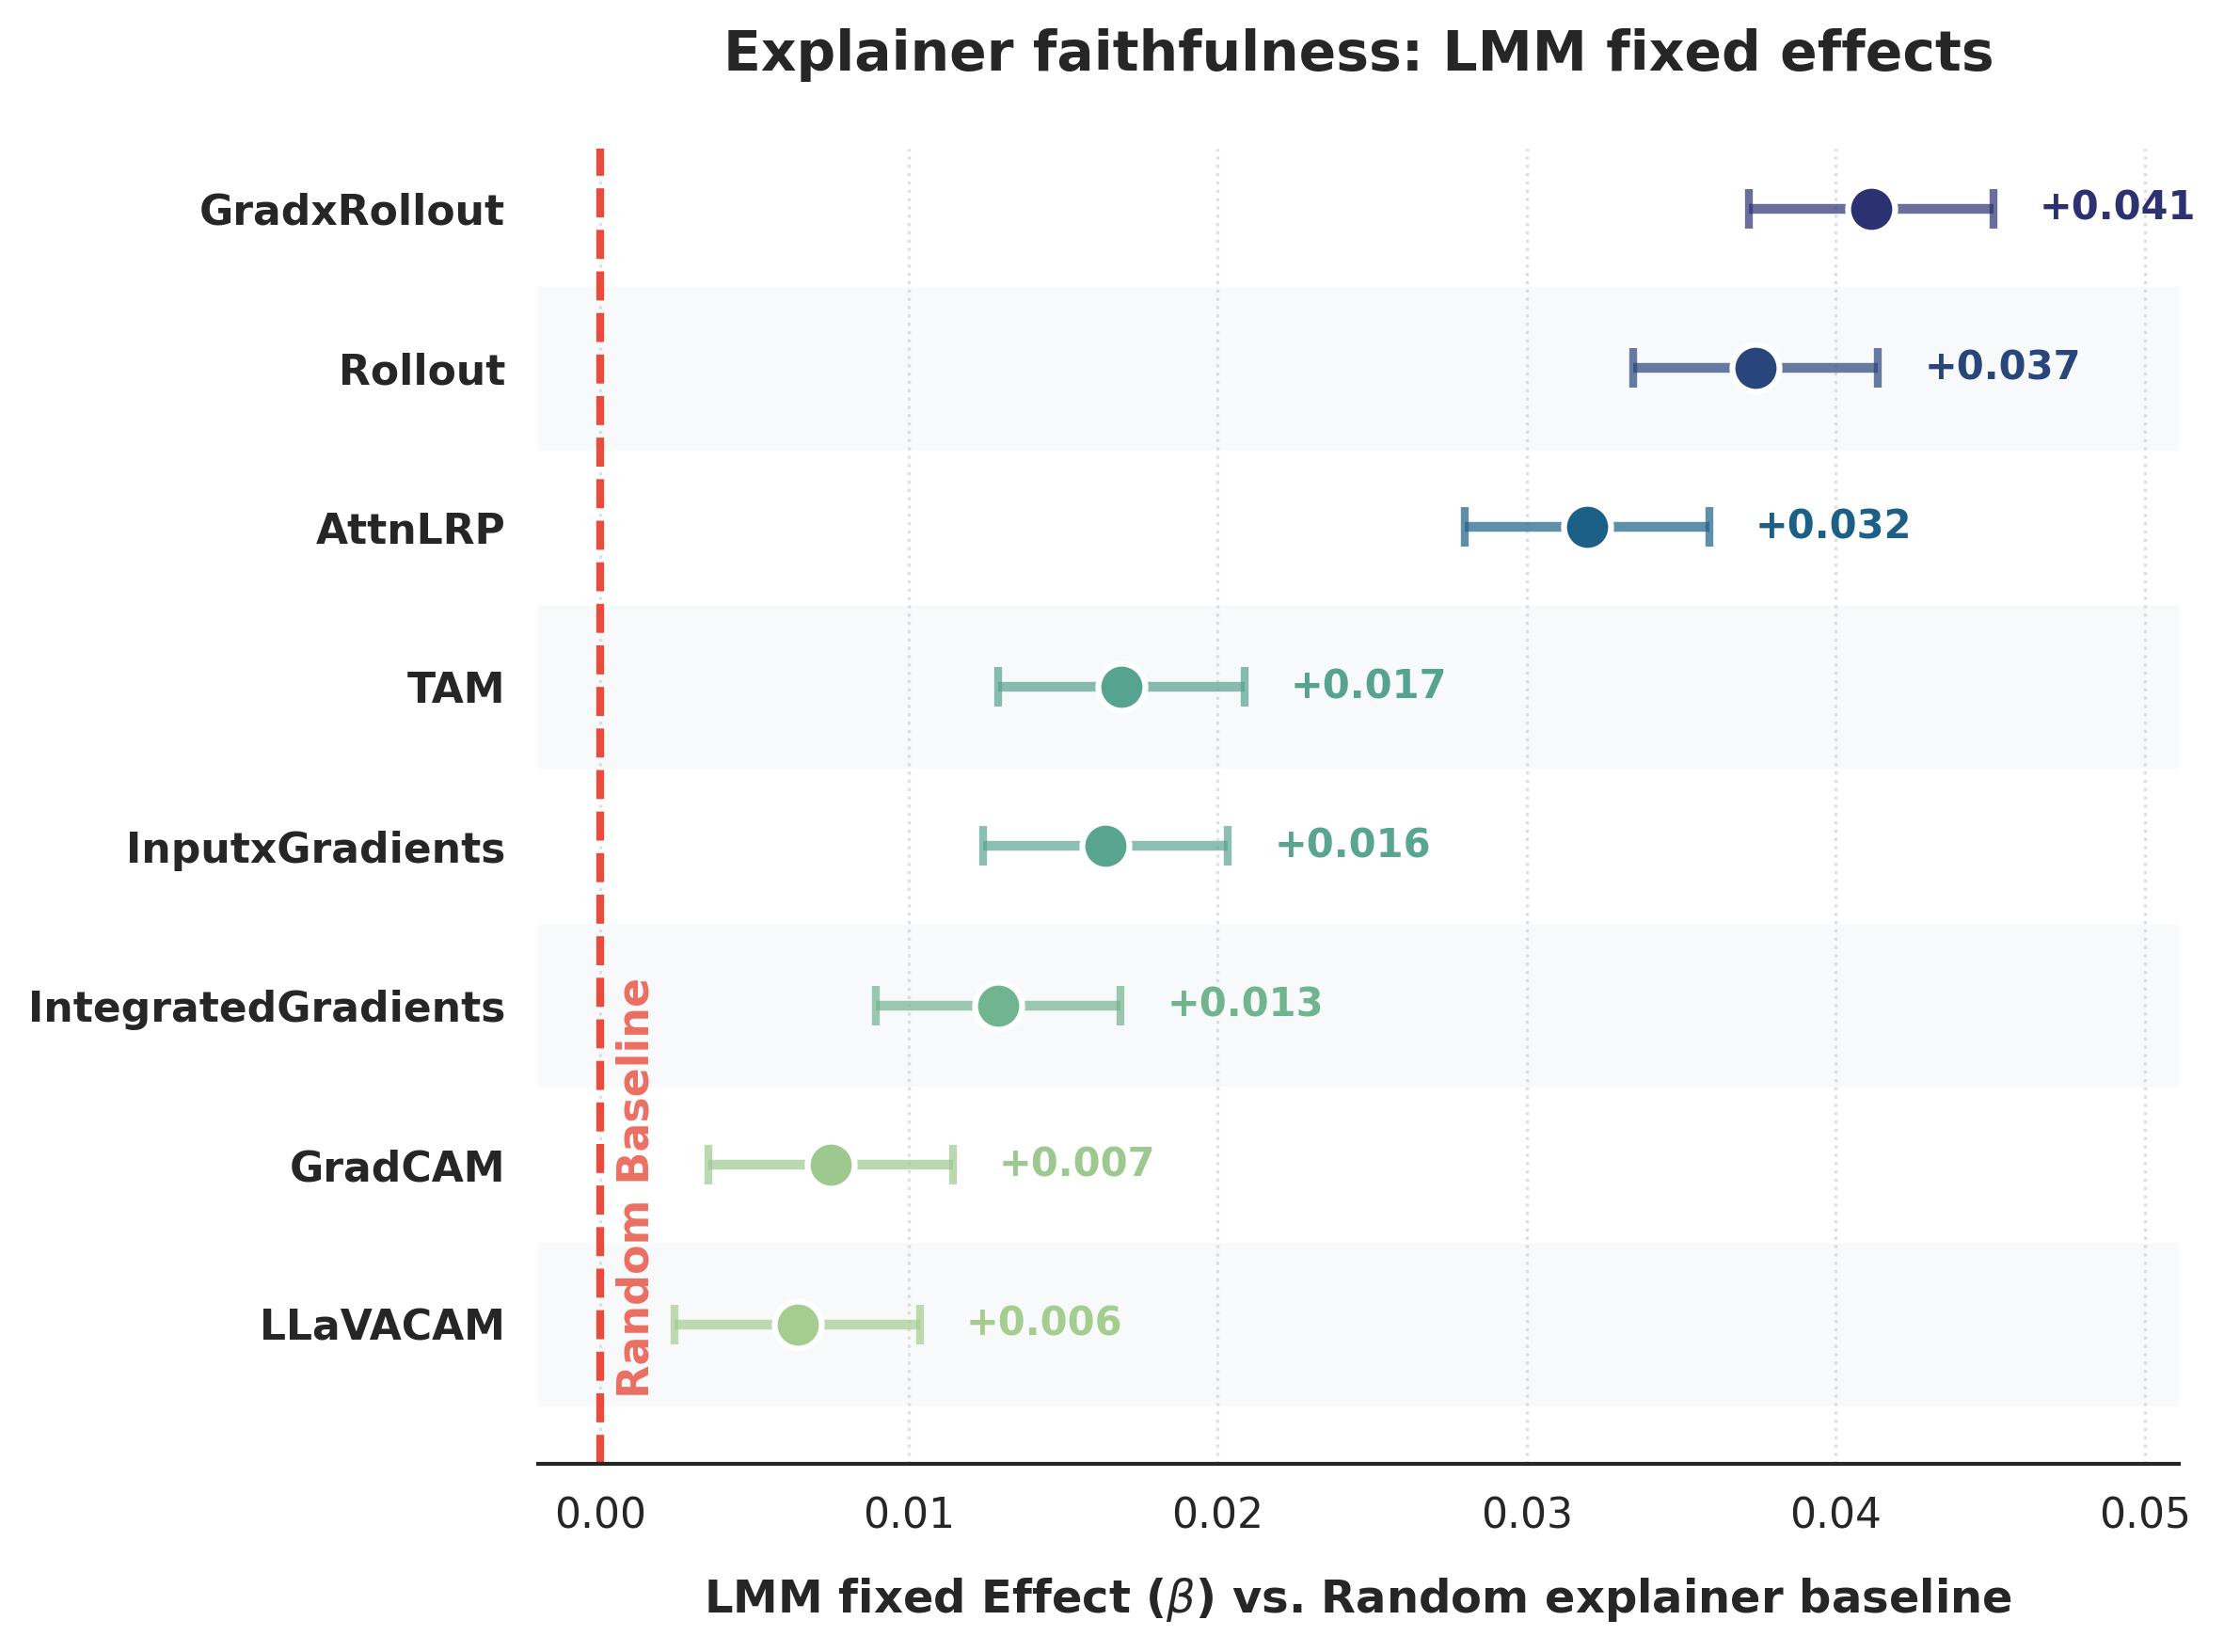

In [33]:
generate_forest_plot(summary_df=mmstar_df,
                    savefig=True, format='pdf',
                    save_path="lmm_mmstar_forest_plot")

--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_cvbench_forest_plot.pdf


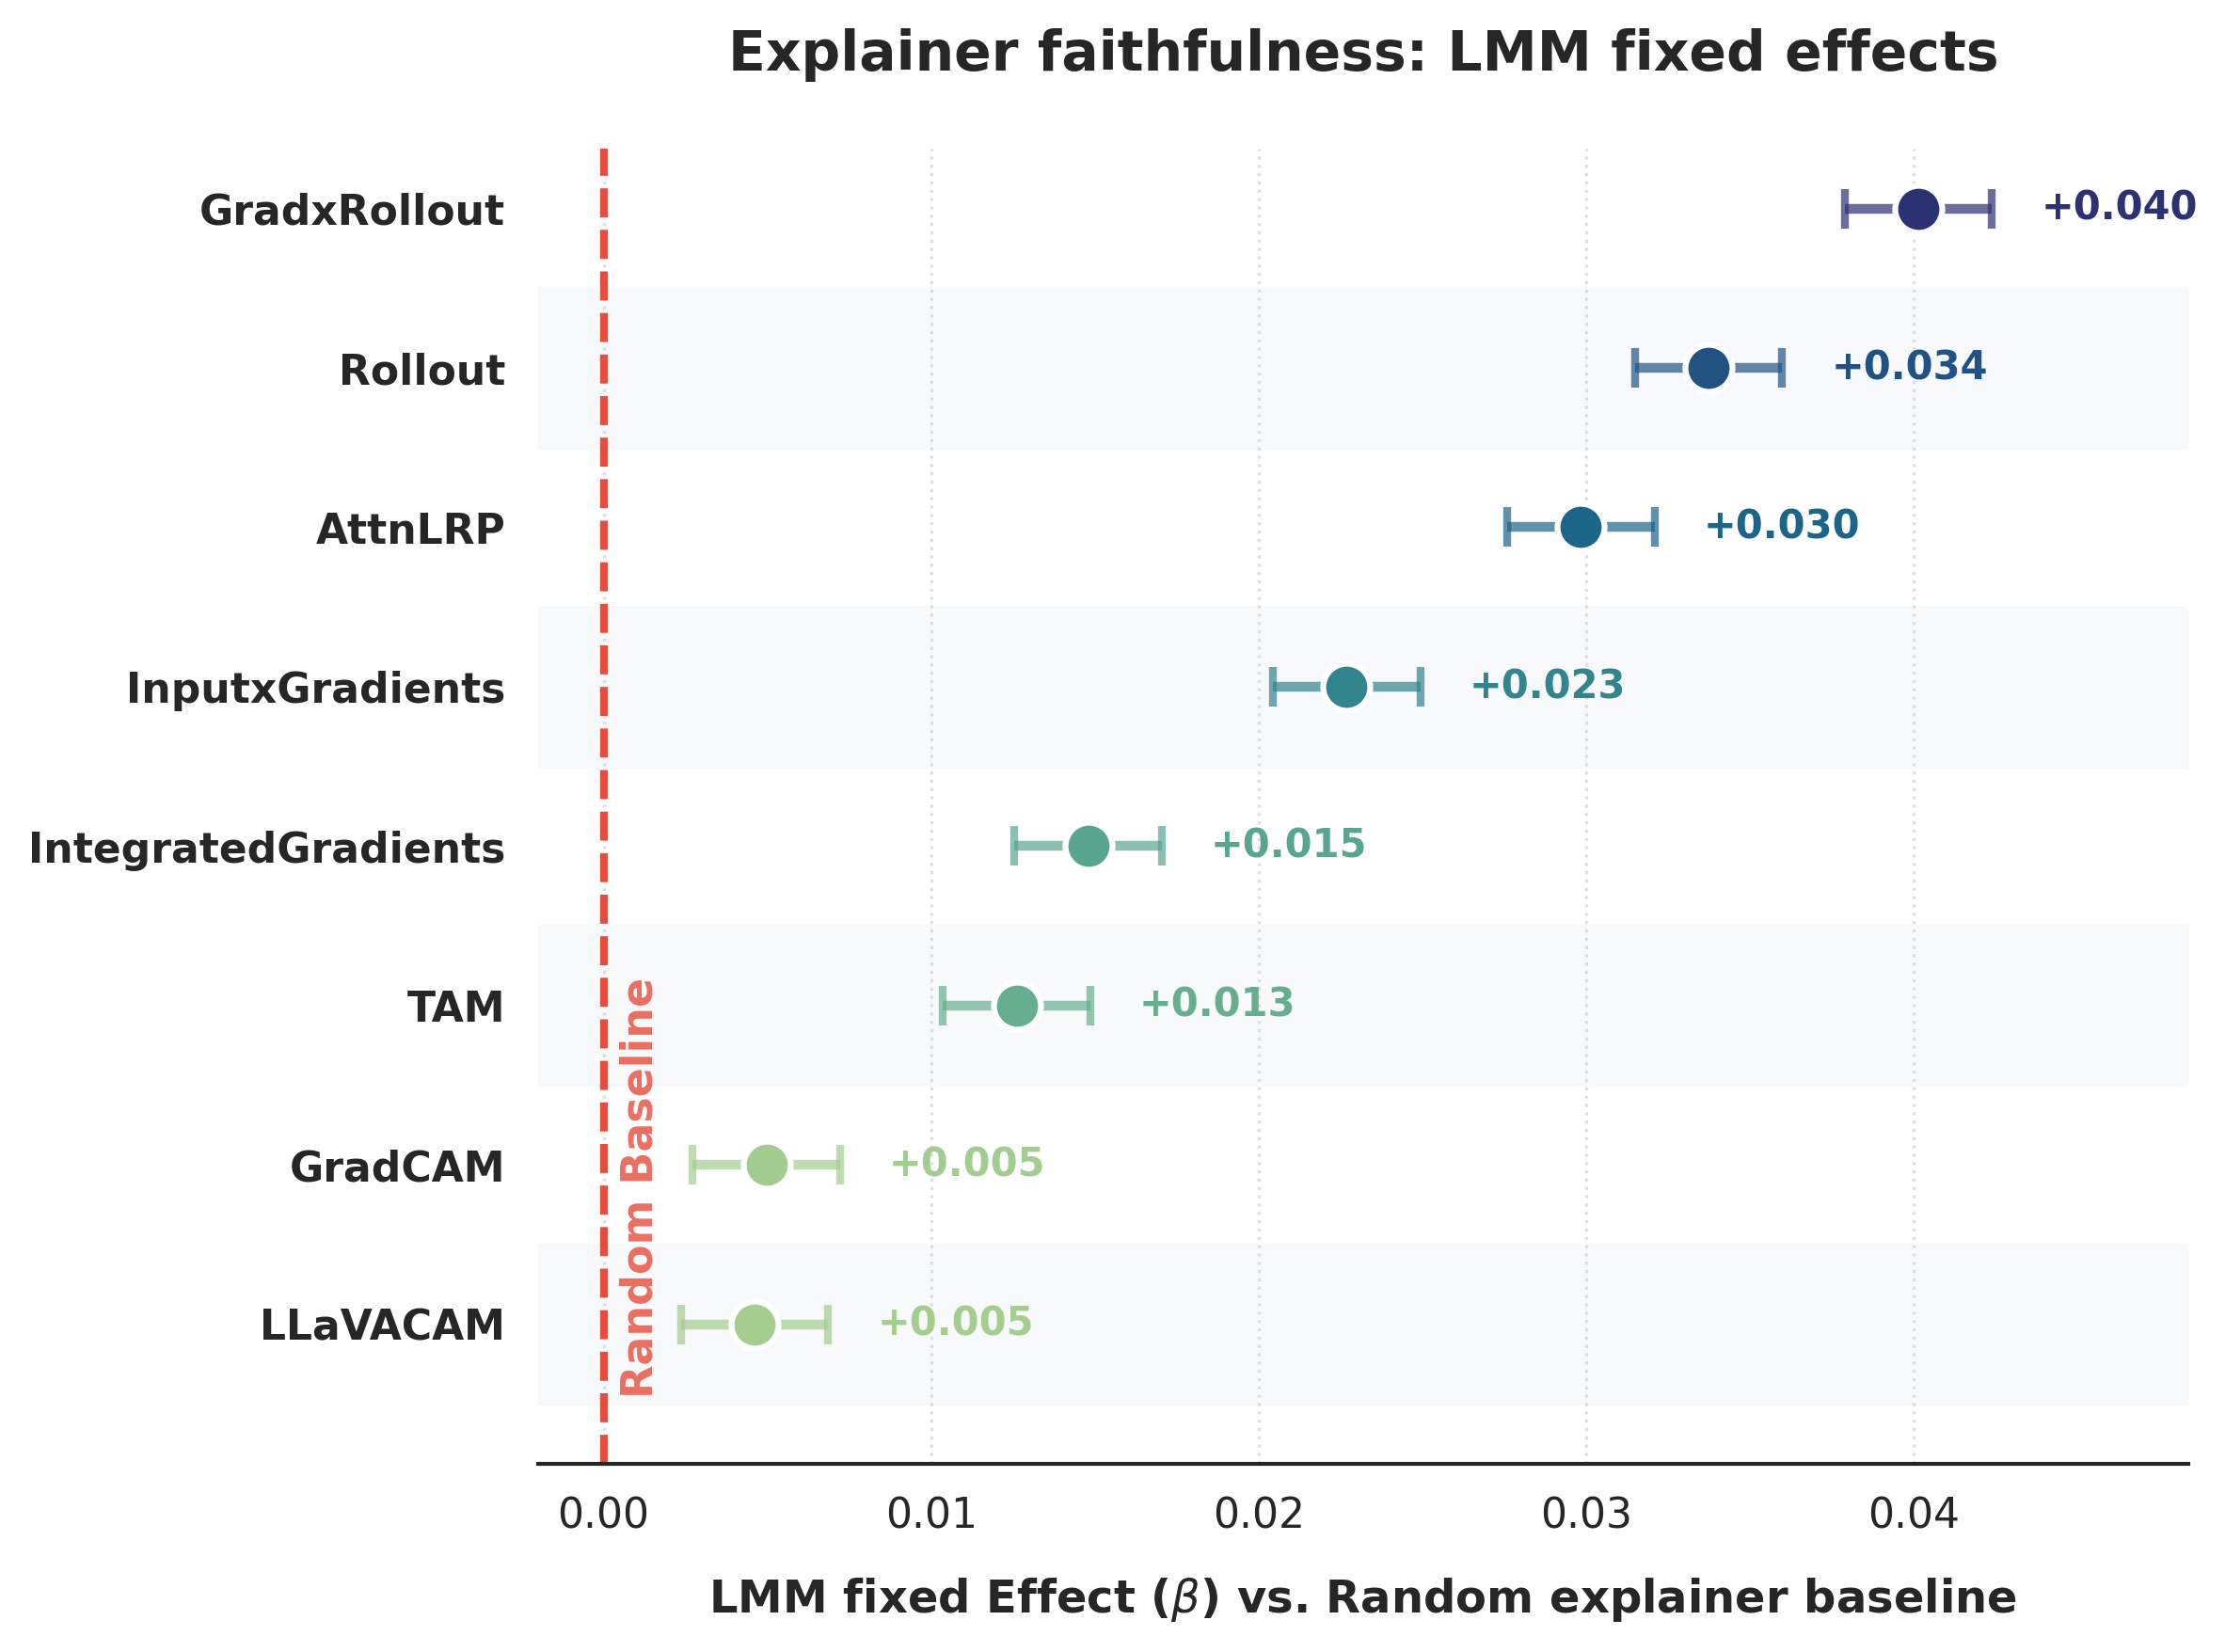

In [34]:
generate_forest_plot(summary_df=cvbench_df,
                    savefig=True, format='pdf',
                    save_path="lmm_cvbench_forest_plot")

--- Generating Upgraded LMM Forest Plot ---
[*] Saved stunning figure to ../figs/lmm_repope_forest_plot.pdf


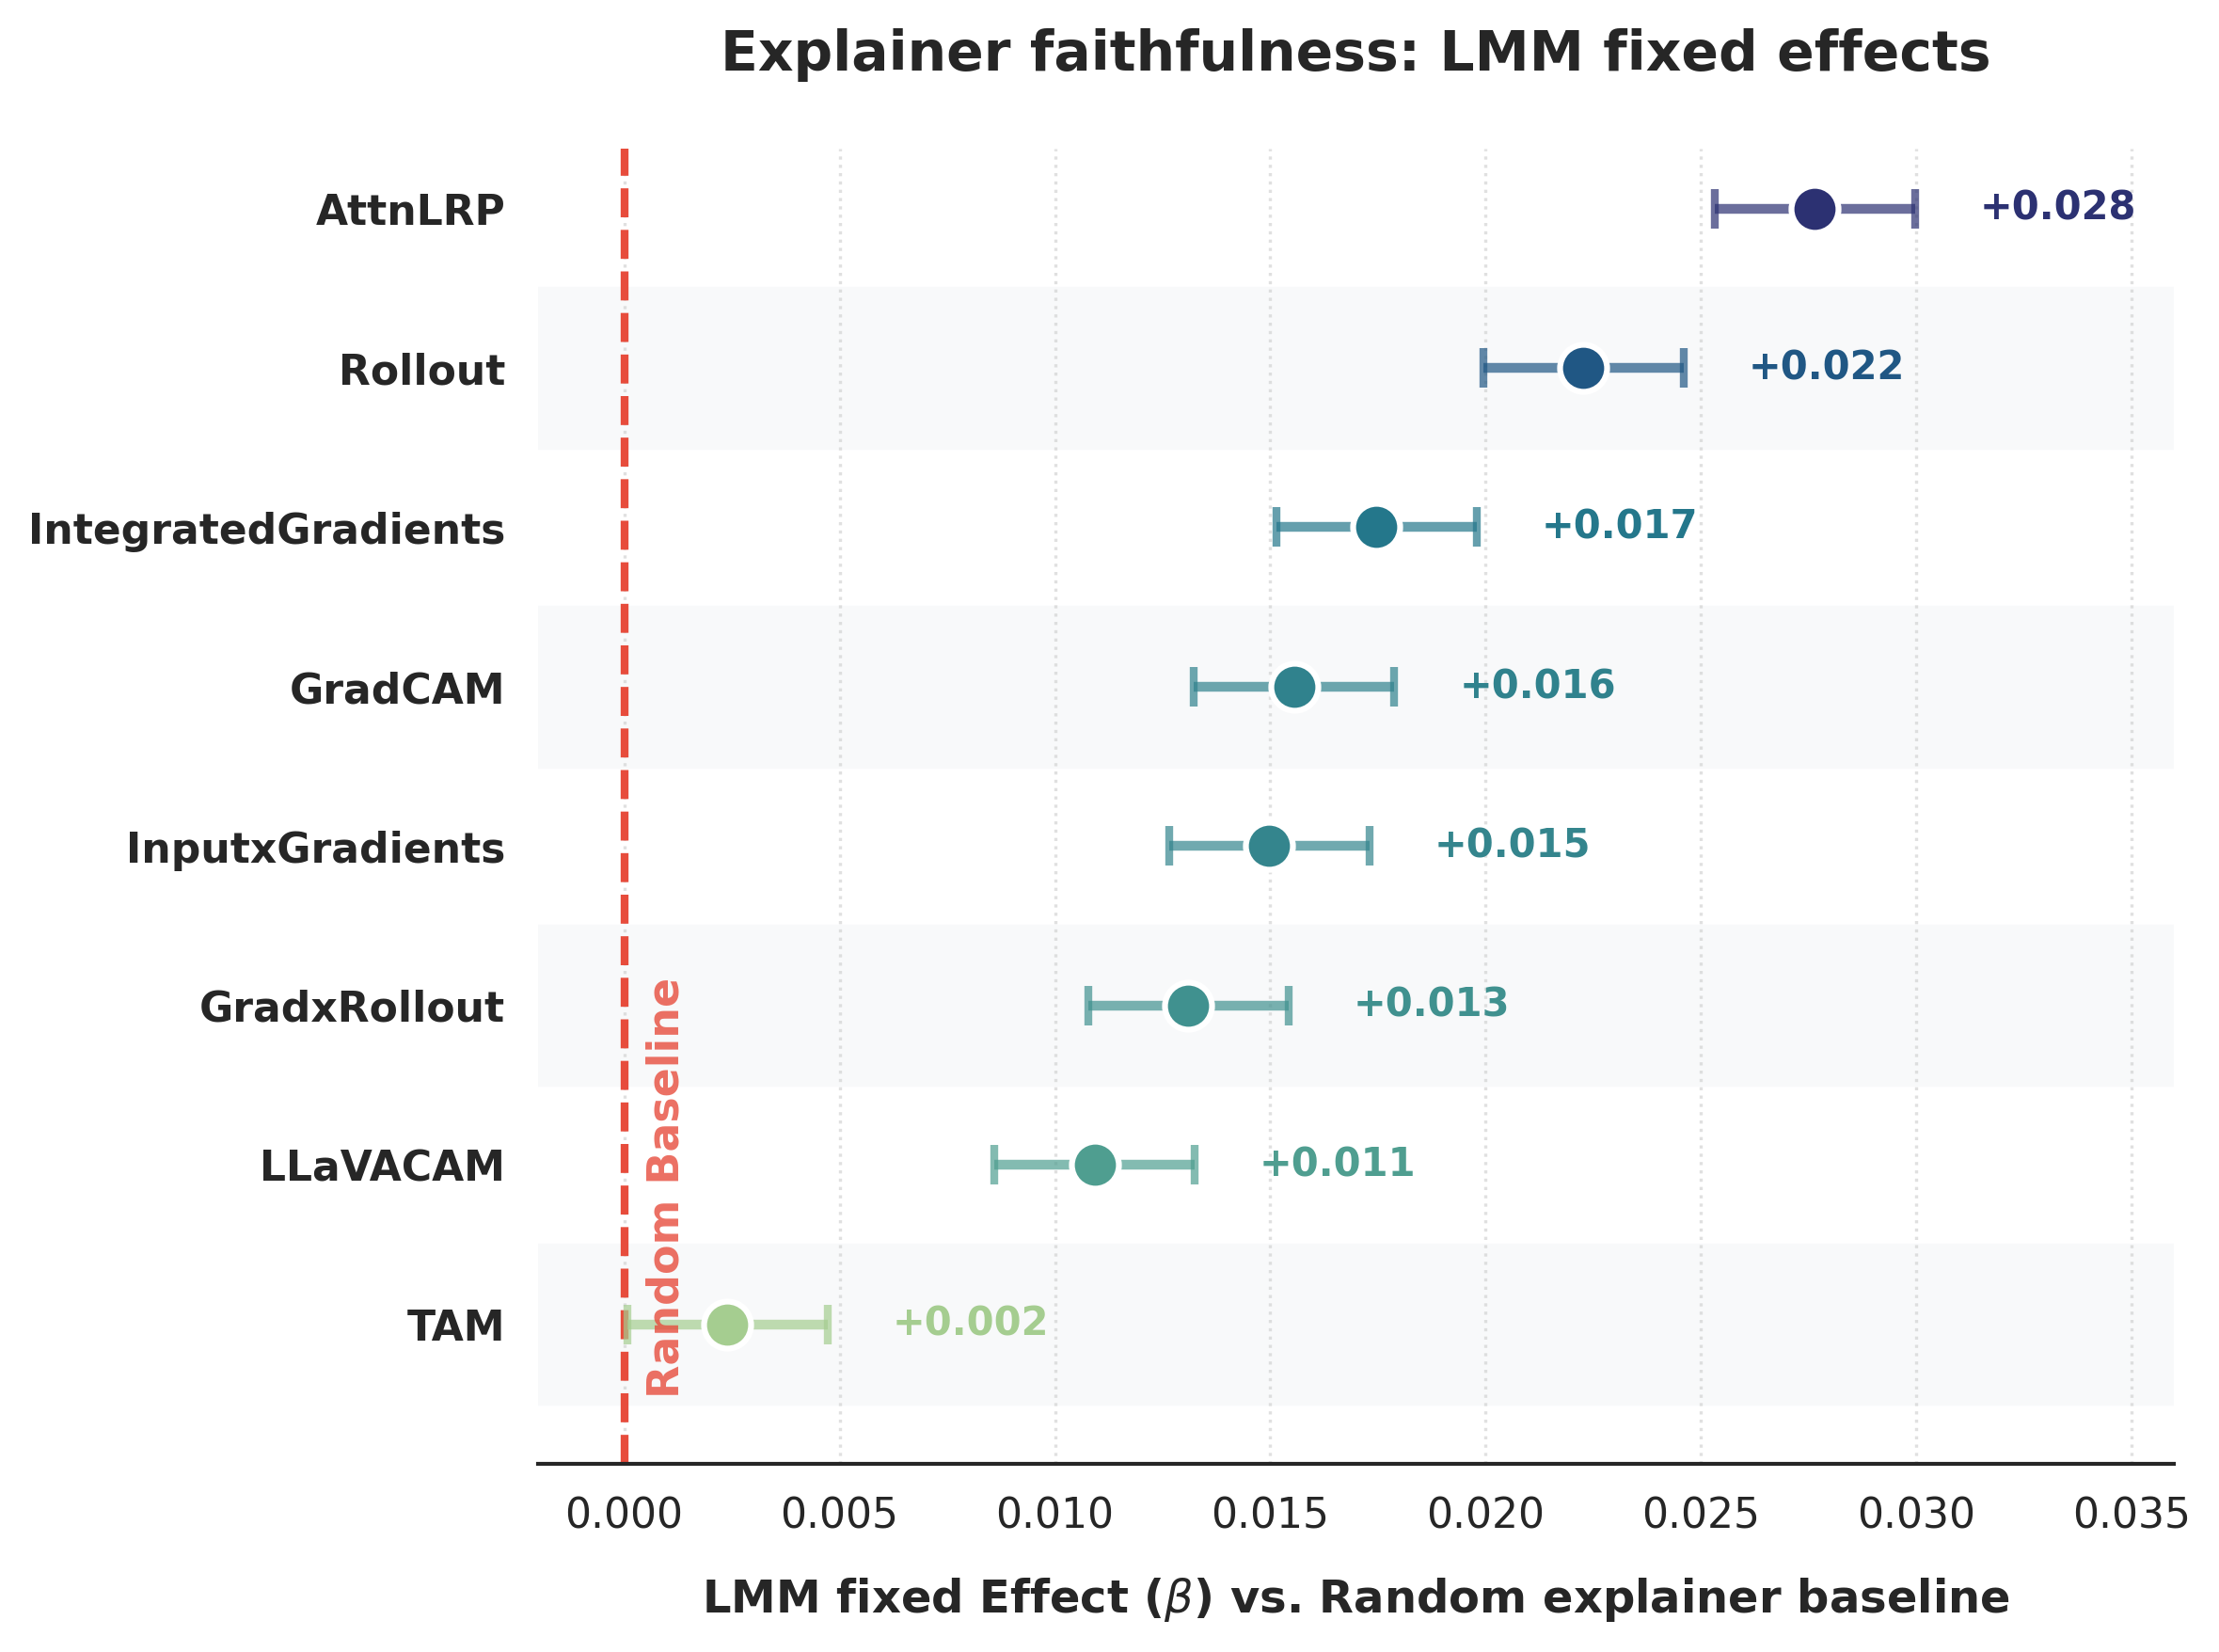

In [35]:
generate_forest_plot(summary_df=repope_df,
                    savefig=True, format='pdf',
                    save_path="lmm_repope_forest_plot")

In [ ]:
import pandas as pd
import numpy as np

def format_pvalue(p):
    """Formats the p-value with LaTeX significance stars."""
    if pd.isna(p):
        return "---"
    if p < 0.001:
        return r"$<0.001^{***}$"
    elif p < 0.01:
        return f"${p:.3f}^{{**}}$"
    elif p < 0.05:
        return f"${p:.3f}^{{*}}$"
    else:
        return f"${p:.3f}$"

def generate_latex_lmm_table(repope_path, cvbench_path, mmstar_path):
    """Reads the LMM CSVs and generates the complete LaTeX table."""
    
    # 1. Load the dataframes and set the Explainer column as index
    df_repope = pd.read_csv(repope_path).set_index('Explainer')
    df_cvbench = pd.read_csv(cvbench_path).set_index('Explainer')
    df_mmstar = pd.read_csv(mmstar_path).set_index('Explainer')

    # print(df_cvbench)
    # print(df_repope)
    # print(df_mmstar)

    # Add suffixes to differentiate the columns during concatenation
    df_repope.columns = [f"{c}_rep" for c in df_repope.columns]
    df_cvbench.columns = [f"{c}_cvb" for c in df_cvbench.columns]
    df_mmstar.columns = [f"{c}_mms" for c in df_mmstar.columns]

    # Combine them into one master dataframe
    df_merged = pd.concat([df_repope, df_cvbench, df_mmstar], axis=1)

    # 2. Define the exact grouping and LaTeX-formatted names
    # Dictionary mapping: { "Name in CSV" : "Beautiful LaTeX Name" }
    explainer_groups = [
        # Group 1: Attention-based
        {
            'AttnLRP': 'AttnLRP',
            'GradxRollout': r'Grad$\times$Rollout',
            'Rollout': 'Rollout'
        },
        # Group 2: VLM-native
        {
            'TAM': 'TAM',
            'LLaVACAM': 'LLaVA-CAM'
        },
        # Group 3: Classical
        {
            'GradCAM': 'GradCAM',
            'InputxGradients': r'Input$\times$Grad',
            'IntegratedGradients': 'Integ. Gradients'
        }
    ]

    # 3. Build the LaTeX String
    latex_str = r"""\begin{table}[h]
\centering
\caption{Dataset-Specific LMM Statistics for $\mathcal{F}_{syn}$. All values are calculated relative to the Random Attribution baseline. Significance thresholds: $^* p < 0.05$, $^{**} p < 0.01$, $^{***} p < 0.001$.}
\label{tab:lmm_pvalues}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l | r r r | r r r | r r r}
\toprule
\textbf{} & \multicolumn{3}{c|}{\textbf{RePOPE}} & \multicolumn{3}{c|}{\textbf{CVBench}} & \multicolumn{3}{c}{\textbf{MMStar}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
\textbf{Explainer} & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value \\
\midrule
"""

    # 4. Iterate through groups and build rows
    for i, group in enumerate(explainer_groups):
        for raw_name, latex_name in group.items():
            # If the explainer isn't in the dataframe, skip it gracefully
            if raw_name not in df_merged.index:
                continue
            
            row = df_merged.loc[raw_name]
            
            # Format RePOPE
            rep_coef = f"{row['coef_rep']:.3f}"
            rep_se   = f"{row['se_rep']:.3f}"
            rep_p    = format_pvalue(row['pvalue_rep'])
            
            # Format CVBench
            cvb_coef = f"{row['coef_cvb']:.3f}"
            cvb_se   = f"{row['se_cvb']:.3f}"
            cvb_p    = format_pvalue(row['pvalue_cvb'])
            
            # Format MMStar
            mms_coef = f"{row['coef_mms']:.3f}"
            mms_se   = f"{row['se_mms']:.3f}"
            mms_p    = format_pvalue(row['pvalue_mms'])
            
            # Add the row to the table
            latex_str += f"{latex_name} & {rep_coef} & {rep_se} & {rep_p} & {cvb_coef} & {cvb_se} & {cvb_p} & {mms_coef} & {mms_se} & {mms_p} \\\\\n"
        
        # Add a midrule after each group (except the last one)
        if i < len(explainer_groups) - 1:
            latex_str += "\\midrule\n"

    # 5. Finish the table
    latex_str += r"""\bottomrule
\end{tabular}%
}
\end{table}"""

    return latex_str



In [57]:
# ==========================================
# HOW TO RUN IT:
# ==========================================
# Point these paths to the CSVs generated by your compute_and_save_lmm() function
repope_csv = "../logs/lmm_repope_fsyn.csv"
cvbench_csv = "../logs/lmm_cvbench_fsyn.csv"
mmstar_csv = "../logs/lmm_mmstar_fsyn.csv"

# Generate and print the LaTeX code!
final_latex = generate_latex_lmm_table(repope_csv, cvbench_csv, mmstar_csv)
print(final_latex)


\begin{table}[h]
\centering
\caption{Dataset-Specific LMM Statistics for $\mathcal{F}_{syn}$. All values are calculated relative to the Random Attribution baseline. Significance thresholds: $^* p < 0.05$, $^{**} p < 0.01$, $^{***} p < 0.001$.}
\label{tab:lmm_pvalues}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l | r r r | r r r | r r r}
\toprule
\textbf{} & \multicolumn{3}{c|}{\textbf{RePOPE}} & \multicolumn{3}{c|}{\textbf{CVBench}} & \multicolumn{3}{c}{\textbf{MMStar}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
\textbf{Explainer} & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value & $\beta$ Coef & SE & $p$-value \\
\midrule
AttnLRP & 0.028 & 0.001 & $<0.001^{***}$ & 0.030 & 0.001 & $<0.001^{***}$ & 0.032 & 0.002 & $<0.001^{***}$ \\
Grad$\times$Rollout & 0.013 & 0.001 & $<0.001^{***}$ & 0.040 & 0.001 & $<0.001^{***}$ & 0.041 & 0.002 & $<0.001^{***}$ \\
Rollout & 0.022 & 0.001 & $<0.001^{***}$ & 0.034 & 0.001 & $<0.001^{***}$ & 0.037 & 0.002 & $<0.001^{***}

In [42]:
print("df1 has duplicate index:", cvbench_df.index.duplicated().any())
print("df2 has duplicate index:", mmstar_df.index.duplicated().any())
print("df2 has duplicate index:", repope_df.index.duplicated().any())

df1 has duplicate index: False
df2 has duplicate index: False
df2 has duplicate index: False


##### Generate table 

In [10]:
import pandas as pd
import numpy as np

def generate_latex_table_with_overall(df, metric='syn_synergy_norm_auc', columns='Model'):
    """
    Generates a Pandas Pivot Table with Mean ± Std, a true Overall column, 
    and exports the LaTeX code.
    """
    print(f"\n--- Generating LaTeX Table for {metric} (Mean ± Std) with OVERALL ---")
    
    # 1. Calculate Mean and Std for the individual columns (e.g., per Model)
    mean_df = df.pivot_table(index='Explainer', columns=columns, values=metric, aggfunc='mean')
    std_df = df.pivot_table(index='Explainer', columns=columns, values=metric, aggfunc='std')
    
    # 2. Calculate the TRUE Overall Mean and Std directly from the raw dataframe
    # This prevents the "averaging averages" math error.
    overall_mean = df.groupby('Explainer')[metric].mean()
    overall_std = df.groupby('Explainer')[metric].std()
    
    # Sort explainers from best to worst based on the true overall mean
    overall_mean = overall_mean.sort_values(ascending=False)
    
    # Align all dataframes to the newly sorted index
    mean_df = mean_df.reindex(overall_mean.index)
    std_df = std_df.reindex(overall_mean.index)
    overall_std = overall_std.reindex(overall_mean.index)
    
    # 3. Combine them into formatted strings: "Mean $\pm$ Std"
    combined_df = mean_df.copy()
    for col in mean_df.columns:
        combined_df[col] = mean_df[col].apply(lambda x: f"{x:.3f}") + r"$_{(\pm" + std_df[col].apply(lambda x: f"{x:.2f}") + ")}$"
    
    # 4. Add the formatted Overall column
    combined_df['Overall'] = overall_mean.apply(lambda x: f"{x:.3f}") + r"$_{(\pm" + overall_std.apply(lambda x: f"{x:.2f}") + ")}$"
    
    # 5. Export to LaTeX
    # escape=False prevents Pandas from breaking our LaTeX math formatting
    latex_code = combined_df.to_latex(escape=False)
    
    print(latex_code)
    return combined_df

# Run it!
# table_df = generate_latex_table_with_overall(df, metric='syn_synergy_norm_auc', columns='Model')

In [11]:
pivot = generate_latex_table_with_overall(df, metric='syn_synergy_norm_auc')


--- Generating LaTeX Table for syn_synergy_norm_auc (Mean ± Std) with OVERALL ---
\begin{tabular}{lllll}
\toprule
Model & internvl_14b & llava_13b & qwen3_5_27b & Overall \\
Explainer &  &  &  &  \\
\midrule
GradxRollout & 0.282$_{(\pm0.18)}$ & 0.107$_{(\pm0.13)}$ & 0.270$_{(\pm0.17)}$ & 0.204$_{(\pm0.18)}$ \\
Rollout & 0.227$_{(\pm0.16)}$ & 0.100$_{(\pm0.12)}$ & 0.260$_{(\pm0.17)}$ & 0.178$_{(\pm0.16)}$ \\
AttnLRP & 0.231$_{(\pm0.18)}$ & 0.097$_{(\pm0.12)}$ & 0.232$_{(\pm0.16)}$ & 0.174$_{(\pm0.17)}$ \\
TAM & 0.200$_{(\pm0.15)}$ & 0.084$_{(\pm0.11)}$ & 0.253$_{(\pm0.16)}$ & 0.161$_{(\pm0.15)}$ \\
InputxGradients & 0.208$_{(\pm0.15)}$ & 0.086$_{(\pm0.11)}$ & 0.221$_{(\pm0.15)}$ & 0.158$_{(\pm0.15)}$ \\
IntegratedGradients & 0.197$_{(\pm0.15)}$ & 0.085$_{(\pm0.10)}$ & 0.226$_{(\pm0.15)}$ & 0.153$_{(\pm0.14)}$ \\
LLaVACAM & 0.200$_{(\pm0.15)}$ & 0.076$_{(\pm0.10)}$ & 0.230$_{(\pm0.15)}$ & 0.152$_{(\pm0.15)}$ \\
GradCAM & 0.193$_{(\pm0.15)}$ & 0.077$_{(\pm0.10)}$ & 0.243$_{(\pm0.16)}$ & 

In [20]:
df.Dataset.unique()

array(['cv_bench', 'mmstar'], dtype=object)

##### Other plots

In [15]:
df.head()

,sample_idx,question,Explainer,xai_gen_time,label,syn_synergy_auc,syn_synergy_norm_auc,syn_del_norm_auc,syn_ins_norm_auc,syn_del_auc,...,img_srg_norm,img_srg,img_norm_auc_del,img_norm_auc_ins,img_auc_del,img_auc_ins,tok_norm_auc_del,tok_norm_auc_ins,tok_auc_del,tok_auc_ins
0,0,Is there a snowboard in the image?,LLaVACAM,5.528804,yes,-0.203427,0.003922,0.007797,0.000047,-0.159337,...,0.089499,0.070239,0.470024,0.559524,0.510962,0.581201,0.311362,0.482354,0.293529,0.459483
1,1,Is there a car in the image?,LLaVACAM,6.026171,no,0.002150,0.014125,0.001659,0.026591,-0.021948,...,-0.037500,-0.002734,0.883333,0.845833,0.973438,0.970703,0.466356,0.354049,0.190558,0.138512
2,2,Is there a person in the image?,LLaVACAM,5.402166,yes,0.253993,0.279142,0.311483,0.246800,0.285203,...,-0.255605,-0.233533,0.686057,0.430453,0.691138,0.457605,0.307264,0.492782,0.298079,0.481618
3,3,Is there a sandwich in the image?,LLaVACAM,7.141232,no,0.024912,0.031120,0.000801,0.061440,-0.008612,...,-0.043704,-0.021680,0.801852,0.758148,0.749316,0.727637,0.050019,0.825798,0.048862,0.814259
4,4,Is there a skis in the image?,LLaVACAM,5.534935,no,-0.313967,0.021965,0.024832,0.019098,-0.185852,...,0.003049,-0.007715,0.591057,0.594106,0.460229,0.452515,0.319678,0.495919,0.207713,0.365638


In [16]:
mu_I_col="img_srg_norm"
mu_T_col="tok_srg_norm"
syn_col="syn_synergy_norm_auc"
dataset_name="repope_all"

df_sub = df[df['Dataset'] == dataset_name]

grouped = df_sub.groupby(['Model', 'Explainer'])[[mu_I_col, mu_T_col, syn_col]].agg(['mean', 'std'])

In [17]:
grouped

img_srg_norm           tok_srg_norm            \
                                     mean       std         mean       std   
Model    Explainer                                                           
internvl AttnLRP                 0.033054  0.131023     0.238989  0.287857   
         GradCAM                -0.043980  0.246525     0.043193  0.184188   
         GradxRollout            0.017633  0.236173     0.085442  0.157034   
         InputxGradients         0.020503  0.155334     0.030082  0.243998   
         IntegratedGradients    -0.013435  0.127040     0.216205  0.287792   
         LLaVACAM               -0.061689  0.255911     0.021141  0.192610   
         Random                 -0.003562  0.074713     0.039384  0.282764   
         Rollout                 0.211147  0.228183     0.123620  0.122907   
         TAM                    -0.032740  0.263739     0.025504  0.208875   
llava    AttnLRP                 0.013259  0.074705     0.320586  0.243075   
         GradCAM                -0.108324  0.336958     0.288125  0.344932   
         GradxRollout            0.110039  0.263971     0.128583  0.184328   
         InputxGradients         0.012673  0.087303    -0.060342  0.673651   
         IntegratedGradients     0.001360  0.077894    -0.641449  0.298755   
         LLaVACAM               -0.132696  0.364500     0.278511  0.370067   
         Random                  0.002731  0.060061    -0.633332  0.308100   
         Rollout                 0.141391  0.269803     0.531165  0.231564   
         TAM                    -0.075718  0.268917    -0.453946  0.321212   
qwenvl   AttnLRP                -0.000743  0.074923     0.263356  0.387702   
         GradCAM                 0.001938  0.086170     0.217698  0.297992   
         GradxRollout           -0.003399  0.086140     0.050393  0.206649   
         InputxGradients         0.001304  0.073796    -0.028211  0.261762   
         IntegratedGradients    -0.000132  0.075641     0.106536  0.380656   
         LLaVACAM                0.007128  0.094041     0.189277  0.305736   
         Random                 -0.001921  0.073383     0.024060  0.209147   
         Rollout                 0.002321  0.094296     0.236073  0.102360   
         TAM                     0.002473  0.088374     0.192220  0.284919   

                             syn_synergy_norm_auc            
                                             mean       std  
Model    Explainer                                           
internvl AttnLRP                         0.178113  0.163382  
         GradCAM                         0.141772  0.141114  
         GradxRollout                    0.147411  0.145696  
         InputxGradients                 0.158470  0.155866  
         IntegratedGradients             0.162031  0.157159  
         LLaVACAM                        0.139683  0.138446  
         Random                          0.126233  0.124492  
         Rollout                         0.176908  0.177209  
         TAM                             0.122307  0.132601  
llava    AttnLRP                         0.031866  0.050198  
         GradCAM                         0.029220  0.043097  
         GradxRollout                    0.032293  0.048721  
         InputxGradients                 0.028285  0.041377  
         IntegratedGradients             0.023152  0.036482  
         LLaVACAM                        0.028669  0.042911  
         Random                          0.022279  0.035878  
         Rollout                         0.036172  0.050010  
         TAM                             0.024958  0.038474  
qwenvl   AttnLRP                         0.076975  0.130907  
         GradCAM                         0.079462  0.121108  
         GradxRollout                    0.063478  0.117124  
         InputxGradients                 0.062136  0.104055  
         IntegratedGradients             0.071217  0.119742  
         LLaVACAM                        0.068215  0.108282  
         Rando

In [20]:
import pandas as pd
import numpy as np

def format_cell(mean_val, std_val):
    """Formats the mean and std into a compact LaTeX subscript string."""
    if pd.isna(mean_val) or pd.isna(std_val):
        return "---"
    # Format: $0.123_{\pm 0.012}$
    return f"${mean_val:.3f}_{{ \\pm {std_val:.3f} }}$"

def generate_exhaustive_latex_table(df, dataset_name, dataset_label="RePOPE",
                                    mu_I_col="img_srg_norm",
                                    mu_T_col="tok_srg_norm",
                                    syn_col="syn_synergy_norm_auc",
                                    ):
    """
    Generates the exhaustive metric table for a specific dataset.
    
    Assumed dataframe columns:
    - 'Dataset': Name of the dataset
    - 'Model': Architecture name (e.g., 'Qwen', 'LLaVA', 'InternVL')
    - 'Explainer': Name of the XAI method
    - 'mu_I': Unimodal visual score
    - 'mu_T': Unimodal textual score
    - 'F_syn': Synergistic Faithfulness score
    """
    # 1. Filter the dataset
    df_sub = df[df['Dataset'] == dataset_name]
    
    # 2. Group by Model and Explainer to calculate Mean and Std
    # This creates a MultiIndex dataframe
    grouped = df_sub.groupby(['Model', 'Explainer'])[[mu_I_col, mu_T_col, syn_col]].agg(['mean', 'std'])
    
    # 3. Define the exact Explainer grouping and formatting
    explainer_groups = [
        # Group 1: Attention-based
        {'AttnLRP': 'AttnLRP', 'GradxRollout': r'Grad$\times$Rollout', 'Rollout': 'Rollout'},
        # Group 2: VLM-native
        {'TAM': 'TAM', 'LLaVACAM': 'LLaVA-CAM'},
        # Group 3: Classical
        {'GradCAM': 'GradCAM', 'InputxGradients': r'Input$\times$Grad', 'IntegratedGradients': 'Integ. Gradients'},
        # Group 4: Baseline
        {'Random': 'Random (Baseline)'}
    ]
    
    # 4. Define your Models as they appear in your DataFrame
    models = ['qwenvl', 'llava', 'internvl'] # Update these strings to match your data exactly!

    # 5. Build the LaTeX Header
    latex_str = f"""\\begin{{table}}[h]
\\centering
\\caption{{Comprehensive Benchmark Results on the \\textbf{{{dataset_label}}} Dataset. Values represent the unadjusted mean scores $\\pm$ standard deviation across all dataset instances.}}
\\label{{tab:full_{dataset_name.lower()}}}
\\resizebox{{\\textwidth}}{{!}}{{%\n\\begin{{tabular}}{{l | ccc | ccc | ccc}}
\\toprule
& \\multicolumn{{3}}{{c|}}{{\\textbf{{Qwen2.5-VL}}}} & \\multicolumn{{3}}{{c|}}{{\\textbf{{LLaVA-1.5}}}} & \\multicolumn{{3}}{{c}}{{\\textbf{{InternVL-3.5 }}}} \\\\
\\cmidrule(lr){{2-4}} \\cmidrule(lr){{5-7}} \\cmidrule(lr){{8-10}}
\\textbf{{Explainer}} & $\\mu_I^{{srg}}$ & $\\mu_T^{{srg}}$ & $\\mathcal{{F}}_{{syn}}$ & $\\mu_I^{{srg}}$ & $\\mu_T^{{srg}}$ & $\\mathcal{{F}}_{{syn}}$ & $\\mu_I^{{srg}}$ & $\\mu_T^{{srg}}$ & $\\mathcal{{F}}_{{syn}}$ \\\\
\\midrule\n"""

    # 6. Build the Rows
    for i, group in enumerate(explainer_groups):
        for raw_name, latex_name in group.items():
            row_str = f"{latex_name} "
            
            for mod in models:
                try:
                    # Extract the stats for this Model + Explainer combo
                    stats = grouped.loc[(mod, raw_name)]
                    
                    cell_I = format_cell(stats[(mu_I_col, 'mean')], stats[(mu_I_col, 'std')])
                    cell_T = format_cell(stats[(mu_T_col, 'mean')], stats[(mu_T_col, 'std')])
                    cell_F = format_cell(stats[(syn_col, 'mean')], stats[(syn_col, 'std')])
                    
                except KeyError:
                    # If this model/explainer combo wasn't run or is missing
                    cell_I, cell_T, cell_F = "---", "---", "---"
                
                row_str += f"& {cell_I} & {cell_T} & {cell_F} "
            
            row_str += "\\\\\n"
            latex_str += row_str
            
        # Add a midrule after each group (except the last one)
        if i < len(explainer_groups) - 1:
            latex_str += "\\midrule\n"

    # 7. Close the table
    latex_str += r"""\bottomrule
\end{tabular}%
}
\end{table}"""

    return latex_str



In [23]:


# Generate tables for each dataset
table_repope = generate_exhaustive_latex_table(df, dataset_name="repope_all", dataset_label="RePOPE")
print(table_repope)


\begin{table}[h]
\centering
\caption{Comprehensive Benchmark Results on the \textbf{RePOPE} Dataset. Values represent the unadjusted mean scores $\pm$ standard deviation across all dataset instances.}
\label{tab:full_repope_all}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l | ccc | ccc | ccc}
\toprule
& \multicolumn{3}{c|}{\textbf{Qwen2.5-VL}} & \multicolumn{3}{c|}{\textbf{LLaVA-1.5}} & \multicolumn{3}{c}{\textbf{InternVL-3.5 }} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
\textbf{Explainer} & $\mu_I^{srg}$ & $\mu_T^{srg}$ & $\mathcal{F}_{syn}$ & $\mu_I^{srg}$ & $\mu_T^{srg}$ & $\mathcal{F}_{syn}$ & $\mu_I^{srg}$ & $\mu_T^{srg}$ & $\mathcal{F}_{syn}$ \\
\midrule
AttnLRP & $-0.001_{ \pm 0.075 }$ & $0.263_{ \pm 0.388 }$ & $0.077_{ \pm 0.131 }$ & $0.013_{ \pm 0.075 }$ & $0.321_{ \pm 0.243 }$ & $0.032_{ \pm 0.050 }$ & $0.033_{ \pm 0.131 }$ & $0.239_{ \pm 0.288 }$ & $0.178_{ \pm 0.163 }$ \\
Grad$\times$Rollout & $-0.003_{ \pm 0.086 }$ & $0.050_{ \pm 0.207 }$ & $0.063_{ \pm 0

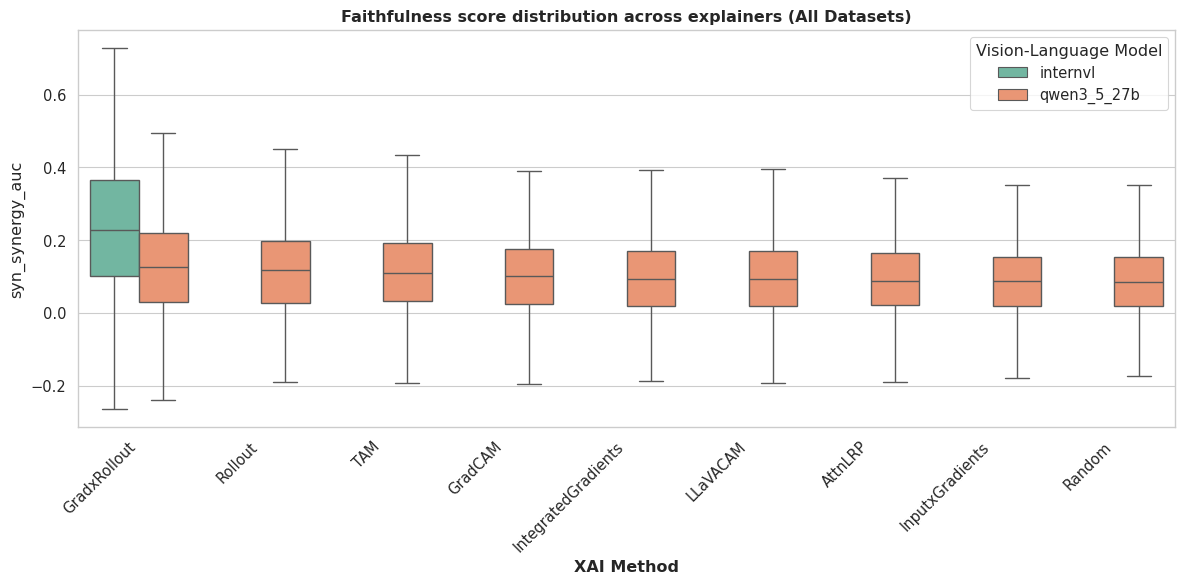

In [19]:
plot_macro_boxplot(df, metric='syn_synergy_auc', dataset_filter=None, savefig=False)

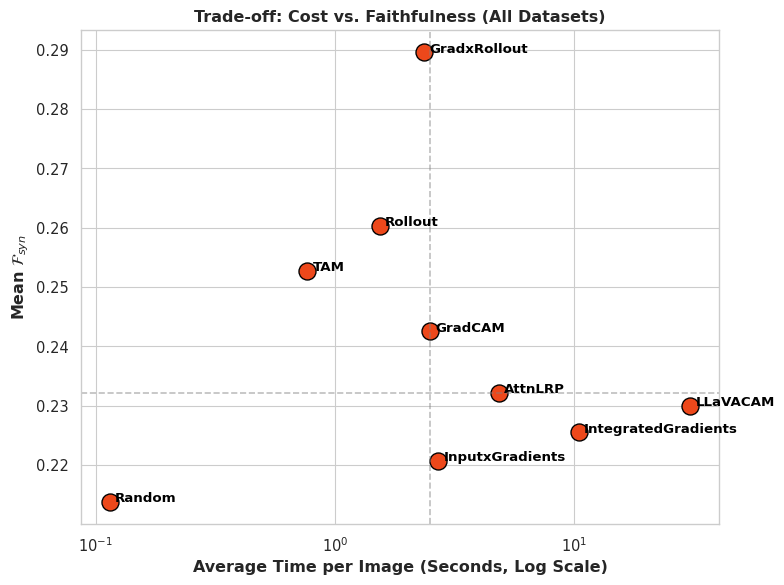

In [20]:
if 'xai_gen_time' in df.columns:
    plot_speed_vs_performance(df, perf_metric='syn_synergy_norm_auc', time_metric='xai_gen_time',
                              dataset_filter=None, savefig=False)


--- Generating Final Mean Rank Plot (Symbols Only) ---
[*] Saved ../figs/ranks_syn_synergy_norm_auc_global.pdf


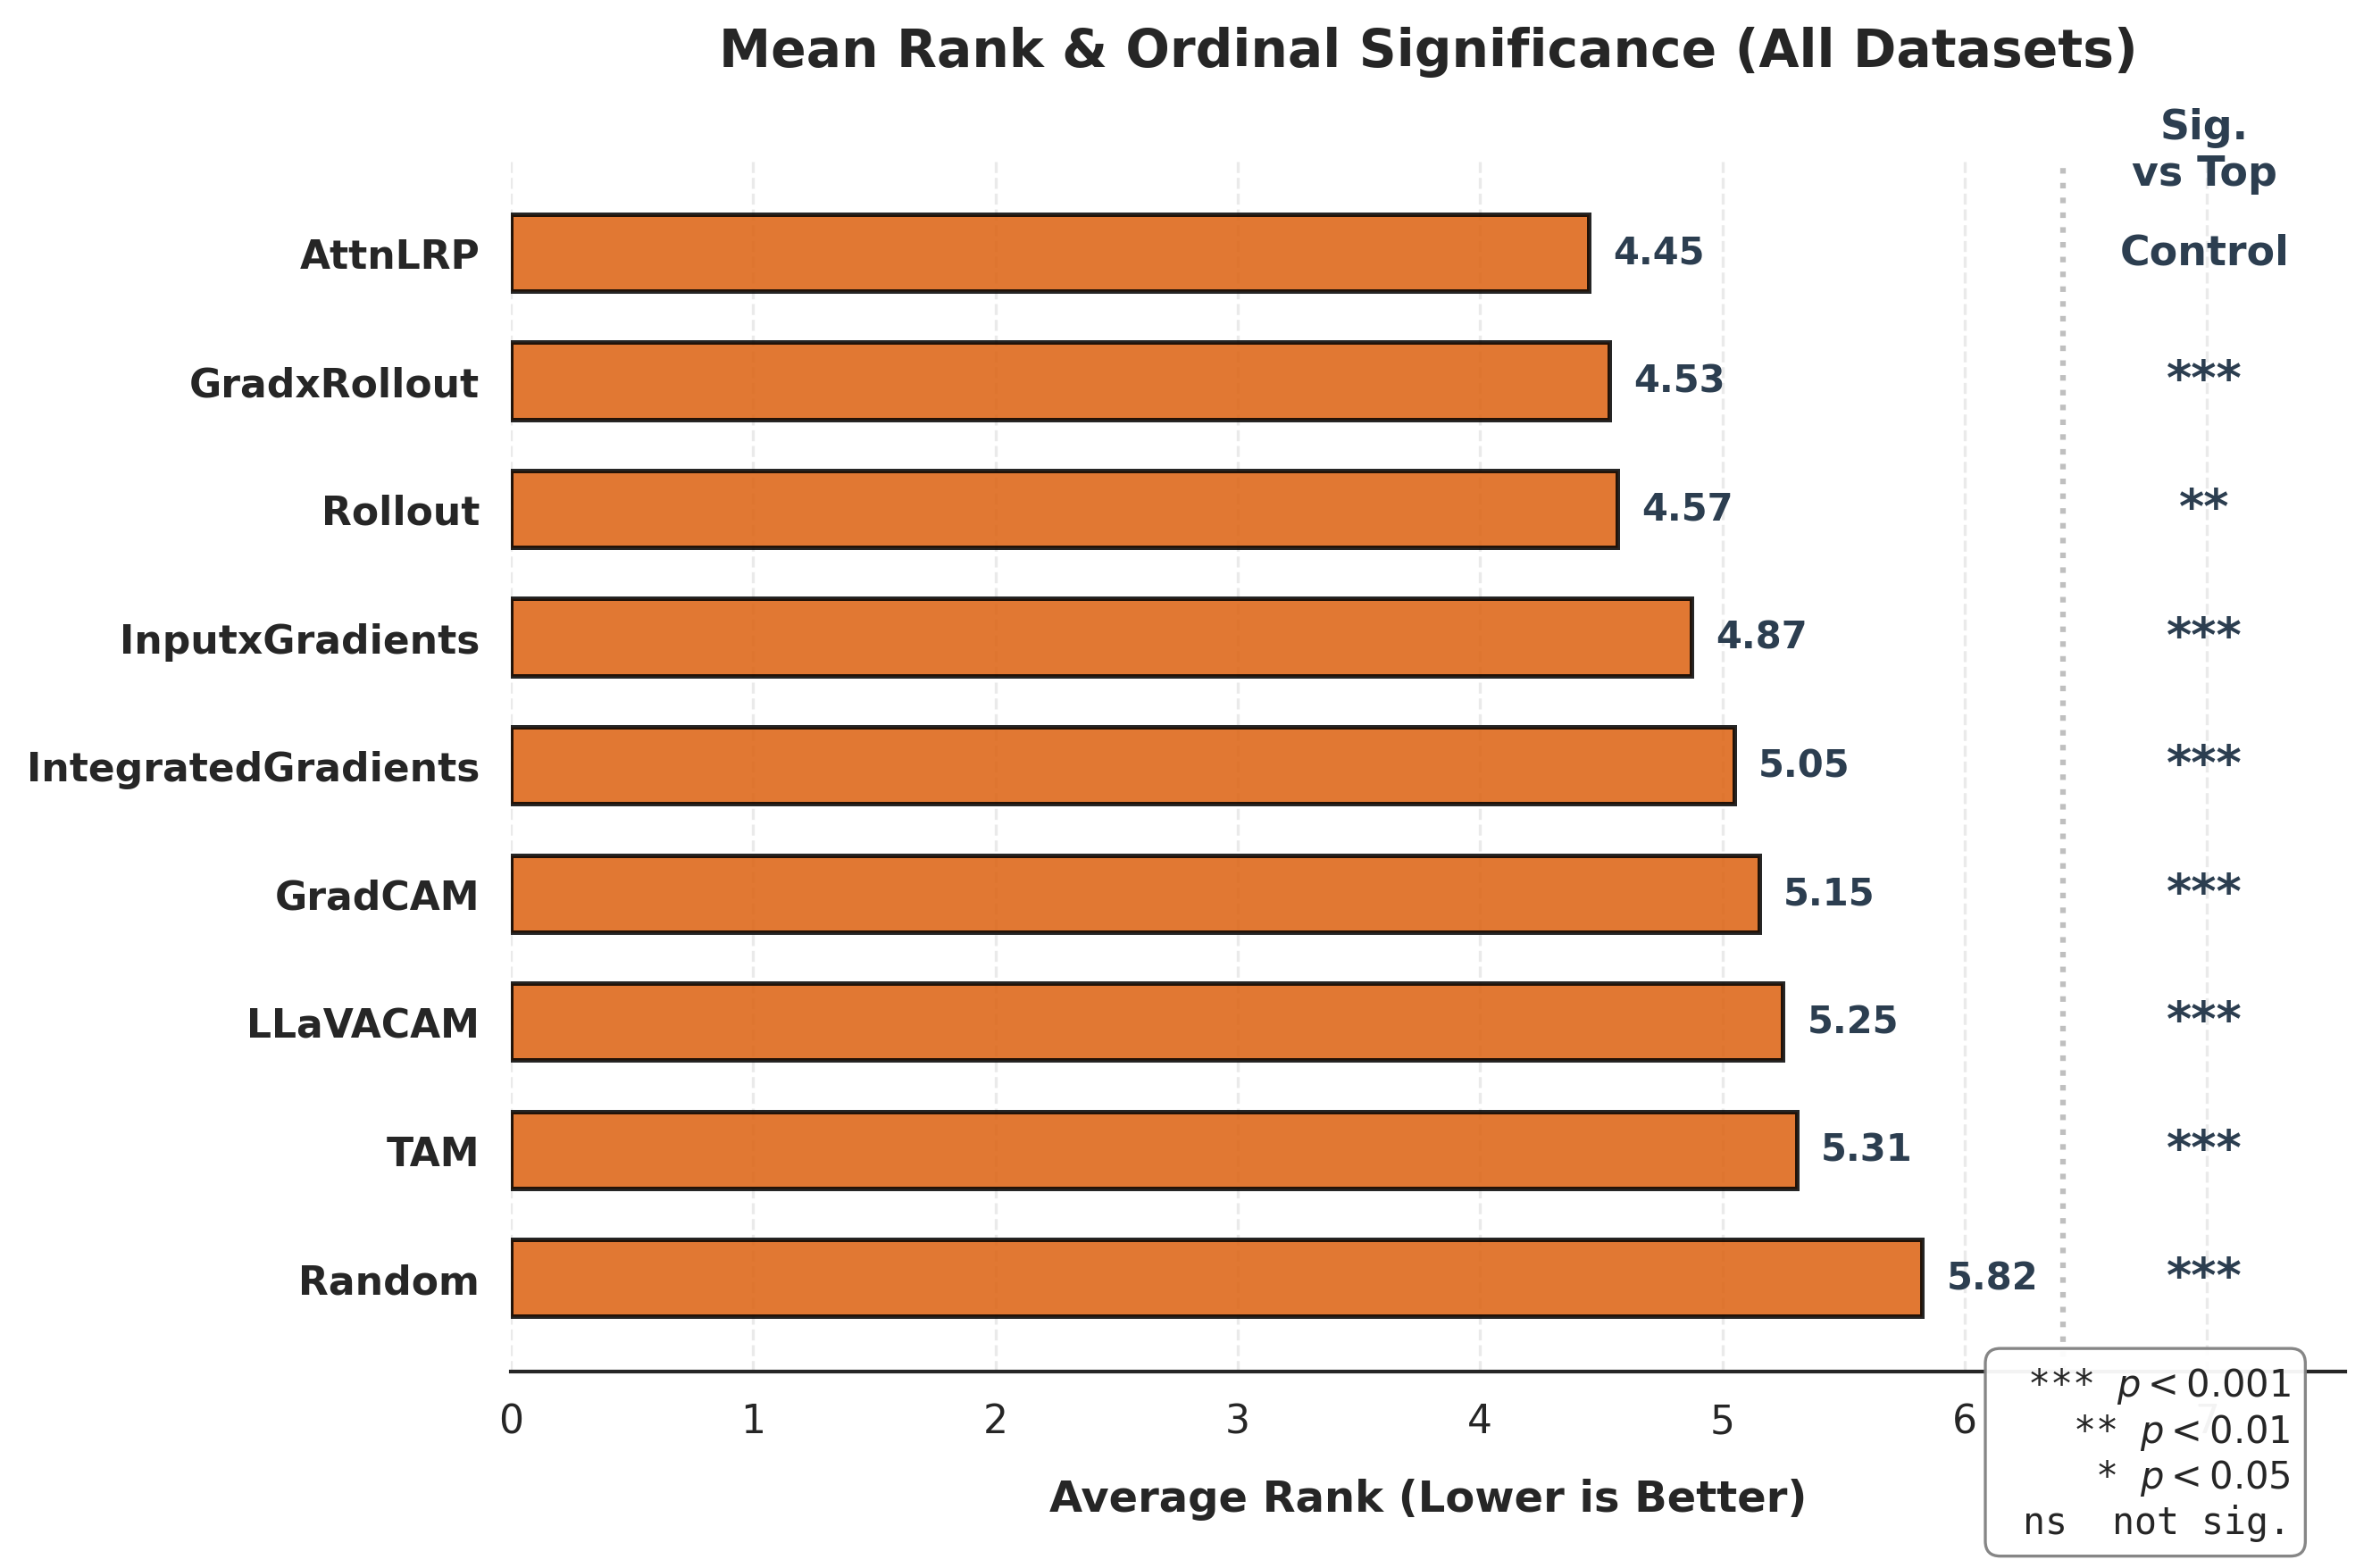

In [22]:
compute_and_plot_ranks(df, metric='syn_synergy_norm_auc',
                        ascending_metric=False, dataset_filter=None,
                        savefig=True)
